<a href="https://colab.research.google.com/github/Giriran25/TCMB/blob/main/NLm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [2]:
!git clone https://github.com/Giriran25/TCMB.git
%cd TCMB

Cloning into 'TCMB'...
remote: Enumerating objects: 43, done.
remote: Counting objects: 100% (43/43), done.
remote: Compressing objects: 100% (38/38), done.
remote: Total 43 (delta 3), reused 43 (delta 3), pack-reused 0 (from 0)
Receiving objects: 100% (43/43), 1.44 MiB | 1.83 MiB/s, done.
Resolving deltas: 100% (3/3), done.
/content/TCMB


In [3]:
!pip install datasets transformers sentencepiece huggingface_hub pandas numpy scipy scikit-learn matplotlib tqdm regex opencc-python-reimplemented accelerate

In [4]:
!pwd
!find . -maxdepth 2 -type f | sort

/content/TCMB
./baselines/language_id_baseline.py
./baselines/static_xlmr.py
./evaluation/classification_metrics.py
./evaluation/profiling.py
./evaluation/statistical_analysis.py
./evaluation/tokenization_metrics.py
./.git/config
./.git/description
./.git/HEAD
./.gitignore
./.git/index
./.git/packed-refs
./notebooks/baseline_analysis.ipynb
./README.md
./requirements.txt
./scripts/audit_dataset_overlap.py
./scripts/collect_calibration_pilot.py
./scripts/diagnose_calibration_quality.py
./scripts/download_datasets.py
./scripts/inspect_calibration_samples.py
./scripts/inspect_calibration_sources.py
./scripts/inspect_chinese_variants.py
./scripts/validate_calibration_pilot.py
./tcmb/anchor_constraints.py
./tcmb/budget_predictor.py
./tcmb/composer.py
./tcmb/__init__.py
./tcmb/pair_scorer.py
./tcmb/typological_features.py
./training/leave_one_out.py
./training/train_composer.py
./training/train_tcmb.py


In [5]:
import torch
import transformers
import datasets
import pandas
import numpy
import sklearn
import sentencepiece

print("All imports successful!")
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

All imports successful!
PyTorch: 2.11.0+cu130
CUDA: True
GPU: Tesla T4


In [7]:
from huggingface_hub import notebook_login

notebook_login()

In [8]:
from huggingface_hub import whoami

print(whoami())

{'type': 'user', 'id': '69d54b62bd2bdf61c0bf335c', 'name': 'giriranrk28', 'fullname': 'Ranjith Kumar G', 'canPay': False, 'billingMode': 'prepaid', 'periodEnd': 1796083200, 'isPro': False, 'avatarUrl': '/avatars/0bce33f412760f7bc73c3470af3d479f.svg', 'orgs': [], 'auth': {'type': 'oauth', 'expiresAt': '2026-12-05T08:28:26.000Z'}}


In [9]:
!sed -n '1,240p' scripts/download_datasets.py

from pathlib import Path
from datasets import load_dataset
import shutil

DATASETS = {
    "flores_plus": {
        "repository": "openlanguagedata/flores_plus",
        "languages": [
            "eng_Latn",
            "tam_Taml",
            "tel_Telu",
            "kan_Knda",
            "mal_Mlym",
            "hin_Deva",
            "cmn_Hans",
            "jpn_Jpan"
        ]
    },

    "sib200": {
        "repository": "Davlan/sib200",
        "languages": [
            "eng_Latn",
            "tam_Taml",
            "tel_Telu",
            "kan_Knda",
            "mal_Mlym",
            "hin_Deva",
            "zho_Hans",
            "jpn_Jpan"
        ]
    }
}

BASE_DIR = Path("data")


def download_dataset(dataset_name, repository, language):

    output_dir = BASE_DIR / dataset_name / language
    manifest = output_dir / "dataset_dict.json"

    if manifest.exists():
        print(f"[EXISTS] {dataset_name}/{language}")
        return True

    print(f"\nDownloading {datas

In [10]:
from scripts.download_datasets import download_dataset, DATASETS

languages = DATASETS["flores_plus"]["languages"]

for language in languages:
    download_dataset(
        dataset_name="flores_plus",
        repository=DATASETS["flores_plus"]["repository"],
        language=language
    )

README.md:   0%|          | 0.00/75.5k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/233 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/228 [00:00<?, ?it/s]

eng_Latn.jsonl:   0%|          | 0.00/423k [00:00<?, ?B/s]

eng_Latn.jsonl:   0%|          | 0.00/440k [00:00<?, ?B/s]

Generating dev split: 0 examples [00:00, ? examples/s]

... (63 outputs left out)

Generating devtest split: 0 examples [00:00, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/997 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/1012 [00:00<?, ? examples/s]

[SAVED] data/flores_plus/jpn_Jpan
  dev: 997 examples
  devtest: 1012 examples


In [11]:
from pathlib import Path
from datasets import load_from_disk

base = Path("data/flores_plus")

for language_dir in sorted(base.iterdir()):
    if language_dir.is_dir() and not language_dir.name.endswith(".partial"):
        dataset = load_from_disk(str(language_dir))

        print(f"\nLanguage: {language_dir.name}")

        for split, data in dataset.items():
            print(f"{split}: {len(data)} examples")


Language: cmn_Hans
dev: 997 examples
devtest: 1012 examples

Language: eng_Latn
dev: 997 examples
devtest: 1012 examples

Language: hin_Deva
dev: 997 examples
devtest: 1012 examples

Language: jpn_Jpan
dev: 997 examples
devtest: 1012 examples

Language: kan_Knda
dev: 997 examples
devtest: 1012 examples

Language: mal_Mlym
dev: 997 examples
devtest: 1012 examples

Language: tam_Taml
dev: 997 examples
devtest: 1012 examples

Language: tel_Telu
dev: 997 examples
devtest: 1012 examples


In [14]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [15]:
!python -m baselines.static_xlmr --help

usage: static_xlmr.py [-h] [--split {dev,devtest}] [--batch-size BATCH_SIZE]

Evaluate static XLM-R tokenization across eight FLORES+ languages.

options:
  -h, --help            show this help message and exit
  --split {dev,devtest}
                        FLORES+ dataset split.
  --batch-size BATCH_SIZE
                        Number of sentences processed per batch.


In [16]:
!ls -lh results/tables
!ls -lh results/figures

total 3.1M
-rw-r--r-- 1 root root 1.8K Nov  5 08:24 calibration_pilot_summary.csv
-rw-r--r-- 1 root root  975 Nov  5 08:24 calibration_pilot_validation.csv
-rw-r--r-- 1 root root 440K Nov  5 08:24 calibration_quality_sample_metadata.csv
-rw-r--r-- 1 root root 1.9K Nov  5 08:24 calibration_quality_summary.csv
-rw-r--r-- 1 root root 1.9M Nov  5 08:24 dataset_overlap_details.csv
-rw-r--r-- 1 root root 6.4K Nov  5 08:24 dataset_overlap_summary.csv
-rw-r--r-- 1 root root 790K Nov  5 08:24 static_xlmr_sentence_metrics_dev.csv
-rw-r--r-- 1 root root 2.2K Nov  5 08:24 static_xlmr_summary_dev.csv
total 684K
-rw-r--r-- 1 root root 145K Nov  5 08:24 static_xlmr_content_tokens_per_grapheme_dev.png
-rw-r--r-- 1 root root 128K Nov  5 08:24 static_xlmr_content_whitespace_fertility_dev.png
-rw-r--r-- 1 root root 142K Nov  5 08:24 static_xlmr_marker_share_dev.png
-rw-r--r-- 1 root root 140K Nov  5 08:24 static_xlmr_token_to_grapheme_dev.png
-rw-r--r-- 1 root root 122K Nov  5 08:24 static_xlmr_whitespac

In [17]:
!grep -nE "load_from_disk|load_dataset|from_pretrained|cuda|device|save_to_disk|output_dir|DATA_DIR" baselines/static_xlmr.py

28:from datasets import load_from_disk
116:    dataset_dict = load_from_disk(str(dataset_path))
493:    tokenizer = AutoTokenizer.from_pretrained(


In [18]:
!find data/flores_plus -maxdepth 2 -type f | head -30

data/flores_plus/eng_Latn/dataset_dict.json
data/flores_plus/hin_Deva/dataset_dict.json
data/flores_plus/kan_Knda/dataset_dict.json
data/flores_plus/jpn_Jpan/dataset_dict.json
data/flores_plus/tel_Telu/dataset_dict.json
data/flores_plus/cmn_Hans/dataset_dict.json
data/flores_plus/mal_Mlym/dataset_dict.json
data/flores_plus/tam_Taml/dataset_dict.json


In [19]:
!sed -n '90,135p' baselines/static_xlmr.py
!sed -n '470,560p' baselines/static_xlmr.py
!tail -100 baselines/static_xlmr.py

        Dataset split: dev or devtest.

    batch_size:
        Number of sentences processed per batch.

    Returns
    -------
    tuple:
        Language summary and sentence-level records.
    """

    dataset_path = (
        project_root
        / "data"
        / "flores_plus"
        / language_code
    )

    # Check whether the dataset exists.
    if not dataset_path.exists():
        raise FileNotFoundError(
            f"Dataset folder not found: {dataset_path}"
        )

    print(f"\nLoading dataset: {language_code}")

    dataset_dict = load_from_disk(str(dataset_path))

    # Check split availability.
    if split_name not in dataset_dict:
        raise ValueError(
            f"Split '{split_name}' not found for {language_code}. "
            f"Available splits: {list(dataset_dict.keys())}"
        )

    dataset = dataset_dict[split_name]

    # Check required columns.
    required_columns = {"id", "text"}

    missing_columns = required_columns - set(
        datas

In [20]:
from pathlib import Path
import shutil

backup = Path("results/backup_before_colab_rerun")
backup.mkdir(parents=True, exist_ok=True)

for folder in ["tables", "figures"]:
    source = Path("results") / folder
    if source.exists():
        shutil.copytree(
            source,
            backup / folder,
            dirs_exist_ok=True
        )

print("Existing results backed up successfully!")

Existing results backed up successfully!


In [21]:
!python -m baselines.static_xlmr --split dev --batch-size 32

TCMB - STATIC XLM-R TOKENIZATION BASELINE
Model: FacebookAI/xlm-roberta-base
Dataset split: dev
Batch size: 32

Loading XLM-R tokenizer...
config.json: 100% 615/615 [00:00<00:00, 2.02MB/s]
tokenizer_config.json: 100% 25.0/25.0 [00:00<00:00, 86.0kB/s]
sentencepiece.bpe.model: 100% 5.07M/5.07M [00:00<00:00, 5.30MB/s]
tokenizer.json: 100% 9.10M/9.10M [00:00<00:00, 21.1MB/s]
Tokenizer loaded successfully.
Vocabulary size: 250002
Standalone marker: ['▁']
Standalone marker ID: 6

Loading dataset: eng_Latn

Evaluating English (eng_Latn) - dev
English: 100% 32/32 [00:00<00:00, 178.41it/s]
Completed English: 997 sentences

Loading dataset: tam_Taml

Evaluating Tamil (tam_Taml) - dev
Tamil: 100% 32/32 [00:00<00:00, 86.56it/s]
Completed Tamil: 997 sentences

Loading dataset: tel_Telu

Evaluating Telugu (tel_Telu) - dev
Telugu: 100% 32/32 [00:00<00:00, 75.88it/s]
Completed Telugu: 997 sentences

Loading dataset: kan_Knda

Evaluating Kannada (kan_Knda) - dev
Kannada: 100% 32/32 [00:00<00:00, 74.99i

In [22]:
import torch
from transformers import AutoTokenizer, AutoModel

MODEL_NAME = "FacebookAI/xlm-roberta-base"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("GPU:", torch.cuda.get_device_name(0))

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModel.from_pretrained(MODEL_NAME)
model = model.to(device)
model.eval()

text = "This is a test sentence for TCMB."

inputs = tokenizer(
    text,
    return_tensors="pt"
).to(device)

with torch.no_grad():
    # Extract pretrained token embeddings
    embeddings = model.get_input_embeddings()(
        inputs["input_ids"]
    )

    # Run XLM-R using inputs_embeds
    outputs = model(
        inputs_embeds=embeddings,
        attention_mask=inputs["attention_mask"]
    )

print("\nGPU verification successful!")
print("Input IDs shape:", inputs["input_ids"].shape)
print("Embedding shape:", embeddings.shape)
print("Output shape:", outputs.last_hidden_state.shape)
print("Embedding dimension:", embeddings.shape[-1])
print(
    "GPU memory allocated:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)

Device: cuda
GPU: Tesla T4


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



GPU verification successful!
Input IDs shape: torch.Size([1, 11])
Embedding shape: torch.Size([1, 11, 768])
Output shape: torch.Size([1, 11, 768])
Embedding dimension: 768
GPU memory allocated: 1.04 GB


In [23]:
# Get original token embeddings
input_ids = inputs["input_ids"]
attention_mask = inputs["attention_mask"]

# Identify special tokens
special_mask = tokenizer.get_special_tokens_mask(
    input_ids[0].tolist(),
    already_has_special_tokens=True
)

# Find two adjacent non-special tokens
merge_position = next(
    i for i in range(1, len(special_mask) - 2)
    if special_mask[i] == 0
    and special_mask[i + 1] == 0
)

# Simple mean composition for testing only
merged_embedding = (
    embeddings[:, merge_position:merge_position + 1, :]
    + embeddings[:, merge_position + 1:merge_position + 2, :]
) / 2

# Create a shorter embedding sequence
short_embeddings = torch.cat([
    embeddings[:, :merge_position, :],
    merged_embedding,
    embeddings[:, merge_position + 2:, :]
], dim=1)

# Update attention mask
short_attention_mask = torch.ones(
    short_embeddings.shape[:2],
    dtype=torch.long,
    device=device
)

# Pass the shorter sequence to XLM-R
with torch.no_grad():
    merged_outputs = model(
        inputs_embeds=short_embeddings,
        attention_mask=short_attention_mask
    )

print("Original sequence length:", embeddings.shape[1])
print("Merged sequence length:", short_embeddings.shape[1])
print("Original embedding shape:", embeddings.shape)
print("Merged embedding shape:", short_embeddings.shape)
print("Transformer output shape:", merged_outputs.last_hidden_state.shape)

Original sequence length: 11
Merged sequence length: 10
Original embedding shape: torch.Size([1, 11, 768])
Merged embedding shape: torch.Size([1, 10, 768])
Transformer output shape: torch.Size([1, 10, 768])


In [24]:
!cat tcmb/composer.py
!cat tcmb/pair_scorer.py
!cat tcmb/budget_predictor.py

In [25]:
from pathlib import Path

files = [
    "tcmb/composer.py",
    "tcmb/pair_scorer.py",
    "tcmb/budget_predictor.py",
]

for filename in files:
    print("\n" + "=" * 70)
    print(filename)
    print("=" * 70)

    path = Path(filename)
    if path.exists():
        print(path.read_text())
    else:
        print("File not found!")


tcmb/composer.py


tcmb/pair_scorer.py


tcmb/budget_predictor.py



In [26]:
from pathlib import Path

files = [
    "tcmb/__init__.py",
    "tcmb/typological_features.py",
    "tcmb/anchor_constraints.py",
    "training/train_tcmb.py",
    "training/train_composer.py",
    "training/leave_one_out.py",
    "requirements.txt",
]

for filename in files:
    path = Path(filename)

    print("\n" + "=" * 75)
    print(filename)
    print("=" * 75)

    if path.exists():
        content = path.read_text()
        print(content if content.strip() else "[EMPTY FILE]")
    else:
        print("[FILE NOT FOUND]")


tcmb/__init__.py
[EMPTY FILE]

tcmb/typological_features.py
[EMPTY FILE]

tcmb/anchor_constraints.py
[EMPTY FILE]

training/train_tcmb.py
[EMPTY FILE]

training/train_composer.py
[EMPTY FILE]

training/leave_one_out.py
[EMPTY FILE]

requirements.txt
[EMPTY FILE]


In [27]:
from pathlib import Path

print("PROJECT DATA INVENTORY")
print("=" * 65)

for folder_name in ["data", "calibration", "results", "tcmb", "training"]:
    folder = Path(folder_name)

    print(f"\n{folder_name}/")

    if not folder.exists():
        print("  [Folder not found]")
        continue

    for path in sorted(folder.rglob("*")):
        if path.is_file():
            print(f"  {path} ({path.stat().st_size / 1024:.1f} KB)")

PROJECT DATA INVENTORY

data/
  data/flores_plus/cmn_Hans/dataset_dict.json (0.0 KB)
  data/flores_plus/cmn_Hans/dev/data-00000-of-00001.arrow (286.9 KB)
  data/flores_plus/cmn_Hans/dev/dataset_info.json (1.5 KB)
  data/flores_plus/cmn_Hans/dev/state.json (0.2 KB)
  data/flores_plus/cmn_Hans/devtest/data-00000-of-00001.arrow (300.0 KB)
  data/flores_plus/cmn_Hans/devtest/dataset_info.json (1.5 KB)
  data/flores_plus/cmn_Hans/devtest/state.json (0.2 KB)
  data/flores_plus/eng_Latn/dataset_dict.json (0.0 KB)
  data/flores_plus/eng_Latn/dev/data-00000-of-00001.arrow (294.8 KB)
  data/flores_plus/eng_Latn/dev/dataset_info.json (1.5 KB)
  data/flores_plus/eng_Latn/dev/state.json (0.2 KB)
  data/flores_plus/eng_Latn/devtest/data-00000-of-00001.arrow (311.1 KB)
  data/flores_plus/eng_Latn/devtest/dataset_info.json (1.5 KB)
  data/flores_plus/eng_Latn/devtest/state.json (0.2 KB)
  data/flores_plus/hin_Deva/dataset_dict.json (0.0 KB)
  data/flores_plus/hin_Deva/dev/data-00000-of-00001.arrow (48

In [28]:
import pandas as pd

path = Path("results/tables/calibration_pilot_summary.csv")

if path.exists():
    df = pd.read_csv(path)
    print("Calibration summary columns:")
    print(df.columns.tolist())
    display(df.head(10))
else:
    print("Calibration pilot summary not found.")

Calibration summary columns:
['language_code', 'language', 'source', 'configuration', 'target_tokens', 'actual_tokens', 'target_reached', 'accepted_documents', 'scanned_documents', 'unique_domains', 'short_documents_rejected', 'wrong_language_rejected', 'wrong_script_rejected', 'low_script_ratio_rejected', 'duplicate_documents_rejected', 'evaluation_overlaps_rejected', 'oversized_documents_rejected', 'invalid_documents_rejected', 'output_file']


,language_code,language,source,configuration,target_tokens,actual_tokens,target_reached,accepted_documents,scanned_documents,unique_domains,short_documents_rejected,wrong_language_rejected,wrong_script_rejected,low_script_ratio_rejected,duplicate_documents_rejected,evaluation_overlaps_rejected,oversized_documents_rejected,invalid_documents_rejected,output_file
0,eng_Latn,English,HuggingFaceFW/fineweb,sample-10BT,100000,100182,True,125,129,124,4,0,0,0,0,0,0,0,C:\Users\Ranjith Kumar G\Documents\TCMB\data\c...
1,tam_Taml,Tamil,HuggingFaceFW/fineweb-2,tam_Taml,100000,100125,True,110,112,101,1,0,0,0,0,0,1,0,C:\Users\Ranjith Kumar G\Documents\TCMB\data\c...
2,tel_Telu,Telugu,HuggingFaceFW/fineweb-2,tel_Telu,100000,101866,True,100,103,76,0,0,0,3,0,0,0,0,C:\Users\Ranjith Kumar G\Documents\TCMB\data\c...
3,kan_Knda,Kannada,HuggingFaceFW/fineweb-2,kan_Knda,100000,101433,True,135,136,77,0,0,0,1,0,0,0,0,C:\Users\Ranjith Kumar G\Documents\TCMB\data\c...
4,mal_Mlym,Malayalam,HuggingFaceFW/fineweb-2,mal_Mlym,100000,100697,True,151,153,101,0,0,0,2,0,0,0,0,C:\Users\Ranjith Kumar G\Documents\TCMB\data\c...
5,hin_Deva,Hindi,HuggingFaceFW/fineweb-2,hin_Deva,100000,100259,True,142,151,121,4,0,0,4,0,0,1,0,C:\Users\Ranjith Kumar G\Documents\TCMB\data\c...
6,cmn_Hans,Chinese,HuggingFaceFW/fineweb-2,cmn_Hani,100000,100576,True,112,135,110,21,0,0,1,0,0,1,0,C:\Users\Ranjith Kumar G\Documents\TCMB\data\c...
7,jpn_Jpan,Japanese,HuggingFaceFW/fineweb-2,jpn_Jpan,100000,100246,True,129,153,125,20,0,0,1,0,0,3,0,C:\Users\Ranjith Kumar G\Documents\TCMB\data\c...


In [29]:
import pandas as pd
from pathlib import Path

df = pd.read_csv("results/tables/calibration_pilot_summary.csv")

print("ORIGINAL CALIBRATION FILE PATHS")
print("=" * 70)

for _, row in df.iterrows():
    print(f"\n{row['language']}:")
    print(row["output_file"])

print("\n\nCALIBRATION COLLECTION SCRIPT")
print("=" * 70)

path = Path("scripts/collect_calibration_pilot.py")
lines = path.read_text().splitlines()

for i, line in enumerate(lines, 1):
    if any(word in line.lower() for word in [
        "output_file", "output_dir", "save", "jsonl",
        "write_text", "open(", "calibration"
    ]):
        print(f"{i}: {line}")

ORIGINAL CALIBRATION FILE PATHS

English:
C:\Users\Ranjith Kumar G\Documents\TCMB\data\calibration_pilot\eng_Latn\documents.jsonl

Tamil:
C:\Users\Ranjith Kumar G\Documents\TCMB\data\calibration_pilot\tam_Taml\documents.jsonl

Telugu:
C:\Users\Ranjith Kumar G\Documents\TCMB\data\calibration_pilot\tel_Telu\documents.jsonl

Kannada:
C:\Users\Ranjith Kumar G\Documents\TCMB\data\calibration_pilot\kan_Knda\documents.jsonl

Malayalam:
C:\Users\Ranjith Kumar G\Documents\TCMB\data\calibration_pilot\mal_Mlym\documents.jsonl

Hindi:
C:\Users\Ranjith Kumar G\Documents\TCMB\data\calibration_pilot\hin_Deva\documents.jsonl

Chinese:
C:\Users\Ranjith Kumar G\Documents\TCMB\data\calibration_pilot\cmn_Hans\documents.jsonl

Japanese:
C:\Users\Ranjith Kumar G\Documents\TCMB\data\calibration_pilot\jpn_Jpan\documents.jsonl


CALIBRATION COLLECTION SCRIPT
2: TCMB - Calibration Corpus Pilot Collection
22:     data/calibration_pilot/<language_code>/documents.jsonl
23:     results/tables/calibration_pilot_summ

In [34]:
%cd /content/TCMB

!python scripts/collect_calibration_pilot.py

/content/TCMB
TCMB - 100K TOKEN CALIBRATION PILOT
Model: FacebookAI/xlm-roberta-base
Target per language: 100000
Total target: 800000
Random seed: 42

COLLECTING: English
Loading FLORES+ exclusion index: eng_Latn
FLORES+ exclusion sentences: 2008
README.md: 100% 44.3k/44.3k [00:00<00:00, 50.7MB/s]
Resolving data files: 100% 27468/27468 [00:01<00:00, 17314.48it/s]
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1156 > 512). Running this sequence through the model will result in indexing errors
Accepted: 25 | Tokens: 17,024
Accepted: 50 | Tokens: 32,444
Accepted: 75 | Tokens: 44,617
Accepted: 100 | Tokens: 71,351
Accepted: 125 | Tokens: 91,340

Collection summary:
language_code: eng_Latn
language: English
source: HuggingFaceFW/fineweb
configuration: sample-10BT
target_tokens: 100000
actual_tokens: 100284
target_reached: True
accepted_documents: 140
scanned_documents: 146
unique_domains: 140
short_documents_rejected: 6
wron

In [35]:
from pathlib import Path
import json

base = Path("data/calibration_pilot")

languages = [
    "eng_Latn", "tam_Taml", "tel_Telu", "kan_Knda",
    "mal_Mlym", "hin_Deva", "cmn_Hans", "jpn_Jpan"
]

for lang in languages:
    path = base / lang / "documents.jsonl"

    count = 0
    with path.open(encoding="utf-8") as f:
        for line in f:
            if line.strip():
                json.loads(line)
                count += 1

    print(f"{lang}: {count} valid documents")

print("\nALL CALIBRATION FILES VERIFIED")

eng_Latn: 140 valid documents
tam_Taml: 157 valid documents
tel_Telu: 97 valid documents
kan_Knda: 118 valid documents
mal_Mlym: 165 valid documents
hin_Deva: 161 valid documents
cmn_Hans: 110 valid documents
jpn_Jpan: 92 valid documents

ALL CALIBRATION FILES VERIFIED


In [36]:
import json
from pathlib import Path

base = Path("data/calibration_pilot")

languages = [
    "eng_Latn", "tam_Taml", "tel_Telu", "kan_Knda",
    "mal_Mlym", "hin_Deva", "cmn_Hans", "jpn_Jpan"
]

for lang in languages:
    path = base / lang / "documents.jsonl"

    with path.open("r", encoding="utf-8") as f:
        record = json.loads(next(line for line in f if line.strip()))

    print("\n" + "=" * 60)
    print(lang)
    print("=" * 60)

    for key, value in record.items():
        if isinstance(value, str):
            print(f"{key}: {repr(value[:200])}")
        else:
            print(f"{key}: {type(value).__name__} = {value}")


eng_Latn
language_code: 'eng_Latn'
language: 'English'
source: 'HuggingFaceFW/fineweb'
configuration: 'sample-10BT'
document_id: '<urn:uuid:76920210-c1c1-499c-a448-c75d0c40bb3d>'
url: 'https://curvetoys.com/product/Jock-Mega-Anal-Plug-Vanilla'
domain: 'curvetoys.com'
date: '2023-02-08T13:22:56Z'
dump: 'CC-MAIN-2023-06'
language_score: float = 0.8106932044029236
minhash_cluster_size: NoneType = None
original_characters: int = 381
normalized_characters: int = 381
xlmr_token_count: int = 100
script_ratio: float = 1.0
normalized_text_sha256: 'aa329ad8058611a4e3073a42f99cd4c8c11e09bd034aa918d198849772072172'
chinese_conversion: 'not_applicable'
text: 'Solid and Smooth with Flared Base for Safety Strong Suction Cup Grips Any Flat SurfaceLow Maintenance and Easy to CleanUltra Durable Firm & PliableExclusively formulated PVCMade with USA Materials Cle'

tam_Taml
language_code: 'tam_Taml'
language: 'Tamil'
source: 'HuggingFaceFW/fineweb-2'
configuration: 'tam_Taml'
document_id: '<urn:uuid:49cb

In [37]:
import json
import re
from pathlib import Path
from collections import Counter

base = Path("data/calibration_pilot")

languages = [
    "eng_Latn", "tam_Taml", "tel_Telu", "kan_Knda",
    "mal_Mlym", "hin_Deva", "cmn_Hans", "jpn_Jpan"
]

# Initial domain-based screening terms.
# This is a screening heuristic, not a complete NSFW detector.
suspicious_terms = [
    "porn", "xxx", "adult", "escort", "erotic",
    "sex", "hentai", "camgirl", "webcam"
]

for lang in languages:
    path = base / lang / "documents.jsonl"

    records = [
        json.loads(line)
        for line in path.read_text(encoding="utf-8").splitlines()
        if line.strip()
    ]

    domains = Counter(r.get("domain", "") for r in records)

    flagged = [
        r for r in records
        if any(term in r.get("domain", "").lower()
               for term in suspicious_terms)
    ]

    clustered = [
        r for r in records
        if (r.get("minhash_cluster_size") or 1) > 1
    ]

    print("\n" + "=" * 65)
    print(lang)
    print("=" * 65)
    print("Documents:", len(records))
    print("Unique domains:", len(domains))
    print("Suspicious-domain matches:", len(flagged))
    print("Documents in MinHash clusters:", len(clustered))

    if flagged:
        print("\nFlagged domains:")
        for r in flagged:
            print("-", r.get("domain"), "|", r.get("url"))

    print("\nLargest domain counts:")
    print(domains.most_common(5))


eng_Latn
Documents: 140
Unique domains: 140
Suspicious-domain matches: 0
Documents in MinHash clusters: 0

Largest domain counts:
[('curvetoys.com', 1), ('www.hozpitality.com', 1), ('www.popsugar.com', 1), ('www.proprofs.com', 1), ('picsbypeep.com', 1)]

tam_Taml
Documents: 157
Unique domains: 120
Suspicious-domain matches: 0
Documents in MinHash clusters: 109

Largest domain counts:
[('tamil.oneindia.com', 9), ('www.dinamani.com', 6), ('www.dailythanthi.com', 4), ('www.puthiyathalaimurai.com', 3), ('www.maalaimalar.com', 3)]

tel_Telu
Documents: 97
Unique domains: 84
Suspicious-domain matches: 0
Documents in MinHash clusters: 78

Largest domain counts:
[('telugu.oneindia.com', 4), ('m.sakshi.com', 3), ('telugu.filmibeat.com', 2), ('kottapalli.in', 2), ('www.cinemapolitics.com', 2)]

kan_Knda
Documents: 118
Unique domains: 77
Suspicious-domain matches: 0
Documents in MinHash clusters: 87

Largest domain counts:
[('kannada.oneindia.com', 6), ('www.kannadaprabha.com', 6), ('vijaykarnata

In [38]:
import json
import re
import hashlib
import pandas as pd

from pathlib import Path

BASE = Path("data/calibration_pilot")
OUTPUT = Path("results/tables")

OUTPUT.mkdir(parents=True, exist_ok=True)

LANGUAGES = [
    "eng_Latn", "tam_Taml", "tel_Telu", "kan_Knda",
    "mal_Mlym", "hin_Deva", "cmn_Hans", "jpn_Jpan"
]

# Conservative screening indicators.
# These flag candidates for review, not automatic deletion.
ADULT_PATTERNS = [
    r"\bporn(?:ography)?\b",
    r"\bxxx\b",
    r"\badult\s+(?:content|video|products?)\b",
    r"\bsex(?:ual)?\s+(?:content|video|products?)\b",
    r"\berotic\b",
    r"\bhentai\b",
    r"\bcamgirl\b",
    r"\besco?r?t\b",
    r"\bincest\b",
    r"\banal\s+plug\b",
    r"\bnude\s+(?:photo|video|image)\b",
    r"\bdesiscandals\b",
    r"\bcurvetoys\b",
]

ADULT_RE = re.compile(
    "|".join(ADULT_PATTERNS),
    flags=re.IGNORECASE
)

seen_hashes = {}
audit_records = []

for lang in LANGUAGES:

    file_path = BASE / lang / "documents.jsonl"

    with file_path.open("r", encoding="utf-8") as f:

        for line_number, line in enumerate(f, 1):

            if not line.strip():
                continue

            record = json.loads(line)

            text = record.get("text", "")
            domain = str(record.get("domain", "")).lower()
            url = str(record.get("url", "")).lower()

            # Exact normalized-text hash.
            text_hash = record.get("normalized_text_sha256")

            if not text_hash:
                text_hash = hashlib.sha256(
                    text.encode("utf-8")
                ).hexdigest()

            reasons = []

            # Check exact duplicate text across all languages.
            if text_hash in seen_hashes:
                reasons.append("exact_duplicate")
            else:
                seen_hashes[text_hash] = (
                    lang, record.get("document_id")
                )

            # Check domain, URL and text.
            searchable = " ".join([
                domain,
                url,
                text
            ])

            if ADULT_RE.search(searchable):
                reasons.append("possible_adult_content")

            # Preserve MinHash information for analysis.
            cluster_size = record.get("minhash_cluster_size")

            audit_records.append({
                "language_code": lang,
                "document_id": record.get("document_id"),
                "domain": domain,
                "text_hash": text_hash,
                "xlmr_token_count": record.get("xlmr_token_count"),
                "script_ratio": record.get("script_ratio"),
                "minhash_cluster_size": cluster_size,
                "flag_reasons": ";".join(reasons),
                "review_required": bool(reasons)
            })

audit_df = pd.DataFrame(audit_records)

audit_df.to_csv(
    OUTPUT / "calibration_document_quality_audit.csv",
    index=False
)

summary = (
    audit_df.groupby("language_code")
    .agg(
        documents=("document_id", "count"),
        exact_duplicates=("flag_reasons",
            lambda x: x.str.contains("exact_duplicate").sum()),
        adult_candidates=("flag_reasons",
            lambda x: x.str.contains("possible_adult_content").sum()),
        review_candidates=("review_required", "sum"),
        total_tokens=("xlmr_token_count", "sum"),
        unique_domains=("domain", "nunique")
    )
    .reset_index()
)

summary.to_csv(
    OUTPUT / "calibration_quality_audit_summary.csv",
    index=False
)

display(summary)

print("\nTotal documents:", len(audit_df))
print("Total review candidates:", audit_df["review_required"].sum())
print("\nAudit files saved successfully.")

,language_code,documents,exact_duplicates,adult_candidates,review_candidates,total_tokens,unique_domains
0,cmn_Hans,110,0,0,0,100202,101
1,eng_Latn,140,0,1,1,100284,140
2,hin_Deva,161,0,1,1,100101,141
3,jpn_Jpan,92,0,0,0,101207,92
4,kan_Knda,118,0,0,0,100061,77
5,mal_Mlym,165,0,0,0,102082,109
6,tam_Taml,157,0,0,0,100276,120
7,tel_Telu,97,0,1,1,100141,84



Total documents: 1040
Total review candidates: 3

Audit files saved successfully.


In [39]:
import json
import re
import pandas as pd
from pathlib import Path

base = Path("data/calibration_pilot")
output = Path("results/tables")
output.mkdir(parents=True, exist_ok=True)

languages = [
    "eng_Latn", "tam_Taml", "tel_Telu", "kan_Knda",
    "mal_Mlym", "hin_Deva", "cmn_Hans", "jpn_Jpan"
]

patterns = [
    r"\bporn(?:ography)?\b",
    r"\bxxx\b",
    r"\badult\s+(?:content|video|products?)\b",
    r"\berotic\b",
    r"\bhentai\b",
    r"\bincest\b",
    r"\bcamgirl\b",
    r"\besco?r?t\b",
    r"\banal\s+plug\b",
    r"\bcurvetoys\b",
    r"\bdesiscandals\b"
]

adult_regex = re.compile("|".join(patterns), re.I)

rows = []
seen_hashes = {}

for lang in languages:
    file_path = base / lang / "documents.jsonl"

    with file_path.open(encoding="utf-8") as f:
        for line in f:
            if not line.strip():
                continue

            r = json.loads(line)

            text = r.get("text", "")
            domain = r.get("domain", "")
            url = r.get("url", "")

            digest = r.get("normalized_text_sha256")

            if not digest:
                import hashlib
                digest = hashlib.sha256(
                    text.encode("utf-8")
                ).hexdigest()

            matches = adult_regex.findall(
                f"{domain} {url} {text}"
            )

            duplicate = digest in seen_hashes

            if not duplicate:
                seen_hashes[digest] = lang

            rows.append({
                "language": lang,
                "document_id": r.get("document_id"),
                "domain": domain,
                "tokens": r.get("xlmr_token_count", 0),
                "exact_duplicate": duplicate,
                "adult_keyword_match": bool(matches),
                "matched_terms": ";".join(set(matches)),
                "text_preview": text[:250]
            })

audit = pd.DataFrame(rows)

audit.to_csv(
    output / "calibration_document_quality_audit.csv",
    index=False
)

summary = audit.groupby("language").agg(
    documents=("document_id", "count"),
    exact_duplicates=("exact_duplicate", "sum"),
    adult_candidates=("adult_keyword_match", "sum"),
    total_tokens=("tokens", "sum")
).reset_index()

summary.to_csv(
    output / "calibration_quality_audit_summary.csv",
    index=False
)

print("QUALITY AUDIT SUMMARY")
display(summary)

print("\nDOCUMENTS FLAGGED FOR MANUAL REVIEW")
display(
    audit[
        audit["adult_keyword_match"] |
        audit["exact_duplicate"]
    ][[
        "language", "domain", "matched_terms", "text_preview"
    ]].head(30)
)

print("\nAudit completed. Original documents were not modified.")

QUALITY AUDIT SUMMARY


,language,documents,exact_duplicates,adult_candidates,total_tokens
0,cmn_Hans,110,0,0,100202
1,eng_Latn,140,0,1,100284
2,hin_Deva,161,0,1,100101
3,jpn_Jpan,92,0,0,101207
4,kan_Knda,118,0,0,100061
5,mal_Mlym,165,0,0,102082
6,tam_Taml,157,0,0,100276
7,tel_Telu,97,0,1,100141



DOCUMENTS FLAGGED FOR MANUAL REVIEW


,language,domain,matched_terms,text_preview
0,eng_Latn,curvetoys.com,curvetoys,Solid and Smooth with Flared Base for Safety S...
302,tel_Telu,te.orphek.com,XXX,ఓర్ఫెక్ అట్లాంటిక్లను ఉపయోగించి బ్రూస్ కొత్త వ...
677,hin_Deva,desiscandals.net,desiscandals,विदेशी सौतेली माँ को चोदा देसी बेटे ने बड़े बू...



Audit completed. Original documents were not modified.


In [40]:
import pandas as pd
import json
from pathlib import Path

audit_path = Path(
    "results/tables/calibration_document_quality_audit.csv"
)

audit = pd.read_csv(audit_path)

# Find flagged records
flagged = audit[
    audit["adult_keyword_match"] |
    audit["exact_duplicate"]
]

base = Path("data/calibration_pilot")

for _, row in flagged.iterrows():

    lang = row["language"]
    document_id = row["document_id"]

    file_path = base / lang / "documents.jsonl"

    with file_path.open("r", encoding="utf-8") as f:
        for line in f:
            record = json.loads(line)

            if record.get("document_id") == document_id:

                print("\n" + "=" * 65)
                print("Language:", lang)
                print("Document ID:", document_id)
                print("Domain:", record.get("domain"))
                print("URL:", record.get("url"))
                print("Matched terms:", row["matched_terms"])
                print("Duplicate:", row["exact_duplicate"])
                break


Language: eng_Latn
Document ID: <urn:uuid:76920210-c1c1-499c-a448-c75d0c40bb3d>
Domain: curvetoys.com
URL: https://curvetoys.com/product/Jock-Mega-Anal-Plug-Vanilla
Matched terms: curvetoys
Duplicate: False

Language: tel_Telu
Document ID: <urn:uuid:9962bc62-1956-4983-8aed-0fb9957fa951>
Domain: te.orphek.com
URL: https://te.orphek.com/bruce-new-system-using-the-orphek-atlantiks/
Matched terms: XXX
Duplicate: False

Language: hin_Deva
Document ID: <urn:uuid:bdea8d01-54ce-4c4d-8007-3003a5808fc1>
Domain: desiscandals.net
URL: https://desiscandals.net/videshi-sauteli-maa-ko-choda-desi-beta-ne/
Matched terms: desiscandals
Duplicate: False


In [41]:
import json
from pathlib import Path

path = Path("data/calibration_pilot/tel_Telu/documents.jsonl")

with path.open(encoding="utf-8") as f:
    for line in f:
        record = json.loads(line)

        if record.get("domain") == "te.orphek.com":
            text = record.get("text", "")

            print("Domain:", record["domain"])
            print("URL:", record["url"])
            print("Token count:", record["xlmr_token_count"])

            start = 0
            while True:
                pos = text.lower().find("xxx".lower(), start)

                if pos == -1:
                    break

                print("\nMatch context:")
                print(text[max(0, pos-150):pos+200])

                start = pos + 3

Domain: te.orphek.com
URL: https://te.orphek.com/bruce-new-system-using-the-orphek-atlantiks/
Token count: 936

Match context:
క్రయించనుంది. నేను ఆర్డఫ్క్ వైఫై అట్లాంటిక్స్ వెర్సెస్ యొక్క 2 ని కొనుగోలు చేసాను. మీరు నుండి 2.1b. నేను ప్రారంభించిన మాగ్ XX పంపులు తో 2 ఆక్వా సి EV-XXX skimmers కలిగి, నేను కూడా వారు 240 గాలన్ వంటి ఎక్కువ 18 గ్యాలన్ల మంచి ఇది ఒక SCA XXX స్కిమ్మెర్ ప్రయత్నించారు. నేను Orphek Helix X skimmers ఒకటి ప్రయత్నించండి ప్రేమిస్తారన్నాడు కానీ ఇప్పుడు కోసం న

Match context:
రు నుండి 2.1b. నేను ప్రారంభించిన మాగ్ XX పంపులు తో 2 ఆక్వా సి EV-XXX skimmers కలిగి, నేను కూడా వారు 240 గాలన్ వంటి ఎక్కువ 18 గ్యాలన్ల మంచి ఇది ఒక SCA XXX స్కిమ్మెర్ ప్రయత్నించారు. నేను Orphek Helix X skimmers ఒకటి ప్రయత్నించండి ప్రేమిస్తారన్నాడు కానీ ఇప్పుడు కోసం నేను నా పాత యూరో రీఫ్ CS 5000-XX మరియు అది బాగా పని, ఆక్వా సి కంటే చాలా తక్కువ శబ్దం మ


In [42]:
import json
import pandas as pd
from pathlib import Path

SOURCE = Path("data/calibration_pilot")
DEST = Path("data/calibration_clean")

languages = [
    "eng_Latn", "tam_Taml", "tel_Telu", "kan_Knda",
    "mal_Mlym", "hin_Deva", "cmn_Hans", "jpn_Jpan"
]

# Exact document IDs approved for exclusion
exclude_ids = {
    "eng_Latn": {
        "urn:uuid:76920210-c1c1-499c-a448-c75d0c40bb3d"
    },
    "hin_Deva": {
        "urn:uuid:bdea8d01-54ce-4c4d-8007-3003a5808fc1"
    }
}

summary = []
manifest = []

for lang in languages:
    source_file = SOURCE / lang / "documents.jsonl"
    output_dir = DEST / lang
    output_dir.mkdir(parents=True, exist_ok=True)

    output_file = output_dir / "documents.jsonl"

    kept = 0
    removed = 0
    total_tokens = 0
    domains = set()

    with source_file.open("r", encoding="utf-8") as fin, \
         output_file.open("w", encoding="utf-8") as fout:

        for line in fin:
            if not line.strip():
                continue

            record = json.loads(line)

            doc_id = record.get("document_id", "")
            doc_id = doc_id.replace("<", "").replace(">", "")

            if doc_id in exclude_ids.get(lang, set()):
                removed += 1

                manifest.append({
                    "language": lang,
                    "document_id": doc_id,
                    "decision": "excluded",
                    "reason": "confirmed_unsuitable_adult_content"
                })
                continue

            fout.write(
                json.dumps(record, ensure_ascii=False) + "\n"
            )

            kept += 1
            total_tokens += int(record.get("xlmr_token_count", 0))
            domains.add(record.get("domain", ""))

            if lang == "tel_Telu" and "XXX" in record.get("text", ""):
                decision = "retained"
                reason = "false_positive_keyword_match_aquarium_article"
            else:
                decision = "retained"
                reason = "passed_initial_quality_audit"

            manifest.append({
                "language": lang,
                "document_id": doc_id,
                "decision": decision,
                "reason": reason
            })

    summary.append({
        "language": lang,
        "original_documents": kept + removed,
        "removed_documents": removed,
        "clean_documents": kept,
        "clean_xlmr_tokens": total_tokens,
        "unique_domains": len(domains)
    })

summary_df = pd.DataFrame(summary)
manifest_df = pd.DataFrame(manifest)

Path("results/tables").mkdir(parents=True, exist_ok=True)

summary_df.to_csv(
    "results/tables/calibration_clean_summary.csv",
    index=False
)

manifest_df.to_csv(
    "results/tables/calibration_cleaning_manifest.csv",
    index=False
)

display(summary_df)

print("\nTotal clean documents:", summary_df["clean_documents"].sum())
print("Total clean tokens:", summary_df["clean_xlmr_tokens"].sum())
print("\nOriginal calibration files remain unchanged.")

,language,original_documents,removed_documents,clean_documents,clean_xlmr_tokens,unique_domains
0,eng_Latn,140,1,139,100184,139
1,tam_Taml,157,0,157,100276,120
2,tel_Telu,97,0,97,100141,84
3,kan_Knda,118,0,118,100061,77
4,mal_Mlym,165,0,165,102082,109
5,hin_Deva,161,1,160,100001,140
6,cmn_Hans,110,0,110,100202,101
7,jpn_Jpan,92,0,92,101207,92



Total clean documents: 1038
Total clean tokens: 804154

Original calibration files remain unchanged.


In [43]:

%%writefile tcmb/typological_features.py

"""
TCMB: Corpus-derived typological feature extraction.

Features are calculated from independent calibration documents.
No FLORES+ evaluation data is used for fitting these profiles.
"""

import argparse
import json
import unicodedata
from pathlib import Path
from collections import Counter

import regex
import pandas as pd
from transformers import AutoTokenizer


LANGUAGES = [
    "eng_Latn",
    "tam_Taml",
    "tel_Telu",
    "kan_Knda",
    "mal_Mlym",
    "hin_Deva",
    "cmn_Hans",
    "jpn_Jpan",
]

# Whitespace fertility is not treated as meaningful for these scripts.
WHITESPACE_METRIC_LANGUAGES = {
    "eng_Latn",
    "tam_Taml",
    "tel_Telu",
    "kan_Knda",
    "mal_Mlym",
    "hin_Deva",
}

SCRIPT_PATTERNS = {
    "latin": regex.compile(r"\p{Script=Latin}"),
    "devanagari": regex.compile(r"\p{Script=Devanagari}"),
    "tamil": regex.compile(r"\p{Script=Tamil}"),
    "telugu": regex.compile(r"\p{Script=Telugu}"),
    "kannada": regex.compile(r"\p{Script=Kannada}"),
    "malayalam": regex.compile(r"\p{Script=Malayalam}"),
    "han": regex.compile(r"\p{Script=Han}"),
    "hiragana": regex.compile(r"\p{Script=Hiragana}"),
    "katakana": regex.compile(r"\p{Script=Katakana}"),
}


def load_documents(file_path):
    """Read and validate a JSONL calibration file."""
    records = []

    with file_path.open("r", encoding="utf-8") as file:
        for line_number, line in enumerate(file, start=1):
            if not line.strip():
                continue

            try:
                record = json.loads(line)
            except json.JSONDecodeError as error:
                raise ValueError(
                    f"Invalid JSON at {file_path}:{line_number}"
                ) from error

            text = record.get("text")

            if not isinstance(text, str) or not text.strip():
                continue

            records.append(record)

    if not records:
        raise ValueError(f"No usable documents in {file_path}")

    return records


def count_graphemes(text):
    """Count visible non-whitespace grapheme clusters."""
    clusters = regex.findall(r"\X", text)
    return sum(not cluster.isspace() for cluster in clusters)


def count_script_letters(text):
    """Count Unicode letters by script."""
    counts = Counter()

    for char in text:
        if not unicodedata.category(char).startswith("L"):
            continue

        matched = False

        for script_name, pattern in SCRIPT_PATTERNS.items():
            if pattern.fullmatch(char):
                counts[script_name] += 1
                matched = True
                break

        if not matched:
            counts["other"] += 1

    return counts


def extract_language_profile(
    language_code,
    records,
    tokenizer,
    marker_id,
    batch_size=16,
):
    """
    Compute a language profile from calibration documents.

    Tokenization is performed without truncation or special tokens.
    """

    total_documents = 0
    total_tokens = 0
    total_markers = 0
    total_graphemes = 0
    total_whitespace_words = 0

    total_metadata_tokens = 0
    metadata_match_count = 0
    metadata_comparison_count = 0

    document_graphemes = []
    document_characters = []
    script_counts = Counter()

    texts = [record["text"] for record in records]

    for start in range(0, len(records), batch_size):
        batch_records = records[start:start + batch_size]
        batch_texts = texts[start:start + batch_size]

        encoded = tokenizer(
            batch_texts,
            add_special_tokens=False,
            padding=False,
            truncation=False,
        )

        for record, text, token_ids in zip(
            batch_records,
            batch_texts,
            encoded["input_ids"],
        ):
            grapheme_count = count_graphemes(text)

            if grapheme_count == 0:
                continue

            token_count = len(token_ids)
            marker_count = sum(
                token_id == marker_id for token_id in token_ids
            )

            total_documents += 1
            total_tokens += token_count
            total_markers += marker_count
            total_graphemes += grapheme_count

            document_graphemes.append(grapheme_count)
            document_characters.append(len(text))

            script_counts.update(count_script_letters(text))

            if language_code in WHITESPACE_METRIC_LANGUAGES:
                total_whitespace_words += len(text.split())

            # Compare actual tokenizer count with collection metadata.
            metadata_count = record.get("xlmr_token_count")

            if metadata_count is not None:
                metadata_comparison_count += 1
                total_metadata_tokens += int(metadata_count)

                if int(metadata_count) == token_count:
                    metadata_match_count += 1

    content_tokens = total_tokens - total_markers

    total_letters = sum(script_counts.values())

    profile = {
        "language_code": language_code,
        "document_count": total_documents,
        "total_xlmr_tokens": total_tokens,
        "total_content_tokens": content_tokens,
        "total_marker_tokens": total_markers,
        "total_nonspace_graphemes": total_graphemes,

        "raw_tokens_per_grapheme": (
            total_tokens / total_graphemes
        ),
        "content_tokens_per_grapheme": (
            content_tokens / total_graphemes
        ),
        "marker_token_share": (
            total_markers / total_tokens
            if total_tokens else 0.0
        ),

        "mean_document_graphemes": (
            sum(document_graphemes) / total_documents
        ),
        "mean_document_characters": (
            sum(document_characters) / total_documents
        ),

        "script_letter_count": total_letters,
    }

    if language_code in WHITESPACE_METRIC_LANGUAGES:
        profile["content_subwords_per_whitespace_word"] = (
            content_tokens / total_whitespace_words
            if total_whitespace_words else None
        )

        profile["mean_graphemes_per_whitespace_word"] = (
            total_graphemes / total_whitespace_words
            if total_whitespace_words else None
        )
    else:
        profile["content_subwords_per_whitespace_word"] = None
        profile["mean_graphemes_per_whitespace_word"] = None

    # Script proportions are calculated among Unicode letters.
    for script_name in list(SCRIPT_PATTERNS) + ["other"]:
        count = script_counts[script_name]

        profile[f"script_share_{script_name}"] = (
            count / total_letters if total_letters else 0.0
        )

    profile["token_metadata_comparison_count"] = (
        metadata_comparison_count
    )

    profile["token_metadata_match_rate"] = (
        metadata_match_count / metadata_comparison_count
        if metadata_comparison_count else None
    )

    profile["metadata_total_tokens"] = total_metadata_tokens

    return profile


def extract_all_profiles(
    corpus_dir,
    output_dir,
    model_name,
    batch_size=16,
):
    corpus_dir = Path(corpus_dir)
    output_dir = Path(output_dir)

    output_dir.mkdir(parents=True, exist_ok=True)

    print("Loading XLM-R tokenizer:", model_name)

    tokenizer = AutoTokenizer.from_pretrained(model_name)

    marker_id = tokenizer.convert_tokens_to_ids("▁")

    if tokenizer.convert_ids_to_tokens(marker_id) != "▁":
        raise ValueError("Unable to identify standalone SentencePiece marker.")

    print("Tokenizer vocabulary:", tokenizer.vocab_size)
    print("Standalone marker ID:", marker_id)

    profiles = []

    for language_code in LANGUAGES:
        file_path = (
            corpus_dir / language_code / "documents.jsonl"
        )

        if not file_path.exists():
            raise FileNotFoundError(file_path)

        print(f"\nExtracting profile: {language_code}")

        records = load_documents(file_path)

        profile = extract_language_profile(
            language_code=language_code,
            records=records,
            tokenizer=tokenizer,
            marker_id=marker_id,
            batch_size=batch_size,
        )

        profiles.append(profile)

        print(
            f"Documents: {profile['document_count']} | "
            f"Tokens: {profile['total_xlmr_tokens']} | "
            f"Content tokens/grapheme: "
            f"{profile['content_tokens_per_grapheme']:.4f}"
        )

    dataframe = pd.DataFrame(profiles)

    csv_path = output_dir / "typological_profiles.csv"
    json_path = output_dir / "typological_profiles.json"

    dataframe.to_csv(csv_path, index=False)

    with json_path.open("w", encoding="utf-8") as file:
        json.dump(
            profiles,
            file,
            ensure_ascii=False,
            indent=2,
        )

    print("\n" + "=" * 65)
    print("TYPOLOGICAL FEATURE EXTRACTION COMPLETED")
    print("=" * 65)

    print("Languages:", len(profiles))
    print("Total documents:", dataframe["document_count"].sum())
    print("Total XLM-R tokens:", dataframe["total_xlmr_tokens"].sum())

    print("\nSaved:")
    print(csv_path)
    print(json_path)

    return dataframe


def main():
    parser = argparse.ArgumentParser()

    parser.add_argument(
        "--corpus-dir",
        default="data/calibration_clean",
    )
    parser.add_argument(
        "--output-dir",
        default="results/tables",
    )
    parser.add_argument(
        "--model-name",
        default="FacebookAI/xlm-roberta-base",
    )
    parser.add_argument(
        "--batch-size",
        type=int,
        default=16,
    )

    args = parser.parse_args()

    if args.batch_size < 1:
        parser.error("--batch-size must be at least 1")

    extract_all_profiles(
        corpus_dir=args.corpus_dir,
        output_dir=args.output_dir,
        model_name=args.model_name,
        batch_size=args.batch_size,
    )


if __name__ == "__main__":
    main()


Overwriting tcmb/typological_features.py


In [44]:
!python -m tcmb.typological_features \
    --corpus-dir data/calibration_clean \
    --output-dir results/tables \
    --batch-size 16

Loading XLM-R tokenizer: FacebookAI/xlm-roberta-base
Tokenizer vocabulary: 250002
Standalone marker ID: 6

Extracting profile: eng_Latn
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1156 > 512). Running this sequence through the model will result in indexing errors
Documents: 139 | Tokens: 100184 | Content tokens/grapheme: 0.2842

Extracting profile: tam_Taml
Documents: 157 | Tokens: 100276 | Content tokens/grapheme: 0.4711

Extracting profile: tel_Telu
Documents: 97 | Tokens: 100141 | Content tokens/grapheme: 0.6675

Extracting profile: kan_Knda
Documents: 118 | Tokens: 100061 | Content tokens/grapheme: 0.5445

Extracting profile: mal_Mlym
Documents: 165 | Tokens: 102082 | Content tokens/grapheme: 0.6115

Extracting profile: hin_Deva
Documents: 160 | Tokens: 100001 | Content tokens/grapheme: 0.5703

Extracting profile: cmn_Hans
Documents: 110 | Tokens: 100202 | Content tokens/grapheme: 0.7069

Extracting profile: jpn_

In [45]:
import pandas as pd

profiles = pd.read_csv(
    "results/tables/typological_profiles.csv"
)

display(profiles[[
    "language_code",
    "document_count",
    "total_xlmr_tokens",
    "raw_tokens_per_grapheme",
    "content_tokens_per_grapheme",
    "marker_token_share",
    "content_subwords_per_whitespace_word",
    "mean_graphemes_per_whitespace_word",
    "script_share_latin",
    "script_share_devanagari",
    "script_share_tamil",
    "script_share_telugu",
    "script_share_kannada",
    "script_share_malayalam",
    "script_share_han",
    "script_share_hiragana",
    "script_share_katakana",
    "token_metadata_match_rate",
]])

,language_code,document_count,total_xlmr_tokens,raw_tokens_per_grapheme,content_tokens_per_grapheme,marker_token_share,content_subwords_per_whitespace_word,mean_graphemes_per_whitespace_word,script_share_latin,script_share_devanagari,script_share_tamil,script_share_telugu,script_share_kannada,script_share_malayalam,script_share_han,script_share_hiragana,script_share_katakana,token_metadata_match_rate
0,eng_Latn,139,100184,0.285682,0.284159,0.005330,1.403620,4.939559,0.999985,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.0
1,tam_Taml,157,100276,0.478971,0.471147,0.016335,2.284027,4.847798,0.015674,0.000000,0.984311,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.0
2,tel_Telu,97,100141,0.681844,0.667477,0.021070,2.287024,3.426372,0.022984,0.000645,0.000019,0.976302,0.000025,0.000025,0.000000,0.000000,0.000000,1.0
3,kan_Knda,118,100061,0.558037,0.544501,0.024255,2.472999,4.541768,0.024777,0.000000,0.000000,0.000000,0.975223,0.000000,0.000000,0.000000,0.000000,1.0
4,mal_Mlym,165,102082,0.626778,0.611477,0.024412,2.596939,4.246995,0.029748,0.000000,0.000000,0.000000,0.000000,0.970216,0.000000,0.000000,0.000000,1.0
5,hin_Deva,160,100001,0.577323,0.570257,0.012240,1.412270,2.476552,0.081127,0.918873,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.0
6,cmn_Hans,110,100202,0.726480,0.706927,0.026916,NaN,NaN,0.067186,0.000000,0.000000,0.000000,0.000000,0.000000,0.932789,0.000008,0.000000,1.0
7,jpn_Jpan,92,101207,0.579714,0.544429,0.060865,NaN,NaN,0.096499,0.000000,0.000000,0.000000,0.000000,0.000000,0.305068,0.401580,0.177047,1.0


In [46]:
%%writefile tcmb/anchor_constraints.py

"""
TCMB anchor constraints.

Protects important text spans from adjacent-token merging.
Uses tokenizer character offsets to identify protected token positions.
"""

import regex
from typing import Sequence


# Common currencies and currency codes.
CURRENCY_CODES = (
    r"USD|INR|EUR|GBP|JPY|CNY|AUD|CAD|"
    r"Rs\.?|INR|US\$"
)

NUMBER = r"[+-]?\p{N}+(?:[,.٫٬]\p{N}+)*"

ANCHOR_PATTERNS = [
    # URLs
    r"https?://[^\s]+|www\.[^\s]+",

    # Email addresses
    r"[\p{L}\p{N}._%+\-]+@[\p{L}\p{N}.\-]+\.[\p{L}]{2,}",

    # Dates: YYYY-MM-DD, DD/MM/YYYY, etc.
    r"(?<!\p{N})(?:"
    r"\p{N}{4}[-/.]\p{N}{1,2}[-/.]\p{N}{1,2}"
    r"|\p{N}{1,2}[-/.]\p{N}{1,2}[-/.]\p{N}{2,4}"
    r")(?!\p{N})",

    # Times
    r"(?<!\p{N})\p{N}{1,2}:\p{N}{2}(?::\p{N}{2})?(?!\p{N})",

    # Currency symbol before amount
    rf"(?<!\p{{L}})(?:[$€£¥₹₩₽₺]\s*{NUMBER})",

    # Currency code after amount
    rf"(?<!\p{{N}}){NUMBER}\s*(?:{CURRENCY_CODES})(?!\p{{L}})",

    # Currency code before amount
    rf"(?<!\p{{L}})(?:{CURRENCY_CODES})\s*{NUMBER}",

    # Percentages
    rf"(?<!\p{{N}}){NUMBER}\s*[%٪]",

    # Remaining numeric expressions
    rf"(?<!\p{{N}}){NUMBER}(?!\p{{N}})",
]

COMPILED_PATTERNS = [
    regex.compile(pattern, flags=regex.IGNORECASE)
    for pattern in ANCHOR_PATTERNS
]


def find_anchor_spans(text: str) -> list[tuple[int, int]]:
    """
    Return protected character spans as (start, end).

    Overlapping spans are merged.
    """
    if not isinstance(text, str):
        raise TypeError("text must be a string")

    spans = []

    for pattern in COMPILED_PATTERNS:
        for match in pattern.finditer(text):
            spans.append(match.span())

    spans.sort()

    merged = []

    for start, end in spans:
        if not merged or start > merged[-1][1]:
            merged.append([start, end])
        else:
            merged[-1][1] = max(merged[-1][1], end)

    return [(start, end) for start, end in merged]


def build_protected_token_mask(
    offset_mapping: Sequence,
    text: str,
    special_tokens_mask: Sequence | None = None,
) -> list[bool]:
    """
    Convert character-level anchor spans into a token-level mask.

    True means protected.
    False means eligible for consideration by the merge scorer.
    """
    anchor_spans = find_anchor_spans(text)

    protected = []

    for index, offset in enumerate(offset_mapping):
        start, end = int(offset[0]), int(offset[1])

        is_special = (
            special_tokens_mask is not None
            and bool(special_tokens_mask[index])
        )

        # Zero-length offsets are protected conservatively.
        if is_special or end <= start:
            protected.append(True)
            continue

        intersects_anchor = any(
            start < anchor_end and end > anchor_start
            for anchor_start, anchor_end in anchor_spans
        )

        protected.append(intersects_anchor)

    return protected


def is_merge_allowed(
    left_index: int,
    protected_mask: Sequence[bool],
) -> bool:
    """
    Check whether token i and token i+1 may be merged.
    """
    if left_index < 0 or left_index + 1 >= len(protected_mask):
        raise IndexError("Invalid adjacent token index")

    return not (
        protected_mask[left_index]
        or protected_mask[left_index + 1]
    )

Overwriting tcmb/anchor_constraints.py


In [47]:
from transformers import AutoTokenizer

from tcmb.anchor_constraints import (
    find_anchor_spans,
    build_protected_token_mask,
    is_merge_allowed,
)

tokenizer = AutoTokenizer.from_pretrained(
    "FacebookAI/xlm-roberta-base"
)

test_text = (
    "The price is ₹1,299.50 with a 20% discount. "
    "The meeting is on 2026-11-05 at 10:30. "
    "Contact test@example.com or visit https://example.com. "
    "These ordinary words can be considered for merging."
)

encoded = tokenizer(
    test_text,
    return_offsets_mapping=True,
    return_special_tokens_mask=True,
    add_special_tokens=True,
)

offsets = encoded["offset_mapping"]
special_mask = encoded["special_tokens_mask"]

protected = build_protected_token_mask(
    offsets,
    test_text,
    special_tokens_mask=special_mask,
)

print("Detected anchor spans:")

for start, end in find_anchor_spans(test_text):
    print(repr(test_text[start:end]))

print("\nToken-level protection:")

tokens = tokenizer.convert_ids_to_tokens(
    encoded["input_ids"]
)

for i, (token, is_protected) in enumerate(zip(tokens, protected)):
    print(
        f"{i:3d} | {token:20s} | "
        f"{'PROTECTED' if is_protected else 'ELIGIBLE'}"
    )

allowed_pairs = [
    i for i in range(len(protected) - 1)
    if is_merge_allowed(i, protected)
]

print("\nEligible adjacent merge positions:", allowed_pairs)
print("Protected tokens:", sum(protected))
print("Total tokens:", len(protected))

Detected anchor spans:
'₹1,299.50'
'20%'
'2026-11-05'
'10:30'
'test@example.com'
'https://example.com.'

Token-level protection:
  0 | <s>                  | PROTECTED
  1 | ▁The                 | ELIGIBLE
  2 | ▁price               | ELIGIBLE
  3 | ▁is                  | ELIGIBLE
  4 | ▁₹                   | PROTECTED
  5 | 1,2                  | PROTECTED
  6 | 99                   | PROTECTED
  7 | .                    | PROTECTED
  8 | 50                   | PROTECTED
  9 | ▁with                | ELIGIBLE
 10 | ▁a                   | ELIGIBLE
 11 | ▁20%                 | PROTECTED
 12 | ▁discount            | ELIGIBLE
 13 | .                    | ELIGIBLE
 14 | ▁The                 | ELIGIBLE
 15 | ▁meeting             | ELIGIBLE
 16 | ▁is                  | ELIGIBLE
 17 | ▁on                  | ELIGIBLE
 18 | ▁20                  | PROTECTED
 19 | 26                   | PROTECTED
 20 | -11-                 | PROTECTED
 21 | 05                   | PROTECTED
 22 | ▁at               

In [48]:
from pathlib import Path

path = Path("tcmb/anchor_constraints.py")
source = path.read_text(encoding="utf-8")

start = source.index("def find_anchor_spans(")
end = source.index("\ndef build_protected_token_mask(", start)

new_function = '''
def find_anchor_spans(text: str) -> list[tuple[int, int]]:
    """Return protected character spans, excluding trailing URL punctuation."""

    if not isinstance(text, str):
        raise TypeError("text must be a string")

    spans = []

    for index, pattern in enumerate(COMPILED_PATTERNS):
        for match in pattern.finditer(text):
            start, end = match.span()

            # The first pattern identifies URLs.
            # Keep sentence-ending punctuation outside the URL span.
            if index == 0:
                matched_text = text[start:end]
                trimmed = matched_text.rstrip(".,!?;:")
                end = start + len(trimmed)

            if end > start:
                spans.append((start, end))

    spans.sort()
    merged = []

    for start, end in spans:
        if not merged or start > merged[-1][1]:
            merged.append([start, end])
        else:
            merged[-1][1] = max(merged[-1][1], end)

    return [(start, end) for start, end in merged]

'''

source = source[:start] + new_function + source[end:]
path.write_text(source, encoding="utf-8")

print("Anchor URL punctuation correction applied.")

Anchor URL punctuation correction applied.


In [49]:
%%writefile tcmb/composer.py

"""
TCMB: Trainable embedding composition.

Combines two adjacent pretrained token embeddings into one
embedding in the same hidden space.
"""

import torch
import torch.nn as nn


class EmbeddingComposer(nn.Module):
    """
    Gated residual embedding composer.

    Input:
        left:  [..., hidden_dim]
        right: [..., hidden_dim]

    Output:
        [..., hidden_dim]
    """

    def __init__(
        self,
        hidden_dim: int = 768,
        bottleneck_dim: int = 256,
        residual_scale: float = 0.1,
    ):
        super().__init__()

        if hidden_dim <= 0 or bottleneck_dim <= 0:
            raise ValueError("Dimensions must be positive.")

        self.hidden_dim = hidden_dim
        self.residual_scale = residual_scale

        # Features: left, right, absolute difference, elementwise product.
        input_dim = hidden_dim * 4

        # Predicts how much weight to assign to the left embedding.
        self.gate_network = nn.Sequential(
            nn.Linear(input_dim, bottleneck_dim),
            nn.GELU(),
            nn.Linear(bottleneck_dim, 1),
        )

        # Learns a correction to the gated combination.
        self.residual_network = nn.Sequential(
            nn.Linear(input_dim, bottleneck_dim),
            nn.GELU(),
            nn.Linear(bottleneck_dim, hidden_dim),
        )

        # Start with an approximately equal combination.
        nn.init.zeros_(self.gate_network[-1].bias)

        # Initially, the residual correction is zero.
        nn.init.zeros_(self.residual_network[-1].weight)
        nn.init.zeros_(self.residual_network[-1].bias)

    def forward(self, left, right):
        if left.shape != right.shape:
            raise ValueError(
                f"Embedding shapes must match: "
                f"{left.shape} versus {right.shape}"
            )

        if left.shape[-1] != self.hidden_dim:
            raise ValueError(
                f"Expected hidden dimension {self.hidden_dim}, "
                f"received {left.shape[-1]}"
            )

        features = torch.cat(
            [
                left,
                right,
                torch.abs(left - right),
                left * right,
            ],
            dim=-1,
        )

        gate = torch.sigmoid(
            self.gate_network(features)
        )

        # Gated weighted combination.
        base = gate * left + (1.0 - gate) * right

        # Learned residual correction.
        residual = torch.tanh(
            self.residual_network(features)
        )

        return base + self.residual_scale * residual

    def forward_pair(self, pair_embeddings):
        """
        Convenience method.

        Input:  [..., 2, hidden_dim]
        Output: [..., hidden_dim]
        """
        if pair_embeddings.ndim < 2:
            raise ValueError("Expected a tensor with a pair dimension.")

        if pair_embeddings.shape[-2] != 2:
            raise ValueError(
                "The pair dimension must contain exactly two embeddings."
            )

        return self.forward(
            pair_embeddings[..., 0, :],
            pair_embeddings[..., 1, :],
        )

Overwriting tcmb/composer.py


In [50]:
import torch

from tcmb.composer import EmbeddingComposer

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

composer = EmbeddingComposer(
    hidden_dim=768,
    bottleneck_dim=256
).to(device)

# Simulate a batch of adjacent XLM-R embeddings.
left = torch.randn(4, 768, device=device)
right = torch.randn(4, 768, device=device)

# Compose two embeddings into one.
composed = composer(left, right)

print("Device:", device)
print("Left shape:", left.shape)
print("Right shape:", right.shape)
print("Composed shape:", composed.shape)

# Check gradient propagation.
loss = composed.square().mean()
loss.backward()

gradient_count = sum(
    parameter.grad is not None
    for parameter in composer.parameters()
)

print("\nGradient test:")
print("Loss:", loss.item())
print("Parameters receiving gradients:", gradient_count)
print(
    "All gradients finite:",
    all(
        torch.isfinite(parameter.grad).all().item()
        for parameter in composer.parameters()
        if parameter.grad is not None
    )
)

assert composed.shape == (4, 768)
assert gradient_count == len(list(composer.parameters()))

print("\nCOMPOSER TEST PASSED")

Device: cuda
Left shape: torch.Size([4, 768])
Right shape: torch.Size([4, 768])
Composed shape: torch.Size([4, 768])

Gradient test:
Loss: 0.4757835566997528
Parameters receiving gradients: 8
All gradients finite: True

COMPOSER TEST PASSED


In [51]:
sequence = torch.randn(2, 10, 768, device=device)

merged = composer(
    sequence[:, 4, :],
    sequence[:, 5, :]
).unsqueeze(1)

short_sequence = torch.cat(
    [
        sequence[:, :4, :],
        merged,
        sequence[:, 6:, :]
    ],
    dim=1
)

print("Original:", sequence.shape)
print("After merging:", short_sequence.shape)

assert short_sequence.shape == (2, 9, 768)

print("SEQUENCE COMPOSITION TEST PASSED")

Original: torch.Size([2, 10, 768])
After merging: torch.Size([2, 9, 768])
SEQUENCE COMPOSITION TEST PASSED


In [52]:

%%writefile tcmb/pair_scorer.py

"""
TCMB: Typology-conditioned adjacent pair scorer.

Input:
    Left and right token embeddings
    Language-level calibration profile

Output:
    Merge logits and probabilities for adjacent pairs.

The model is not trained in this module.
"""

import torch
import torch.nn as nn


PROFILE_FEATURES = [
    "raw_tokens_per_grapheme",
    "content_tokens_per_grapheme",
    "marker_token_share",
    "mean_document_graphemes",
    "script_share_latin",
    "script_share_devanagari",
    "script_share_tamil",
    "script_share_telugu",
    "script_share_kannada",
    "script_share_malayalam",
    "script_share_han",
    "script_share_hiragana",
    "script_share_katakana",
    "script_share_other",
]


class TypologyConditionedPairScorer(nn.Module):
    """
    Assigns merge suitability scores to adjacent embedding pairs.

    Expected pair embedding shape: [batch, pairs, hidden_dim]
    Expected profile shape: [batch, profile_dim] or [profile_dim]
    """

    def __init__(
        self,
        hidden_dim=768,
        profile_dim=14,
        bottleneck_dim=256,
        dropout=0.1,
    ):
        super().__init__()

        if hidden_dim <= 0:
            raise ValueError("hidden_dim must be positive.")

        if profile_dim <= 0:
            raise ValueError("profile_dim must be positive.")

        if bottleneck_dim <= 0:
            raise ValueError("bottleneck_dim must be positive.")

        self.hidden_dim = hidden_dim
        self.profile_dim = profile_dim

        # Four feature groups:
        # left, right, absolute difference and element-wise product.
        self.pair_encoder = nn.Sequential(
            nn.Linear(hidden_dim * 4, bottleneck_dim),
            nn.LayerNorm(bottleneck_dim),
            nn.GELU(),
            nn.Dropout(dropout),
        )

        # Encodes the corpus-derived language profile.
        self.profile_encoder = nn.Sequential(
            nn.Linear(profile_dim, bottleneck_dim),
            nn.LayerNorm(bottleneck_dim),
            nn.GELU(),
        )

        # Predicts a merge suitability logit.
        self.score_head = nn.Sequential(
            nn.Linear(bottleneck_dim, bottleneck_dim // 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(bottleneck_dim // 2, 1),
        )

    def forward(self, left, right, profile):
        if left.shape != right.shape:
            raise ValueError(
                "Left and right embedding shapes must match."
            )

        if left.ndim != 3:
            raise ValueError(
                "Expected embeddings with shape [batch, pairs, hidden_dim]."
            )

        if left.shape[-1] != self.hidden_dim:
            raise ValueError(
                f"Expected hidden dimension {self.hidden_dim}."
            )

        batch_size = left.shape[0]

        if profile.ndim == 1:
            profile = profile.unsqueeze(0).expand(
                batch_size, -1
            )

        if profile.ndim != 2:
            raise ValueError(
                "Profile must have shape [profile_dim] or "
                "[batch, profile_dim]."
            )

        if profile.shape != (batch_size, self.profile_dim):
            raise ValueError(
                f"Expected profile shape "
                f"[{batch_size}, {self.profile_dim}], "
                f"received {tuple(profile.shape)}."
            )

        if profile.device != left.device:
            raise ValueError("Profile and embeddings must share a device.")

        if profile.dtype != left.dtype:
            raise ValueError("Profile and embeddings must share a dtype.")

        # Construct pair-level features.
        pair_features = torch.cat(
            [
                left,
                right,
                torch.abs(left - right),
                left * right,
            ],
            dim=-1,
        )

        pair_representation = self.pair_encoder(pair_features)

        # Encode one profile per language/example.
        profile_representation = self.profile_encoder(profile)

        # Broadcast profile representation across adjacent pairs.
        conditioned_representation = (
            pair_representation
            + profile_representation.unsqueeze(1)
        )

        logits = self.score_head(
            conditioned_representation
        ).squeeze(-1)

        probabilities = torch.sigmoid(logits)

        return logits, probabilities

    def score_sequence(
        self,
        embeddings,
        profile,
        valid_pair_mask=None,
    ):
        """
        Score every adjacent pair in an embedding sequence.

        embeddings: [batch, sequence_length, hidden_dim]

        valid_pair_mask: [batch, sequence_length - 1]
            True means the pair is eligible for merging.
        """
        if embeddings.ndim != 3:
            raise ValueError(
                "Expected [batch, sequence_length, hidden_dim]."
            )

        if embeddings.shape[1] < 2:
            raise ValueError(
                "Sequence must contain at least two positions."
            )

        left = embeddings[:, :-1, :]
        right = embeddings[:, 1:, :]

        logits, probabilities = self.forward(
            left,
            right,
            profile,
        )

        if valid_pair_mask is not None:
            if valid_pair_mask.shape != logits.shape:
                raise ValueError(
                    "valid_pair_mask must have shape "
                    "[batch, sequence_length - 1]."
                )

            valid_pair_mask = valid_pair_mask.to(
                device=logits.device,
                dtype=torch.bool,
            )

            # Invalid pairs cannot be selected by greedy ranking.
            logits = logits.masked_fill(
                ~valid_pair_mask,
                float("-inf"),
            )

            probabilities = probabilities.masked_fill(
                ~valid_pair_mask,
                0.0,
            )

        return logits, probabilities


Overwriting tcmb/pair_scorer.py


In [53]:
import torch

from tcmb.pair_scorer import (
    TypologyConditionedPairScorer,
    PROFILE_FEATURES,
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

scorer = TypologyConditionedPairScorer(
    hidden_dim=768,
    profile_dim=len(PROFILE_FEATURES),
    bottleneck_dim=256,
).to(device)

# Two sequences, each with ten token embeddings.
embeddings = torch.randn(2, 10, 768, device=device)

# Two mock language profiles with 14 features each.
profiles = torch.randn(2, 14, device=device)

# All adjacent pairs are initially eligible.
valid_mask = torch.ones(
    2, 9, dtype=torch.bool, device=device
)

# Simulate one protected pair.
valid_mask[0, 3] = False

logits, scores = scorer.score_sequence(
    embeddings,
    profiles,
    valid_pair_mask=valid_mask,
)

print("Device:", device)
print("Input shape:", embeddings.shape)
print("Number of adjacent pairs:", embeddings.shape[1] - 1)
print("Score shape:", scores.shape)
print("Logit shape:", logits.shape)

print("\nMasked pair probability:", scores[0, 3].item())
print("Masked pair logit:", logits[0, 3].item())

# Gradient test using only valid pairs.
loss = logits[valid_mask].square().mean()
loss.backward()

gradient_count = sum(
    p.grad is not None for p in scorer.parameters()
)

finite_gradients = all(
    torch.isfinite(p.grad).all().item()
    for p in scorer.parameters()
    if p.grad is not None
)

print("\nGradient test:")
print("Loss:", loss.item())
print("Parameters receiving gradients:", gradient_count)
print("All gradients finite:", finite_gradients)

assert scores.shape == (2, 9)
assert scores[0, 3].item() == 0.0
assert torch.isneginf(logits[0, 3])
assert gradient_count == len(list(scorer.parameters()))
assert finite_gradients

print("\nPAIR SCORER TEST PASSED")

Device: cuda
Input shape: torch.Size([2, 10, 768])
Number of adjacent pairs: 9
Score shape: torch.Size([2, 9])
Logit shape: torch.Size([2, 9])

Masked pair probability: 0.0
Masked pair logit: -inf

Gradient test:
Loss: 0.09041676670312881
Parameters receiving gradients: 12
All gradients finite: True

PAIR SCORER TEST PASSED


In [54]:
from pathlib import Path
import torch

from tcmb.pair_scorer import PROFILE_FEATURES

checkpoint_dir = Path("results/checkpoints")
checkpoint_dir.mkdir(parents=True, exist_ok=True)

torch.save(
    {
        "composer": composer.state_dict(),
        "pair_scorer": scorer.state_dict(),
        "hidden_dim": 768,
        "profile_features": PROFILE_FEATURES,
        "status": "initialization_only",
    },
    checkpoint_dir / "tcmb_initial_components.pt"
)

print("Initial components saved successfully.")

Initial components saved successfully.


In [55]:

%%writefile training/train_composer.py

"""Train the TCMB embedding composer using frozen XLM-R teacher consistency."""

import argparse
import json
import random
from pathlib import Path

import pandas as pd
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from transformers import AutoModel, AutoTokenizer

from tcmb.composer import EmbeddingComposer
from tcmb.anchor_constraints import (
    build_protected_token_mask,
    is_merge_allowed,
)

LANGUAGES = [
    "eng_Latn", "tam_Taml", "tel_Telu", "kan_Knda",
    "mal_Mlym", "hin_Deva", "cmn_Hans", "jpn_Jpan",
]


def load_records(corpus_dir):
    result = {}

    for language in LANGUAGES:
        path = Path(corpus_dir) / language / "documents.jsonl"

        if not path.exists():
            raise FileNotFoundError(path)

        records = []
        with path.open("r", encoding="utf-8") as file:
            for line in file:
                if line.strip():
                    record = json.loads(line)
                    if record.get("text", "").strip():
                        records.append(record)

        if not records:
            raise ValueError(f"No usable records for {language}")

        result[language] = records

    return result


def make_sample(record, tokenizer, rng, chunk_tokens):
    """Select a random token window and one anchor-safe adjacent pair."""

    text = record["text"]

    encoded = tokenizer(
        text,
        add_special_tokens=False,
        truncation=False,
        return_offsets_mapping=True,
    )

    all_ids = encoded["input_ids"]
    all_offsets = encoded["offset_mapping"]

    if len(all_ids) < 2:
        return None

    max_start = max(0, len(all_ids) - chunk_tokens)

    # Retry different windows if one contains no eligible adjacent pair.
    for _ in range(12):
        start = rng.randint(0, max_start) if max_start else 0
        end = min(start + chunk_tokens, len(all_ids))

        chunk_ids = all_ids[start:end]
        chunk_offsets = all_offsets[start:end]

        if len(chunk_ids) < 2:
            continue

        special_mask = tokenizer.get_special_tokens_mask(
            chunk_ids,
            already_has_special_tokens=False,
        )

        input_ids = tokenizer.build_inputs_with_special_tokens(
            chunk_ids
        )

        # Add zero-length offsets for inserted special tokens.
        offset_iterator = iter(chunk_offsets)
        offsets_with_specials = []

        for is_special in special_mask:
            if is_special:
                offsets_with_specials.append((0, 0))
            else:
                offsets_with_specials.append(next(offset_iterator))

        if len(offsets_with_specials) != len(input_ids):
            raise RuntimeError("Token and offset alignment failed.")

        protected = build_protected_token_mask(
            offsets_with_specials,
            text,
            special_tokens_mask=special_mask,
        )

        candidates = [
            i for i in range(len(input_ids) - 1)
            if is_merge_allowed(i, protected)
        ]

        if candidates:
            return {
                "input_ids": input_ids,
                "merge_position": rng.choice(candidates),
            }

    return None


def consistency_loss(
    model,
    composer,
    sample,
    device,
    merged_position_weight=2.0,
):
    """
    Compare the compressed student's outputs with aligned teacher outputs.

    The teacher positions corresponding to the merged pair are averaged
    to form the target for the student's single merged position.
    """

    input_ids = torch.tensor(
        [sample["input_ids"]],
        dtype=torch.long,
        device=device,
    )

    attention_mask = torch.ones_like(input_ids)
    position = sample["merge_position"]

    # Frozen teacher and pretrained word embeddings.
    with torch.no_grad():
        word_embeddings = model.get_input_embeddings()(input_ids)

        teacher_outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
        ).last_hidden_state

    # Compose the selected adjacent pair.
    merged_embedding = composer(
        word_embeddings[:, position, :],
        word_embeddings[:, position + 1, :],
    ).unsqueeze(1)

    # Construct a sequence one position shorter.
    student_embeddings = torch.cat(
        [
            word_embeddings[:, :position, :],
            merged_embedding,
            word_embeddings[:, position + 2:, :],
        ],
        dim=1,
    )

    student_attention = torch.ones(
        student_embeddings.shape[:2],
        dtype=torch.long,
        device=device,
    )

    # XLM-R is frozen, but gradients flow through it to the composer.
    student_outputs = model(
        inputs_embeds=student_embeddings,
        attention_mask=student_attention,
    ).last_hidden_state

    # Align teacher positions to the shorter student sequence.
    merged_target = teacher_outputs[
        :, position:position + 2, :
    ].mean(dim=1, keepdim=True)

    teacher_targets = torch.cat(
        [
            teacher_outputs[:, :position, :],
            merged_target,
            teacher_outputs[:, position + 2:, :],
        ],
        dim=1,
    )

    per_position_loss = 1.0 - F.cosine_similarity(
        student_outputs.float(),
        teacher_targets.float(),
        dim=-1,
        eps=1e-8,
    )

    weights = torch.ones_like(per_position_loss)
    weights[:, position] = merged_position_weight

    return (per_position_loss * weights).sum() / weights.sum()


def save_checkpoint(path, composer, optimizer, epoch, step, args):
    path.parent.mkdir(parents=True, exist_ok=True)

    torch.save(
        {
            "composer": composer.state_dict(),
            "optimizer": optimizer.state_dict(),
            "epoch": epoch,
            "step": step,
            "hidden_dim": 768,
            "training_objective": "aligned_teacher_student_cosine",
            "config": vars(args),
            "status": "teacher_consistency_training",
        },
        path,
    )


def main():
    parser = argparse.ArgumentParser()

    parser.add_argument(
        "--corpus-dir",
        default="data/calibration_clean",
    )
    parser.add_argument(
        "--model-name",
        default="FacebookAI/xlm-roberta-base",
    )
    parser.add_argument("--epochs", type=int, default=1)
    parser.add_argument("--chunk-tokens", type=int, default=126)
    parser.add_argument("--learning-rate", type=float, default=1e-4)
    parser.add_argument("--weight-decay", type=float, default=1e-4)
    parser.add_argument("--seed", type=int, default=42)
    parser.add_argument("--val-fraction", type=float, default=0.10)
    parser.add_argument("--save-every", type=int, default=100)
    parser.add_argument(
        "--max-train-docs-per-language",
        type=int,
        default=0,
        help="0 means use all training documents.",
    )
    parser.add_argument(
        "--max-val-docs-per-language",
        type=int,
        default=0,
        help="0 means use all validation documents.",
    )
    parser.add_argument(
        "--init-checkpoint",
        default="results/checkpoints/tcmb_initial_components.pt",
    )
    parser.add_argument(
        "--checkpoint-dir",
        default="results/checkpoints",
    )
    parser.add_argument(
        "--results-dir",
        default="results/training",
    )

    args = parser.parse_args()

    if args.epochs < 1 or args.chunk_tokens < 2:
        parser.error("epochs must be positive and chunk-tokens >= 2")

    random.seed(args.seed)
    torch.manual_seed(args.seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(args.seed)

    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    print("=" * 70)
    print("TCMB COMPOSER TEACHER-CONSISTENCY TRAINING")
    print("=" * 70)
    print("Device:", device)

    if device.type == "cuda":
        print("GPU:", torch.cuda.get_device_name(0))

    tokenizer = AutoTokenizer.from_pretrained(args.model_name)

    # Long documents are tokenized in full, then divided into short windows.
    tokenizer.model_max_length = 1_000_000

    model = AutoModel.from_pretrained(args.model_name).to(device)
    model.eval()

    for parameter in model.parameters():
        parameter.requires_grad_(False)

    composer = EmbeddingComposer(
        hidden_dim=768,
        bottleneck_dim=256,
    ).to(device)

    # Start from the tested initialization when available.
    init_path = Path(args.init_checkpoint)

    if init_path.exists():
        try:
            initial = torch.load(
                init_path,
                map_location="cpu",
                weights_only=False,
            )
        except TypeError:
            initial = torch.load(init_path, map_location="cpu")

        if "composer" in initial:
            composer.load_state_dict(initial["composer"])
            print("Loaded tested composer initialization.")

    optimizer = torch.optim.AdamW(
        composer.parameters(),
        lr=args.learning_rate,
        weight_decay=args.weight_decay,
    )

    corpus = load_records(args.corpus_dir)

    train_items = []
    validation_items = {}

    split_rng = random.Random(args.seed)

    for language, records in corpus.items():
        records = records.copy()
        split_rng.shuffle(records)

        val_count = max(1, round(len(records) * args.val_fraction))

        val_records = records[:val_count]
        train_records = records[val_count:]

        if args.max_train_docs_per_language > 0:
            train_records = train_records[
                :args.max_train_docs_per_language
            ]

        if args.max_val_docs_per_language > 0:
            val_records = val_records[
                :args.max_val_docs_per_language
            ]

        train_items.extend(
            (language, record) for record in train_records
        )

        validation_items[language] = val_records

        print(
            f"{language}: "
            f"{len(train_records)} train documents, "
            f"{len(val_records)} validation documents"
        )

    checkpoint_dir = Path(args.checkpoint_dir)
    results_dir = Path(args.results_dir)

    checkpoint_dir.mkdir(parents=True, exist_ok=True)
    results_dir.mkdir(parents=True, exist_ok=True)

    history = []
    global_step = 0
    skipped = 0

    for epoch in range(1, args.epochs + 1):
        composer.train()

        epoch_rng = random.Random(args.seed + epoch)
        epoch_rng.shuffle(train_items)

        progress = tqdm(
            train_items,
            desc=f"Epoch {epoch}/{args.epochs}",
        )

        for language, record in progress:
            sample = make_sample(
                record,
                tokenizer,
                epoch_rng,
                args.chunk_tokens,
            )

            if sample is None:
                skipped += 1
                continue

            optimizer.zero_grad(set_to_none=True)

            loss = consistency_loss(
                model,
                composer,
                sample,
                device,
            )

            if not torch.isfinite(loss):
                raise FloatingPointError(
                    f"Non-finite loss at step {global_step + 1}"
                )

            loss.backward()

            grad_norm = torch.nn.utils.clip_grad_norm_(
                composer.parameters(),
                max_norm=1.0,
            )

            optimizer.step()
            global_step += 1

            loss_value = float(loss.detach().cpu())

            history.append({
                "epoch": epoch,
                "step": global_step,
                "language": language,
                "training_loss": loss_value,
                "gradient_norm": float(grad_norm),
            })

            progress.set_postfix(
                loss=f"{loss_value:.4f}",
                step=global_step,
            )

            if global_step % args.save_every == 0:
                save_checkpoint(
                    checkpoint_dir / "tcmb_composer_latest.pt",
                    composer,
                    optimizer,
                    epoch,
                    global_step,
                    args,
                )

                pd.DataFrame(history).to_csv(
                    results_dir / "composer_training_loss.csv",
                    index=False,
                )

        # Validation: one independently held-out document sample at a time.
        composer.eval()
        validation_rows = []

        for language, records in validation_items.items():
            losses = []
            val_rng = random.Random(
                args.seed + epoch + sum(ord(c) for c in language)
            )

            for record in tqdm(
                records,
                desc=f"Validation {language}",
                leave=False,
            ):
                sample = make_sample(
                    record,
                    tokenizer,
                    val_rng,
                    args.chunk_tokens,
                )

                if sample is None:
                    continue

                with torch.no_grad():
                    val_loss = consistency_loss(
                        model,
                        composer,
                        sample,
                        device,
                    )

                losses.append(float(val_loss.cpu()))

            validation_rows.append({
                "epoch": epoch,
                "language": language,
                "validation_documents": len(losses),
                "mean_consistency_loss": (
                    sum(losses) / len(losses) if losses else None
                ),
            })

        validation_df = pd.DataFrame(validation_rows)
        validation_df.to_csv(
            results_dir / "composer_validation_by_language.csv",
            index=False,
        )

        pd.DataFrame(history).to_csv(
            results_dir / "composer_training_loss.csv",
            index=False,
        )

        save_checkpoint(
            checkpoint_dir / "tcmb_composer_trained.pt",
            composer,
            optimizer,
            epoch,
            global_step,
            args,
        )

        print("\nValidation results:")
        print(validation_df.to_string(index=False))

    if device.type == "cuda":
        peak_memory_gb = (
            torch.cuda.max_memory_allocated(device) / 1024**3
        )
    else:
        peak_memory_gb = None

    print("\nTraining completed.")
    print("Optimizer steps:", global_step)
    print("Skipped documents/windows:", skipped)
    print("Peak GPU memory (GB):", peak_memory_gb)
    print("Composer checkpoint:",
          checkpoint_dir / "tcmb_composer_trained.pt")
    print("Training metrics:",
          results_dir / "composer_training_loss.csv")
    print("Validation metrics:",
          results_dir / "composer_validation_by_language.csv")


if __name__ == "__main__":
    main()


Overwriting training/train_composer.py


In [56]:
!python -m training.train_composer --help

usage: train_composer.py [-h] [--corpus-dir CORPUS_DIR]
                         [--model-name MODEL_NAME] [--epochs EPOCHS]
                         [--chunk-tokens CHUNK_TOKENS]
                         [--learning-rate LEARNING_RATE]
                         [--weight-decay WEIGHT_DECAY] [--seed SEED]
                         [--val-fraction VAL_FRACTION]
                         [--save-every SAVE_EVERY]
                         [--max-train-docs-per-language MAX_TRAIN_DOCS_PER_LANGUAGE]
                         [--max-val-docs-per-language MAX_VAL_DOCS_PER_LANGUAGE]
                         [--init-checkpoint INIT_CHECKPOINT]
                         [--checkpoint-dir CHECKPOINT_DIR]
                         [--results-dir RESULTS_DIR]

options:
  -h, --help            show this help message and exit
  --corpus-dir CORPUS_DIR
  --model-name MODEL_NAME
  --epochs EPOCHS
  --chunk-tokens CHUNK_TOKENS
  --learning-rate LEARNING_RATE
  --weight-decay WEIGHT_DECAY
  --seed SEED
  --val

In [57]:
!python -m training.train_composer \
    --corpus-dir data/calibration_clean \
    --epochs 1 \
    --chunk-tokens 126 \
    --learning-rate 0.0001 \
    --save-every 100

TCMB COMPOSER TEACHER-CONSISTENCY TRAINING
Device: cuda
GPU: Tesla T4
Loading weights: 100% 199/199 [00:00<00:00, 17755.46it/s]
[transformers] XLMRobertaModel LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loaded tested composer initialization.
eng_Latn: 125 train documents, 14 validation documents
tam_Taml: 141 train documents, 16 validation documents
tel_Telu: 87 train documents, 10 validation documents
kan_Knda: 106 train documents, 12 validation documents
mal_Mlym: 149 train documents, 16 validation documents
hin_Deva: 144 train documents, 16 validation d

In [58]:
from pathlib import Path

path = Path("training/train_composer.py")
source = path.read_text(encoding="utf-8")

old = """        special_mask = tokenizer.get_special_tokens_mask(
            chunk_ids,
            already_has_special_tokens=False,
        )

        input_ids = tokenizer.build_inputs_with_special_tokens(
            chunk_ids
        )

        # Add zero-length offsets for inserted special tokens.
        offset_iterator = iter(chunk_offsets)
        offsets_with_specials = []

        for is_special in special_mask:
            if is_special:
                offsets_with_specials.append((0, 0))
            else:
                offsets_with_specials.append(next(offset_iterator))
"""

new = """        # XLM-R single-sequence format: <s> tokens </s>.
        # Construct the special-token mask directly because the
        # tokenizer does not implement get_special_tokens_mask()
        # for non-formatted sequences.

        input_ids = tokenizer.build_inputs_with_special_tokens(
            chunk_ids
        )

        special_mask = (
            [1] + [0] * len(chunk_ids) + [1]
        )

        # Special tokens receive zero-length character offsets.
        offsets_with_specials = (
            [(0, 0)] + list(chunk_offsets) + [(0, 0)]
        )

        if len(input_ids) != len(offsets_with_specials):
            raise RuntimeError(
                "XLM-R token IDs and offset mapping lengths differ."
            )
"""

if old not in source:
    raise RuntimeError(
        "Expected code block not found. No changes were made."
    )

path.write_text(source.replace(old, new), encoding="utf-8")

print("Training script patched successfully.")

Training script patched successfully.


In [60]:
from pathlib import Path

path = Path("training/train_composer.py")
source = path.read_text(encoding="utf-8")

old = """        input_ids = tokenizer.build_inputs_with_special_tokens(
            chunk_ids
        )

        special_mask = (
            [1] + [0] * len(chunk_ids) + [1]
        )

        # Special tokens receive zero-length character offsets.
        offsets_with_specials = (
            [(0, 0)] + list(chunk_offsets) + [(0, 0)]
        )
"""

new = """        # Construct XLM-R's single-sequence format directly:
        # <s> token_1 token_2 ... token_n </s>

        cls_id = tokenizer.cls_token_id
        sep_id = tokenizer.sep_token_id

        if cls_id is None or sep_id is None:
            raise RuntimeError(
                "XLM-R classification or separator token ID is missing."
            )

        input_ids = [
            int(cls_id),
            *chunk_ids,
            int(sep_id),
        ]

        special_mask = (
            [1] + [0] * len(chunk_ids) + [1]
        )

        # Special tokens receive zero-length character offsets.
        offsets_with_specials = (
            [(0, 0)] + list(chunk_offsets) + [(0, 0)]
        )
"""

if old not in source:
    raise RuntimeError(
        "Expected code block not found. No changes were made."
    )

path.write_text(
    source.replace(old, new),
    encoding="utf-8"
)

print("XLM-R special-token compatibility patch applied.")

print("CLS token:", tokenizer.cls_token, tokenizer.cls_token_id)
print("SEP token:", tokenizer.sep_token, tokenizer.sep_token_id)

XLM-R special-token compatibility patch applied.
CLS token: <s> 0
SEP token: </s> 2


In [61]:
import json
import random

from transformers import AutoTokenizer
from training.train_composer import make_sample

tokenizer = AutoTokenizer.from_pretrained(
    "FacebookAI/xlm-roberta-base"
)

tokenizer.model_max_length = 1_000_000

path = "data/calibration_clean/eng_Latn/documents.jsonl"

with open(path, encoding="utf-8") as f:
    record = json.loads(next(
        line for line in f if line.strip()
    ))

sample = make_sample(
    record=record,
    tokenizer=tokenizer,
    rng=random.Random(42),
    chunk_tokens=126,
)

assert sample is not None

print("Sample generation successful!")
print("Sequence length:", len(sample["input_ids"]))
print("Selected merge position:", sample["merge_position"])

print(
    "Selected tokens:",
    tokenizer.convert_ids_to_tokens(
        sample["input_ids"][
            sample["merge_position"]:
            sample["merge_position"] + 2
        ]
    )
)

print("CLS ID:", sample["input_ids"][0])
print("SEP ID:", sample["input_ids"][-1])

AttributeError: XLMRobertaTokenizer has no attribute build_inputs_with_special_tokens

In [62]:
from pathlib import Path
import importlib
import inspect
import json
import random

from transformers import AutoTokenizer

# 1. Patch make_sample() directly in the Python file
script_path = Path("training/train_composer.py")
source = script_path.read_text(encoding="utf-8")

start = source.index("def make_sample(")
end = source.index("\ndef consistency_loss(", start)

replacement = '''
def make_sample(record, tokenizer, rng, chunk_tokens):
    """Select a random token window and one anchor-safe adjacent pair."""

    text = record["text"]

    encoded = tokenizer(
        text,
        add_special_tokens=False,
        truncation=False,
        return_offsets_mapping=True,
    )

    all_ids = encoded["input_ids"]
    all_offsets = encoded["offset_mapping"]

    if len(all_ids) < 2:
        return None

    max_start = max(0, len(all_ids) - chunk_tokens)

    for _ in range(12):
        start = rng.randint(0, max_start) if max_start else 0
        end = min(start + chunk_tokens, len(all_ids))

        chunk_ids = all_ids[start:end]
        chunk_offsets = all_offsets[start:end]

        if len(chunk_ids) < 2:
            continue

        cls_id = tokenizer.cls_token_id
        sep_id = tokenizer.sep_token_id

        if cls_id is None or sep_id is None:
            raise RuntimeError("XLM-R special token IDs are missing.")

        # Construct XLM-R sequence directly: <s> tokens </s>
        input_ids = [int(cls_id)] + list(chunk_ids) + [int(sep_id)]

        special_mask = [1] + [0] * len(chunk_ids) + [1]

        offsets_with_specials = (
            [(0, 0)] + list(chunk_offsets) + [(0, 0)]
        )

        if len(input_ids) != len(offsets_with_specials):
            raise RuntimeError("Token-offset alignment failed.")

        protected = build_protected_token_mask(
            offsets_with_specials,
            text,
            special_tokens_mask=special_mask,
        )

        candidates = [
            i for i in range(len(input_ids) - 1)
            if is_merge_allowed(i, protected)
        ]

        if candidates:
            return {
                "input_ids": input_ids,
                "merge_position": rng.choice(candidates),
            }

    return None
'''

source = source[:start] + replacement + source[end:]
script_path.write_text(source, encoding="utf-8")

# 2. Reload the updated module (important in Colab)
import training.train_composer as train_composer
importlib.reload(train_composer)

# 3. Load tokenizer and one calibration document
tokenizer = AutoTokenizer.from_pretrained(
    "FacebookAI/xlm-roberta-base"
)
tokenizer.model_max_length = 1_000_000

file_path = Path(
    "data/calibration_clean/eng_Latn/documents.jsonl"
)

with file_path.open("r", encoding="utf-8") as f:
    record = json.loads(next(line for line in f if line.strip()))

# 4. Generate a training sample
sample = train_composer.make_sample(
    record=record,
    tokenizer=tokenizer,
    rng=random.Random(42),
    chunk_tokens=126,
)

assert sample is not None, "No eligible merge pair found."
assert sample["input_ids"][0] == tokenizer.cls_token_id
assert sample["input_ids"][-1] == tokenizer.sep_token_id

print("SAMPLE GENERATION SUCCESSFUL!")
print("Sequence length:", len(sample["input_ids"]))
print("Merge position:", sample["merge_position"])
print(
    "Selected tokens:",
    tokenizer.convert_ids_to_tokens(
        sample["input_ids"][
            sample["merge_position"]:sample["merge_position"] + 2
        ]
    )
)
print("CLS ID:", sample["input_ids"][0])
print("SEP ID:", sample["input_ids"][-1])
print("\nXLM-R compatibility test PASSED!")

SAMPLE GENERATION SUCCESSFUL!
Sequence length: 128
Merge position: 4
Selected tokens: ['ining', '▁all']
CLS ID: 0
SEP ID: 2

XLM-R compatibility test PASSED!


In [63]:
%cd /content/TCMB

!python -m training.train_composer \
    --corpus-dir data/calibration_clean \
    --epochs 1 \
    --chunk-tokens 126 \
    --learning-rate 0.0001 \
    --save-every 100

/content/TCMB
TCMB COMPOSER TEACHER-CONSISTENCY TRAINING
Device: cuda
GPU: Tesla T4
Loading weights: 100% 199/199 [00:00<00:00, 6273.75it/s]
[transformers] XLMRobertaModel LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loaded tested composer initialization.
eng_Latn: 125 train documents, 14 validation documents
tam_Taml: 141 train documents, 16 validation documents
tel_Telu: 87 train documents, 10 validation documents
kan_Knda: 106 train documents, 12 validation documents
mal_Mlym: 149 train documents, 16 validation documents
hin_Deva: 144 train documents, 16

COMPOSER PARAMETER UPDATE CHECK
gate_network.0.weight: change = 1.63596451
gate_network.0.bias: change = 0.01461309
gate_network.2.weight: change = 0.08359098
gate_network.2.bias: change = 0.00044003
residual_network.0.weight: change = 3.28641462
residual_network.0.bias: change = 0.13121600
residual_network.2.weight: change = 1.70284486
residual_network.2.bias: change = 0.07688820

Total parameter change: 6.931972309335833

TRAINING LOSS
First step: 0.0001936168409883
Last step: 0.0001926482655107
Minimum: 4.200730472803116e-05
Maximum: 0.0015275618061423

VALIDATION RESULTS


,epoch,language,validation_documents,mean_consistency_loss
0,1,eng_Latn,14,0.000158
1,1,tam_Taml,16,0.000125
2,1,tel_Telu,10,0.000139
3,1,kan_Knda,12,0.000134
4,1,mal_Mlym,16,0.000218
5,1,hin_Deva,16,0.000145
6,1,cmn_Hans,11,0.000185
7,1,jpn_Jpan,9,0.000154


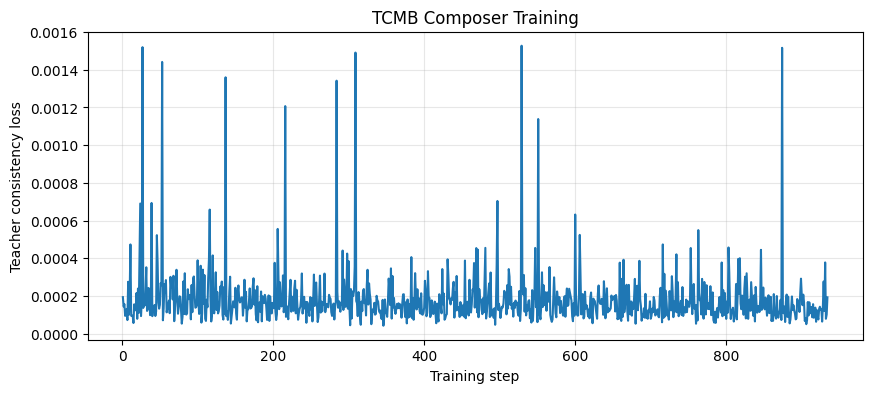


All trained parameters finite: True
Composer checkpoint verified: True


In [64]:
import torch
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Load initialization and trained checkpoints
initial = torch.load(
    "results/checkpoints/tcmb_initial_components.pt",
    map_location="cpu",
    weights_only=False
)

trained = torch.load(
    "results/checkpoints/tcmb_composer_trained.pt",
    map_location="cpu",
    weights_only=False
)

# Compare parameter changes
print("=" * 65)
print("COMPOSER PARAMETER UPDATE CHECK")
print("=" * 65)

total_change = 0.0

for name, initial_weight in initial["composer"].items():
    trained_weight = trained["composer"][name]

    difference = torch.norm(
        trained_weight.float() - initial_weight.float()
    ).item()

    total_change += difference

    print(f"{name}: change = {difference:.8f}")

print("\nTotal parameter change:", total_change)

# Inspect training history
history = pd.read_csv(
    "results/training/composer_training_loss.csv"
)

print("\nTRAINING LOSS")
print("First step:", history["training_loss"].iloc[0])
print("Last step:", history["training_loss"].iloc[-1])
print("Minimum:", history["training_loss"].min())
print("Maximum:", history["training_loss"].max())

# Validation by language
validation = pd.read_csv(
    "results/training/composer_validation_by_language.csv"
)

print("\nVALIDATION RESULTS")
display(validation)

# Plot training loss
plt.figure(figsize=(10, 4))
plt.plot(history["step"], history["training_loss"])
plt.xlabel("Training step")
plt.ylabel("Teacher consistency loss")
plt.title("TCMB Composer Training")
plt.grid(alpha=0.3)
plt.show()

# Verify finite checkpoint parameters
all_finite = all(
    torch.isfinite(value).all().item()
    for value in trained["composer"].values()
)

print("\nAll trained parameters finite:", all_finite)
print("Composer checkpoint verified:", total_change > 0 and all_finite)

In [65]:
%cd /content/TCMB

import ast
import torch
from pathlib import Path

FILES = [
    "tcmb/composer.py",
    "tcmb/pair_scorer.py",
    "tcmb/budget_predictor.py",
    "tcmb/typological_features.py",
    "tcmb/anchor_constraints.py",
    "training/train_composer.py",
    "training/train_tcmb.py",
    "training/leave_one_out.py",
]

print("=" * 75)
print("TCMB IMPLEMENTATION INSPECTION")
print("=" * 75)

for filename in FILES:
    path = Path(filename)

    print(f"\n{'=' * 65}")
    print(filename)
    print("=" * 65)

    if not path.exists():
        print("FILE NOT FOUND")
        continue

    source = path.read_text(encoding="utf-8")

    if not source.strip():
        print("EMPTY FILE")
        continue

    tree = ast.parse(source)

    for node in tree.body:
        if isinstance(node, (ast.ClassDef, ast.FunctionDef, ast.AsyncFunctionDef)):
            print(f"\n{type(node).__name__}: {node.name}")

            if isinstance(node, ast.ClassDef):
                for item in node.body:
                    if isinstance(item, (ast.FunctionDef, ast.AsyncFunctionDef)):
                        print(
                            "  Method:",
                            ast.unparse(item.args)
                        )

            elif isinstance(node, ast.FunctionDef):
                print("  Arguments:", ast.unparse(node.args))

# Inspect checkpoint structure
print("\n" + "=" * 75)
print("CHECKPOINT INSPECTION")
print("=" * 75)

checkpoint_paths = [
    "results/checkpoints/tcmb_initial_components.pt",
    "results/checkpoints/tcmb_composer_trained.pt",
    "results/checkpoints/tcmb_pair_scorer.pt",
]

for filename in checkpoint_paths:
    path = Path(filename)

    print(f"\n{filename}")

    if not path.exists():
        print("NOT FOUND")
        continue

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    if isinstance(checkpoint, dict):
        for key, value in checkpoint.items():
            if isinstance(value, dict):
                print(f"{key}:")
                for name, tensor in value.items():
                    if torch.is_tensor(tensor):
                        print(
                            f"  {name}: {tuple(tensor.shape)}"
                        )
                    else:
                        print(f"  {name}: {type(tensor).__name__}")
            elif torch.is_tensor(value):
                print(f"{key}: tensor {tuple(value.shape)}")
            else:
                print(f"{key}: {type(value).__name__}")
    else:
        print(type(checkpoint).__name__)

print("\nINSPECTION COMPLETED")

/content/TCMB
TCMB IMPLEMENTATION INSPECTION

tcmb/composer.py

ClassDef: EmbeddingComposer
  Method: self, hidden_dim: int=768, bottleneck_dim: int=256, residual_scale: float=0.1
  Method: self, left, right
  Method: self, pair_embeddings

tcmb/pair_scorer.py

ClassDef: TypologyConditionedPairScorer
  Method: self, hidden_dim=768, profile_dim=14, bottleneck_dim=256, dropout=0.1
  Method: self, left, right, profile
  Method: self, embeddings, profile, valid_pair_mask=None

tcmb/budget_predictor.py
EMPTY FILE

tcmb/typological_features.py

FunctionDef: load_documents
  Arguments: file_path

FunctionDef: count_graphemes
  Arguments: text

FunctionDef: count_script_letters
  Arguments: text

FunctionDef: extract_language_profile
  Arguments: language_code, records, tokenizer, marker_id, batch_size=16

FunctionDef: extract_all_profiles
  Arguments: corpus_dir, output_dir, model_name, batch_size=16

FunctionDef: main
  Arguments: 

tcmb/anchor_constraints.py

FunctionDef: find_anchor_spans


In [68]:
%cd /content/TCMB

from pathlib import Path

folders = [
    "experiments",
    "training",
    "tcmb",
    "results/checkpoints",
    "results/training",
    "results/tables",
    "results/figures",
]

for folder in folders:
    Path(folder).mkdir(parents=True, exist_ok=True)

print("All TCMB folders created successfully!")
print("Current directory:", Path.cwd())

/content/TCMB
All TCMB folders created successfully!
Current directory: /content/TCMB


In [69]:
%%writefile experiments/composer_ablation.py

# Paste the complete composer_ablation.py code here

Writing experiments/composer_ablation.py


In [70]:
!ls -l experiments/composer_ablation.py

-rw-r--r-- 1 root root 53 Nov  5 09:50 experiments/composer_ablation.py


In [72]:
%%writefile experiments/composer_ablation.py

import argparse
import random
import json
from pathlib import Path

import torch
import pandas as pd
import torch.nn.functional as F

from transformers import AutoTokenizer, AutoModel
from tcmb.composer import EmbeddingComposer
from training.train_composer import load_records, make_sample

LANGUAGES = [
    "eng_Latn", "tam_Taml", "tel_Telu", "kan_Knda",
    "mal_Mlym", "hin_Deva", "cmn_Hans", "jpn_Jpan"
]


def load_composer(checkpoint_path, device):
    checkpoint = torch.load(
        checkpoint_path, map_location="cpu", weights_only=False
    )

    model = EmbeddingComposer(768, 256).to(device)
    model.load_state_dict(checkpoint["composer"])
    model.eval()
    return model


def evaluate_one(model, embedding, teacher, position, composer, method):
    if method == "mean":
        merged = (
            embedding[:, position, :]
            + embedding[:, position + 1, :]
        ) / 2

    else:
        merged = composer(
            embedding[:, position, :],
            embedding[:, position + 1, :]
        )

    shorter = torch.cat([
        embedding[:, :position, :],
        merged.unsqueeze(1),
        embedding[:, position + 2:, :]
    ], dim=1)

    with torch.no_grad():
        student = model(
            inputs_embeds=shorter,
            attention_mask=torch.ones(
                shorter.shape[:2],
                dtype=torch.long,
                device=shorter.device
            )
        ).last_hidden_state

    teacher_target = torch.cat([
        teacher[:, :position, :],
        teacher[:, position:position + 2, :].mean(
            dim=1, keepdim=True
        ),
        teacher[:, position + 2:, :]
    ], dim=1)

    similarities = F.cosine_similarity(
        student.float(),
        teacher_target.float(),
        dim=-1
    )

    return (
        similarities.mean().item(),
        similarities[:, position].mean().item()
    )


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--corpus-dir", default="data/calibration_clean")
    parser.add_argument("--max-docs", type=int, default=14)
    parser.add_argument("--chunk-tokens", type=int, default=126)
    parser.add_argument("--seed", type=int, default=42)
    args = parser.parse_args()

    random.seed(args.seed)
    torch.manual_seed(args.seed)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("Device:", device)

    tokenizer = AutoTokenizer.from_pretrained(
        "FacebookAI/xlm-roberta-base"
    )
    tokenizer.model_max_length = 1_000_000

    encoder = AutoModel.from_pretrained(
        "FacebookAI/xlm-roberta-base"
    ).to(device).eval()

    initial = load_composer(
        "results/checkpoints/tcmb_initial_components.pt", device
    )
    trained = load_composer(
        "results/checkpoints/tcmb_composer_trained.pt", device
    )

    corpus = load_records(args.corpus_dir)

    # Reproduce the document-level 90/10 split used by the
    # original composer pilot. This is not a domain-held-out split.
    split_rng = random.Random(args.seed)
    sample_rng = random.Random(args.seed + 100)

    results = []

    for language in LANGUAGES:
        records = corpus[language].copy()
        split_rng.shuffle(records)

        val_count = max(1, round(len(records) * 0.10))
        validation_records = records[:val_count]
        validation_records = validation_records[:args.max_docs]

        print(language, "validation documents:", len(validation_records))

        for record in validation_records:
            sample = make_sample(
                record, tokenizer, sample_rng, args.chunk_tokens
            )

            if sample is None:
                continue

            ids = torch.tensor(
                [sample["input_ids"]], device=device
            )
            attention = torch.ones_like(ids)
            position = sample["merge_position"]

            with torch.no_grad():
                teacher = encoder(
                    input_ids=ids,
                    attention_mask=attention
                ).last_hidden_state

                embeddings = encoder.get_input_embeddings()(ids)

                for method, composer in [
                    ("mean", None),
                    ("untrained_composer", initial),
                    ("trained_composer", trained),
                ]:
                    full_similarity, merged_similarity = evaluate_one(
                        encoder,
                        embeddings,
                        teacher,
                        position,
                        composer,
                        method
                    )

                    results.append({
                        "language": language,
                        "method": method,
                        "full_sequence_cosine": full_similarity,
                        "merged_position_cosine": merged_similarity,
                        "document_id": record.get("document_id")
                    })

    output = Path("results/tables")
    output.mkdir(parents=True, exist_ok=True)

    df = pd.DataFrame(results)

    df.to_csv(
        output / "composer_ablation_per_document.csv",
        index=False
    )

    summary = df.groupby(
        ["language", "method"]
    ).agg(
        documents=("document_id", "count"),
        mean_full_sequence_cosine=("full_sequence_cosine", "mean"),
        mean_merged_position_cosine=("merged_position_cosine", "mean"),
        std_full_sequence_cosine=("full_sequence_cosine", "std")
    ).reset_index()

    summary.to_csv(
        output / "composer_ablation_summary.csv",
        index=False
    )

    display(summary)

    print("\nCOMPOSER ABLATION COMPLETED")
    print("Results:", output)


if __name__ == "__main__":
    main()

Overwriting experiments/composer_ablation.py


In [73]:
!python -m experiments.composer_ablation

Device: cuda
Loading weights: 100% 199/199 [00:00<00:00, 4103.83it/s]
[transformers] XLMRobertaModel LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
eng_Latn validation documents: 14
tam_Taml validation documents: 14
tel_Telu validation documents: 10
kan_Knda validation documents: 12
mal_Mlym validation documents: 14
hin_Deva validation documents: 14
cmn_Hans validation documents: 11
jpn_Jpan validation documents: 9
Traceback (most recent call last):
  File "<frozen runpy>", line 203, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File

In [74]:
import pandas as pd

display(pd.read_csv(
    "results/tables/composer_ablation_summary.csv"
))

,language,method,documents,mean_full_sequence_cosine,mean_merged_position_cosine,std_full_sequence_cosine
0,cmn_Hans,mean,11,0.999796,0.994069,0.000089
1,cmn_Hans,trained_composer,11,0.999822,0.995960,0.000082
2,cmn_Hans,untrained_composer,11,0.999796,0.993992,0.000090
3,eng_Latn,mean,14,0.999852,0.994790,0.000072
4,eng_Latn,trained_composer,14,0.999871,0.995849,0.000061
5,eng_Latn,untrained_composer,14,0.999851,0.994819,0.000074
6,hin_Deva,mean,14,0.999852,0.996099,0.000076
7,hin_Deva,trained_composer,14,0.999898,0.997239,0.000037
8,hin_Deva,untrained_composer,14,0.999853,0.996096,0.000075
9,jpn_Jpan,mean,9,0.999769,0.993987,0.000125


In [75]:
from pathlib import Path

path = Path("experiments/composer_ablation.py")

source = path.read_text()

source = source.replace(
    "    display(summary)",
    "    print(summary.to_string(index=False))"
)

path.write_text(source)

print("Display error fixed!")

Display error fixed!


In [76]:
import pandas as pd
from IPython.display import display

summary = pd.read_csv(
    "results/tables/composer_ablation_summary.csv"
)

display(summary)

,language,method,documents,mean_full_sequence_cosine,mean_merged_position_cosine,std_full_sequence_cosine
0,cmn_Hans,mean,11,0.999796,0.994069,0.000089
1,cmn_Hans,trained_composer,11,0.999822,0.995960,0.000082
2,cmn_Hans,untrained_composer,11,0.999796,0.993992,0.000090
3,eng_Latn,mean,14,0.999852,0.994790,0.000072
4,eng_Latn,trained_composer,14,0.999871,0.995849,0.000061
5,eng_Latn,untrained_composer,14,0.999851,0.994819,0.000074
6,hin_Deva,mean,14,0.999852,0.996099,0.000076
7,hin_Deva,trained_composer,14,0.999898,0.997239,0.000037
8,hin_Deva,untrained_composer,14,0.999853,0.996096,0.000075
9,jpn_Jpan,mean,9,0.999769,0.993987,0.000125


In [77]:
from pathlib import Path
import pandas as pd

print("===== PAIR SCORER SOURCE =====")

print(
    Path("tcmb/pair_scorer.py").read_text()
)

print("\n===== TYPOLOGICAL PROFILE COLUMNS =====")

df = pd.read_csv(
    "results/tables/typological_profiles.csv"
)

print(df.columns.tolist())
print(df.head(2).to_string(index=False))

===== PAIR SCORER SOURCE =====

"""
TCMB: Typology-conditioned adjacent pair scorer.

Input:
    Left and right token embeddings
    Language-level calibration profile

Output:
    Merge logits and probabilities for adjacent pairs.

The model is not trained in this module.
"""

import torch
import torch.nn as nn


PROFILE_FEATURES = [
    "raw_tokens_per_grapheme",
    "content_tokens_per_grapheme",
    "marker_token_share",
    "mean_document_graphemes",
    "script_share_latin",
    "script_share_devanagari",
    "script_share_tamil",
    "script_share_telugu",
    "script_share_kannada",
    "script_share_malayalam",
    "script_share_han",
    "script_share_hiragana",
    "script_share_katakana",
    "script_share_other",
]


class TypologyConditionedPairScorer(nn.Module):
    """
    Assigns merge suitability scores to adjacent embedding pairs.

    Expected pair embedding shape: [batch, pairs, hidden_dim]
    Expected profile shape: [batch, profile_dim] or [profile_dim]
    """



In [78]:
%%writefile training/train_pair_scorer.py

import argparse
import json
import random
from pathlib import Path
from urllib.parse import urlparse

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel
from tqdm.auto import tqdm

from tcmb.composer import EmbeddingComposer
from tcmb.pair_scorer import (
    TypologyConditionedPairScorer,
    PROFILE_FEATURES,
)
from tcmb.anchor_constraints import (
    build_protected_token_mask,
    is_merge_allowed,
)
from training.train_composer import load_records


LANGUAGES = [
    "eng_Latn",
    "tam_Taml",
    "tel_Telu",
    "kan_Knda",
    "mal_Mlym",
    "hin_Deva",
    "cmn_Hans",
    "jpn_Jpan",
]


def get_text(record):
    """Extract document text from a calibration record."""

    for key in ["text", "content", "document", "body"]:
        value = record.get(key)

        if isinstance(value, str) and value.strip():
            return value.strip()

    raise ValueError(
        "Could not find document text. "
        f"Available keys: {list(record.keys())}"
    )


def get_group_key(record, index):
    """
    Prefer near-duplicate cluster or domain identifiers.
    Fall back to document ID if no grouping metadata exists.
    """

    metadata = record.get("metadata", {})

    if not isinstance(metadata, dict):
        metadata = {}

    keys = [
        "minhash_cluster",
        "near_duplicate_cluster",
        "cluster_id",
        "domain",
        "source_domain",
        "url",
        "source_url",
    ]

    for key in keys:
        value = record.get(key) or metadata.get(key)

        if value:
            value = str(value).strip()

            if "://" in value:
                parsed = urlparse(value)
                value = parsed.netloc or value
            elif "/" in value and "." in value.split("/")[0]:
                value = value.split("/")[0]

            return value.lower()

    doc_id = record.get("document_id") or record.get("id")

    if doc_id is not None:
        return f"document:{doc_id}"

    return f"document_index:{index}"


def split_by_group(records, seed=42, val_fraction=0.15):
    """Split records so that groups do not cross train/validation."""

    groups = {}

    for index, record in enumerate(records):
        key = get_group_key(record, index)
        groups.setdefault(key, []).append(record)

    group_names = list(groups.keys())

    if len(group_names) < 2:
        raise RuntimeError(
            "Not enough independent groups for a validation split."
        )

    rng = random.Random(seed)
    rng.shuffle(group_names)

    n_val = max(1, round(len(group_names) * val_fraction))
    n_val = min(n_val, len(group_names) - 1)

    val_groups = set(group_names[:n_val])

    train_records = []
    val_records = []

    for key, group_records in groups.items():
        if key in val_groups:
            val_records.extend(group_records)
        else:
            train_records.extend(group_records)

    return train_records, val_records


def limit_records(records, maximum, seed):
    if maximum <= 0 or len(records) <= maximum:
        return records

    rng = random.Random(seed)
    return rng.sample(records, maximum)


def load_profile_map(profile_file):
    """Load and standardize the 14 profile features."""

    df = pd.read_csv(profile_file)

    missing = [
        feature for feature in PROFILE_FEATURES
        if feature not in df.columns
    ]

    if missing:
        raise ValueError(
            f"Missing profile columns: {missing}"
        )

    indexed = df.set_index("language_code")

    profile_matrix = indexed[
        PROFILE_FEATURES
    ].astype(float)

    profile_mean = torch.tensor(
        profile_matrix.mean().values,
        dtype=torch.float32
    )

    profile_std = torch.tensor(
        profile_matrix.std(ddof=0).values,
        dtype=torch.float32
    ).clamp_min(1e-6)

    profile_map = {}

    for language in LANGUAGES:
        if language not in indexed.index:
            raise ValueError(
                f"Missing typological profile for {language}"
            )

        raw = torch.tensor(
            indexed.loc[language, PROFILE_FEATURES].to_numpy(
                dtype=np.float32
            ),
            dtype=torch.float32
        )

        profile_map[language] = (
            raw - profile_mean
        ) / profile_std

    return profile_map, profile_mean, profile_std


@torch.no_grad()
def create_document_examples(
    record,
    language,
    tokenizer,
    encoder,
    composer,
    profile,
    device,
    rng,
    candidate_count=8,
    max_length=128,
    tie_tolerance=1e-6,
):
    """
    Generate multiple merge candidates from one document.

    Each candidate's target is its measured teacher-consistency
    after composition and a frozen XLM-R forward pass.
    """

    text = get_text(record)

    encoded = tokenizer(
        text,
        add_special_tokens=True,
        truncation=True,
        max_length=max_length,
        return_offsets_mapping=True,
        return_special_tokens_mask=True,
    )

    input_ids = encoded["input_ids"]
    offsets = encoded["offset_mapping"]
    special_mask = encoded["special_tokens_mask"]

    if len(input_ids) < 3:
        return None

    protected_mask = build_protected_token_mask(
        offsets,
        text,
        special_tokens_mask=special_mask,
    )

    eligible_positions = []

    for i in range(len(input_ids) - 1):

        if special_mask[i] or special_mask[i + 1]:
            continue

        if is_merge_allowed(i, protected_mask):
            eligible_positions.append(i)

    if len(eligible_positions) < 2:
        return None

    if len(eligible_positions) > candidate_count:
        eligible_positions = sorted(
            rng.sample(eligible_positions, candidate_count)
        )

    ids = torch.tensor(
        [input_ids],
        dtype=torch.long,
        device=device,
    )

    attention = torch.ones_like(ids)

    # Original token embeddings.
    embeddings = encoder.get_input_embeddings()(ids)

    # Teacher contextual representations.
    teacher = encoder(
        input_ids=ids,
        attention_mask=attention,
    ).last_hidden_state

    left_vectors = []
    right_vectors = []
    quality_targets = []
    candidate_positions = []

    for position in eligible_positions:

        left = embeddings[:, position, :]
        right = embeddings[:, position + 1, :]

        # Compose the two original token embeddings.
        merged = composer(
            left, right
        ).unsqueeze(1)

        # Construct compressed embedding sequence.
        shorter = torch.cat(
            [
                embeddings[:, :position, :],
                merged,
                embeddings[:, position + 2:, :],
            ],
            dim=1,
        )

        student = encoder(
            inputs_embeds=shorter,
            attention_mask=torch.ones(
                shorter.shape[:2],
                dtype=torch.long,
                device=device,
            ),
        ).last_hidden_state

        # Reference is the average teacher representation
        # of the two original positions.
        teacher_target = teacher[
            :, position:position + 2, :
        ].mean(dim=1)

        student_target = student[:, position, :]

        quality = F.cosine_similarity(
            student_target.float(),
            teacher_target.float(),
            dim=-1,
        ).item()

        left_vectors.append(left.squeeze(0).cpu())
        right_vectors.append(right.squeeze(0).cpu())
        quality_targets.append(float(quality))
        candidate_positions.append(position)

    if len(quality_targets) < 2:
        return None

    if np.std(quality_targets) < tie_tolerance:
        # No useful pairwise ranking signal in this document.
        return None

    return {
        "language": language,
        "document_id": str(
            record.get("document_id", record.get("id", "unknown"))
        ),
        "left": torch.stack(left_vectors),
        "right": torch.stack(right_vectors),
        "quality": torch.tensor(
            quality_targets,
            dtype=torch.float32,
        ),
        "positions": candidate_positions,
        "profile": profile.clone(),
    }


class PairGroupDataset(Dataset):

    def __init__(self, groups):
        self.groups = groups

    def __len__(self):
        return len(self.groups)

    def __getitem__(self, index):
        return self.groups[index]


def collate_groups(groups):
    """Pad candidate counts to make batches."""

    batch_size = len(groups)
    max_candidates = max(
        len(group["quality"]) for group in groups
    )

    hidden_dim = groups[0]["left"].shape[-1]
    profile_dim = groups[0]["profile"].shape[-1]

    left = torch.zeros(
        batch_size, max_candidates, hidden_dim
    )

    right = torch.zeros_like(left)

    quality = torch.zeros(
        batch_size, max_candidates
    )

    mask = torch.zeros(
        batch_size, max_candidates,
        dtype=torch.bool
    )

    profiles = torch.zeros(
        batch_size, profile_dim
    )

    for i, group in enumerate(groups):
        n = len(group["quality"])

        left[i, :n] = group["left"]
        right[i, :n] = group["right"]
        quality[i, :n] = group["quality"]
        mask[i, :n] = True
        profiles[i] = group["profile"]

    return left, right, profiles, quality, mask


def pairwise_ranking_loss(
    logits,
    quality,
    mask,
    tie_tolerance=1e-6,
):
    """
    Higher quality means the candidate should receive
    a higher scorer logit.
    """

    quality_difference = (
        quality.unsqueeze(2) - quality.unsqueeze(1)
    )

    logit_difference = (
        logits.unsqueeze(2) - logits.unsqueeze(1)
    )

    n = quality.shape[1]

    upper_triangle = torch.triu(
        torch.ones(
            n, n,
            dtype=torch.bool,
            device=logits.device,
        ),
        diagonal=1,
    ).unsqueeze(0)

    valid = (
        mask.unsqueeze(2)
        & mask.unsqueeze(1)
        & upper_triangle
        & (quality_difference.abs() > tie_tolerance)
    )

    if not valid.any():
        return None, 0

    signed_difference = (
        quality_difference.sign() * logit_difference
    )

    loss = F.softplus(
        -signed_difference[valid]
    ).mean()

    return loss, int(valid.sum().item())


def train_one_epoch(
    scorer,
    loader,
    optimizer,
    device,
):
    scorer.train()

    losses = []
    comparisons = 0

    for left, right, profile, quality, mask in loader:

        left = left.to(device)
        right = right.to(device)
        profile = profile.to(device)
        quality = quality.to(device)
        mask = mask.to(device)

        optimizer.zero_grad(set_to_none=True)

        logits, _ = scorer(
            left,
            right,
            profile,
        )

        loss, n_comparisons = pairwise_ranking_loss(
            logits,
            quality,
            mask,
        )

        if loss is None:
            continue

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            scorer.parameters(),
            max_norm=1.0,
        )

        optimizer.step()

        losses.append(loss.item())
        comparisons += n_comparisons

    return (
        float(np.mean(losses)) if losses else float("nan"),
        comparisons,
    )


@torch.no_grad()
def validate(scorer, loader, device):
    scorer.eval()

    losses = []
    correct = 0
    total = 0

    for left, right, profile, quality, mask in loader:

        left = left.to(device)
        right = right.to(device)
        profile = profile.to(device)
        quality = quality.to(device)
        mask = mask.to(device)

        logits, _ = scorer(
            left,
            right,
            profile,
        )

        loss, _ = pairwise_ranking_loss(
            logits,
            quality,
            mask,
        )

        if loss is not None:
            losses.append(loss.item())

        qdiff = (
            quality.unsqueeze(2) - quality.unsqueeze(1)
        )

        ldiff = (
            logits.unsqueeze(2) - logits.unsqueeze(1)
        )

        n = quality.shape[1]

        upper = torch.triu(
            torch.ones(
                n, n,
                dtype=torch.bool,
                device=device,
            ),
            diagonal=1,
        ).unsqueeze(0)

        valid = (
            mask.unsqueeze(2)
            & mask.unsqueeze(1)
            & upper
            & (qdiff.abs() > 1e-6)
        )

        correct += (
            (qdiff[valid] * ldiff[valid]) > 0
        ).sum().item()

        total += int(valid.sum().item())

    return {
        "loss": float(np.mean(losses)) if losses else float("nan"),
        "pairwise_accuracy": correct / total if total else float("nan"),
        "comparisons": total,
    }


def build_groups(
    records,
    language,
    tokenizer,
    encoder,
    composer,
    profile,
    device,
    seed,
    candidate_count,
):
    rng = random.Random(seed)
    groups = []
    target_rows = []

    for record in tqdm(
        records,
        desc=f"Generating pairs: {language}",
        leave=False,
    ):
        group = create_document_examples(
            record=record,
            language=language,
            tokenizer=tokenizer,
            encoder=encoder,
            composer=composer,
            profile=profile,
            device=device,
            rng=rng,
            candidate_count=candidate_count,
        )

        if group is None:
            continue

        groups.append(group)

        for position, quality in zip(
            group["positions"],
            group["quality"].tolist(),
        ):
            target_rows.append({
                "language": language,
                "document_id": group["document_id"],
                "token_position": position,
                "teacher_consistency": quality,
            })

    return groups, target_rows


def main():
    parser = argparse.ArgumentParser()

    parser.add_argument(
        "--corpus-dir",
        default="data/calibration_clean",
    )

    parser.add_argument(
        "--profile-file",
        default="results/tables/typological_profiles.csv",
    )

    parser.add_argument(
        "--composer-checkpoint",
        default="results/checkpoints/tcmb_composer_trained.pt",
    )

    parser.add_argument("--epochs", type=int, default=8)
    parser.add_argument("--batch-size", type=int, default=8)
    parser.add_argument("--learning-rate", type=float, default=0.0003)
    parser.add_argument("--candidate-count", type=int, default=8)

    parser.add_argument(
        "--max-train-docs-per-language",
        type=int,
        default=50,
    )

    parser.add_argument(
        "--max-val-docs-per-language",
        type=int,
        default=12,
    )

    parser.add_argument("--seed", type=int, default=42)

    args = parser.parse_args()

    random.seed(args.seed)
    np.random.seed(args.seed)
    torch.manual_seed(args.seed)

    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    print("Device:", device)
    print("Profile dimensions:", len(PROFILE_FEATURES))

    # Load typological profiles.
    profile_map, profile_mean, profile_std = load_profile_map(
        args.profile_file
    )

    # Load tokenizer and frozen XLM-R.
    model_name = "FacebookAI/xlm-roberta-base"

    tokenizer = AutoTokenizer.from_pretrained(
        model_name,
        use_fast=True,
    )

    if not tokenizer.is_fast:
        raise RuntimeError(
            "A fast tokenizer is required for anchor offsets."
        )

    tokenizer.model_max_length = 1_000_000

    encoder = AutoModel.from_pretrained(
        model_name
    ).to(device).eval()

    for parameter in encoder.parameters():
        parameter.requires_grad_(False)

    # Load the trained composer.
    composer = EmbeddingComposer(
        hidden_dim=768,
        bottleneck_dim=256,
    ).to(device)

    composer_checkpoint = torch.load(
        args.composer_checkpoint,
        map_location="cpu",
        weights_only=False,
    )

    composer.load_state_dict(
        composer_checkpoint["composer"]
    )

    composer.eval()

    # Read calibration corpus.
    corpus = load_records(args.corpus_dir)

    train_groups = []
    val_groups = []

    all_target_rows = []

    for index, language in enumerate(LANGUAGES):

        if language not in corpus:
            raise ValueError(
                f"Language {language} not found in calibration corpus."
            )

        records = corpus[language]

        train_records, val_records = split_by_group(
            records,
            seed=args.seed + index,
        )

        # Pilot limits; set to 0 to use all records.
        train_records = limit_records(
            train_records,
            args.max_train_docs_per_language,
            args.seed + 100 + index,
        )

        val_records = limit_records(
            val_records,
            args.max_val_docs_per_language,
            args.seed + 200 + index,
        )

        print(
            f"\n{language}: "
            f"train docs={len(train_records)}, "
            f"validation docs={len(val_records)}"
        )

        train_language_groups, train_targets = build_groups(
            train_records,
            language,
            tokenizer,
            encoder,
            composer,
            profile_map[language],
            device,
            args.seed + 300 + index,
            args.candidate_count,
        )

        val_language_groups, val_targets = build_groups(
            val_records,
            language,
            tokenizer,
            encoder,
            composer,
            profile_map[language],
            device,
            args.seed + 400 + index,
            args.candidate_count,
        )

        print(
            "  Candidate groups:",
            len(train_language_groups),
            "train /",
            len(val_language_groups),
            "validation",
        )

        train_groups.extend(train_language_groups)
        val_groups.extend(val_language_groups)

        all_target_rows.extend(train_targets)
        all_target_rows.extend(val_targets)

    if not train_groups or not val_groups:
        raise RuntimeError(
            "No training or validation candidate groups were generated."
        )

    print("\nTotal training groups:", len(train_groups))
    print("Total validation groups:", len(val_groups))

    train_loader = DataLoader(
        PairGroupDataset(train_groups),
        batch_size=args.batch_size,
        shuffle=True,
        collate_fn=collate_groups,
    )

    val_loader = DataLoader(
        PairGroupDataset(val_groups),
        batch_size=args.batch_size,
        shuffle=False,
        collate_fn=collate_groups,
    )

    # Initialise the pair scorer.
    scorer = TypologyConditionedPairScorer(
        hidden_dim=768,
        profile_dim=len(PROFILE_FEATURES),
        bottleneck_dim=256,
        dropout=0.1,
    ).to(device)

    optimizer = torch.optim.AdamW(
        scorer.parameters(),
        lr=args.learning_rate,
        weight_decay=0.01,
    )

    history = []
    best_accuracy = -1.0

    Path("results/checkpoints").mkdir(
        parents=True,
        exist_ok=True,
    )

    Path("results/training").mkdir(
        parents=True,
        exist_ok=True,
    )

    for epoch in range(1, args.epochs + 1):

        train_loss, train_comparisons = train_one_epoch(
            scorer,
            train_loader,
            optimizer,
            device,
        )

        validation = validate(
            scorer,
            val_loader,
            device,
        )

        row = {
            "epoch": epoch,
            "train_pairwise_loss": train_loss,
            "train_comparisons": train_comparisons,
            "validation_pairwise_loss": validation["loss"],
            "validation_pairwise_accuracy": validation["pairwise_accuracy"],
            "validation_comparisons": validation["comparisons"],
        }

        history.append(row)

        print(
            f"\nEpoch {epoch}/{args.epochs}"
            f"\n  Train ranking loss: {train_loss:.6f}"
            f"\n  Validation loss: {validation['loss']:.6f}"
            f"\n  Validation ranking accuracy: "
            f"{validation['pairwise_accuracy']:.4f}"
            f"\n  Validation comparisons: "
            f"{validation['comparisons']}"
        )

        accuracy = validation["pairwise_accuracy"]

        if np.isfinite(accuracy) and accuracy > best_accuracy:
            best_accuracy = accuracy

            torch.save(
                {
                    "pair_scorer": scorer.state_dict(),
                    "profile_mean": profile_mean,
                    "profile_std": profile_std,
                    "profile_features": PROFILE_FEATURES,
                    "validation_pairwise_accuracy": best_accuracy,
                    "validation_pairwise_loss": validation["loss"],
                    "epoch": epoch,
                    "status": "trained_pair_scorer",
                    "config": vars(args),
                },
                "results/checkpoints/tcmb_pair_scorer.pt",
            )

    pd.DataFrame(history).to_csv(
        "results/training/pair_scorer_training.csv",
        index=False,
    )

    pd.DataFrame(all_target_rows).to_csv(
        "results/training/pair_quality_targets.csv",
        index=False,
    )

    print("\nPAIR SCORER TRAINING FINISHED")
    print("Best validation pairwise accuracy:", best_accuracy)
    print(
        "Checkpoint:",
        "results/checkpoints/tcmb_pair_scorer.pt",
    )


if __name__ == "__main__":
    main()

Writing training/train_pair_scorer.py


In [79]:
%cd /content/TCMB

!python -m training.train_pair_scorer \
    --epochs 8 \
    --batch-size 8 \
    --candidate-count 8 \
    --max-train-docs-per-language 50 \
    --max-val-docs-per-language 12 \
    --learning-rate 0.0003

/content/TCMB
Device: cuda
Profile dimensions: 14
Loading weights: 100% 199/199 [00:00<00:00, 4217.79it/s]
[transformers] XLMRobertaModel LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.

eng_Latn: train docs=50, validation docs=12
  Candidate groups: 50 train / 12 validation

tam_Taml: train docs=50, validation docs=12
  Candidate groups: 50 train / 12 validation

tel_Telu: train docs=50, validation docs=12
  Candidate groups: 50 train / 12 validation

kan_Knda: train docs=50, validation docs=12
  Candidate groups: 50 train / 12 validation

mal_Mlym: train doc

In [80]:
import torch
import pandas as pd
from pathlib import Path

checkpoint_path = Path(
    "results/checkpoints/tcmb_pair_scorer.pt"
)

assert checkpoint_path.exists(), "Pair scorer checkpoint not found!"

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint status:", checkpoint["status"])
print(
    "Validation pairwise accuracy:",
    checkpoint["validation_pairwise_accuracy"]
)
print(
    "Validation pairwise loss:",
    checkpoint["validation_pairwise_loss"]
)
print(
    "Number of profile features:",
    len(checkpoint["profile_features"])
)

print("\nTraining history:")
display(pd.read_csv(
    "results/training/pair_scorer_training.csv"
))

print("\nQuality target samples:")
display(pd.read_csv(
    "results/training/pair_quality_targets.csv"
).head(10))

print("\nCheckpoint verification completed!")

Checkpoint status: trained_pair_scorer
Validation pairwise accuracy: 0.6226274655749907
Validation pairwise loss: 0.6570344716310501
Number of profile features: 14

Training history:


,epoch,train_pairwise_loss,train_comparisons,validation_pairwise_loss,validation_pairwise_accuracy,validation_comparisons
0,1,0.654231,11197,0.641529,0.622255,2687
1,2,0.538341,11197,0.657034,0.622627,2687
2,3,0.416896,11197,0.723696,0.611090,2687
3,4,0.297166,11197,0.875955,0.612579,2687
4,5,0.203124,11197,1.056458,0.612951,2687
5,6,0.156798,11197,1.266986,0.588389,2687
6,7,0.140493,11197,1.266869,0.608857,2687
7,8,0.127835,11197,1.444177,0.599926,2687



Quality target samples:


,language,document_id,token_position,teacher_consistency
0,eng_Latn,<urn:uuid:b953d44d-5f74-4167-ae85-b44574246970>,11,0.997961
1,eng_Latn,<urn:uuid:b953d44d-5f74-4167-ae85-b44574246970>,12,0.998541
2,eng_Latn,<urn:uuid:b953d44d-5f74-4167-ae85-b44574246970>,18,0.991681
3,eng_Latn,<urn:uuid:b953d44d-5f74-4167-ae85-b44574246970>,22,0.991790
4,eng_Latn,<urn:uuid:b953d44d-5f74-4167-ae85-b44574246970>,40,0.994862
5,eng_Latn,<urn:uuid:b953d44d-5f74-4167-ae85-b44574246970>,94,0.993878
6,eng_Latn,<urn:uuid:b953d44d-5f74-4167-ae85-b44574246970>,113,0.994771
7,eng_Latn,<urn:uuid:b953d44d-5f74-4167-ae85-b44574246970>,119,0.991123
8,eng_Latn,<urn:uuid:a8bb832d-1bc7-4dc6-9c56-516a8d877189>,5,0.993900
9,eng_Latn,<urn:uuid:a8bb832d-1bc7-4dc6-9c56-516a8d877189>,42,0.998042



Checkpoint verification completed!


In [81]:
import torch

checkpoint = torch.load(
    "results/checkpoints/tcmb_pair_scorer.pt",
    map_location="cpu",
    weights_only=False
)

print("Saved epoch:", checkpoint["epoch"])
print(
    "Best validation accuracy:",
    checkpoint["validation_pairwise_accuracy"]
)
print(
    "Validation loss:",
    checkpoint["validation_pairwise_loss"]
)
print(
    "Profile dimensions:",
    len(checkpoint["profile_features"])
)

Saved epoch: 2
Best validation accuracy: 0.6226274655749907
Validation loss: 0.6570344716310501
Profile dimensions: 14


In [83]:
%cd /content/TCMB

from pathlib import Path

print("Merge engine exists:",
      Path("tcmb/merge_engine.py").exists())

print("TCMB folder files:",
      [p.name for p in Path("tcmb").glob("*")])

/content/TCMB
Merge engine exists: False
TCMB folder files: ['budget_predictor.py', 'composer.py', 'pair_scorer.py', '__pycache__', 'typological_features.py', 'anchor_constraints.py', '__init__.py']


In [84]:
%%writefile tcmb/merge_engine.py

Writing tcmb/merge_engine.py


In [85]:
!ls -lh tcmb/merge_engine.py

-rw-r--r-- 1 root root 1 Nov  5 10:02 tcmb/merge_engine.py


In [87]:
# ============================================================
# TCMB: CREATE MERGE ENGINE + IMPORT + INTEGRATION TEST
# ============================================================

%cd /content/TCMB

from pathlib import Path
import importlib
import sys
import textwrap

# ------------------------------------------------------------
# STEP 1: COMPLETE MERGE ENGINE SOURCE
# ------------------------------------------------------------

source = r'''
import math
import warnings
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from transformers import AutoTokenizer, AutoModel

from tcmb.composer import EmbeddingComposer
from tcmb.pair_scorer import TypologyConditionedPairScorer
from tcmb.anchor_constraints import build_protected_token_mask


PROFILE_FEATURES = [
    "raw_tokens_per_grapheme",
    "content_tokens_per_grapheme",
    "marker_token_share",
    "mean_document_graphemes",
    "script_share_latin",
    "script_share_devanagari",
    "script_share_tamil",
    "script_share_telugu",
    "script_share_kannada",
    "script_share_malayalam",
    "script_share_han",
    "script_share_hiragana",
    "script_share_katakana",
    "script_share_other",
]


def load_checkpoint(path, device):
    try:
        return torch.load(
            path,
            map_location=device,
            weights_only=False
        )
    except TypeError:
        return torch.load(path, map_location=device)


def get_state_dict(checkpoint, possible_keys):
    """Find the model state dictionary inside a checkpoint."""

    if not isinstance(checkpoint, dict):
        raise ValueError("Checkpoint must contain a dictionary.")

    for key in possible_keys:
        if key in checkpoint and isinstance(checkpoint[key], dict):
            return checkpoint[key]

    # Also support checkpoints containing the state dict directly.
    if checkpoint and all(
        isinstance(k, str) for k in checkpoint.keys()
    ):
        if any(k.endswith("weight") for k in checkpoint):
            return checkpoint

    raise KeyError(
        f"Could not find model weights. Checked keys: {possible_keys}. "
        f"Available keys: {list(checkpoint.keys())}"
    )


class TCMBEngine:

    def __init__(
        self,
        composer_checkpoint,
        scorer_checkpoint,
        profile_file,
        model_name="FacebookAI/xlm-roberta-base",
        budget_checkpoint=None,
        device=None,
        max_budget=0.30
    ):

        self.device = torch.device(
            device if device else (
                "cuda" if torch.cuda.is_available() else "cpu"
            )
        )

        self.max_budget = float(max_budget)

        print("TCMB device:", self.device)
        print("Loading tokenizer and XLM-R...")

        self.tokenizer = AutoTokenizer.from_pretrained(
            model_name,
            use_fast=True
        )

        if not self.tokenizer.is_fast:
            raise RuntimeError(
                "TCMB requires a fast tokenizer for offset mappings."
            )

        self.model = AutoModel.from_pretrained(model_name)
        self.model.to(self.device)
        self.model.eval()

        self.hidden_dim = self.model.config.hidden_size

        # ----------------------------------------------------
        # Load composer
        # ----------------------------------------------------

        print("Loading trained embedding composer...")

        composer_ckpt = load_checkpoint(
            composer_checkpoint,
            self.device
        )

        self.composer = EmbeddingComposer(
            hidden_dim=self.hidden_dim
        )

        composer_state = get_state_dict(
            composer_ckpt,
            ["composer", "model_state_dict", "state_dict"]
        )

        self.composer.load_state_dict(composer_state)
        self.composer.to(self.device)
        self.composer.eval()

        # ----------------------------------------------------
        # Load pair scorer
        # ----------------------------------------------------

        print("Loading trained pair scorer...")

        scorer_ckpt = load_checkpoint(
            scorer_checkpoint,
            self.device
        )

        self.scorer = TypologyConditionedPairScorer(
            hidden_dim=self.hidden_dim,
            profile_dim=len(PROFILE_FEATURES)
        )

        scorer_state = get_state_dict(
            scorer_ckpt,
            ["pair_scorer", "scorer", "model_state_dict", "state_dict"]
        )

        self.scorer.load_state_dict(scorer_state)
        self.scorer.to(self.device)
        self.scorer.eval()

        # Profile normalization saved during pair-scorer training.
        self.profile_mean = torch.as_tensor(
            scorer_ckpt.get(
                "profile_mean",
                np.zeros(len(PROFILE_FEATURES))
            ),
            dtype=torch.float32,
            device=self.device
        ).reshape(1, -1)

        self.profile_std = torch.as_tensor(
            scorer_ckpt.get(
                "profile_std",
                np.ones(len(PROFILE_FEATURES))
            ),
            dtype=torch.float32,
            device=self.device
        ).reshape(1, -1)

        self.profile_std = torch.where(
            self.profile_std.abs() < 1e-8,
            torch.ones_like(self.profile_std),
            self.profile_std
        )

        # ----------------------------------------------------
        # Load typological profiles
        # ----------------------------------------------------

        print("Loading typological profiles...")

        self.profile_df = pd.read_csv(profile_file)

        required = ["language_code"] + PROFILE_FEATURES
        missing = [
            col for col in required
            if col not in self.profile_df.columns
        ]

        if missing:
            raise ValueError(
                f"Missing profile columns: {missing}"
            )

        self.profiles = {}

        for _, row in self.profile_df.iterrows():
            language = str(row["language_code"])

            values = [
                float(row[col])
                for col in PROFILE_FEATURES
            ]

            values = np.nan_to_num(
                np.asarray(values, dtype=np.float32),
                nan=0.0,
                posinf=0.0,
                neginf=0.0
            )

            self.profiles[language] = values

        if budget_checkpoint is not None:
            print(
                "A budget checkpoint was supplied, but this "
                "engine version uses explicit target_ratio values."
            )

        print("TCMB engine initialized successfully.")
        print("Languages available:", len(self.profiles))
        print("Embedding dimension:", self.hidden_dim)

    # --------------------------------------------------------
    # Get normalized typological profile
    # --------------------------------------------------------

    def get_profile(self, language):

        if language not in self.profiles:
            raise KeyError(
                f"No typological profile found for {language}. "
                f"Available languages: {list(self.profiles.keys())}"
            )

        values = torch.tensor(
            self.profiles[language],
            dtype=torch.float32,
            device=self.device
        ).unsqueeze(0)

        values = (values - self.profile_mean) / self.profile_std

        return values

    # --------------------------------------------------------
    # Prepare token embeddings and anchor mask
    # --------------------------------------------------------

    def prepare(
        self,
        text,
        language,
        max_length=128,
        include_teacher=False
    ):

        encoded = self.tokenizer(
            text,
            return_tensors="pt",
            return_offsets_mapping=True,
            return_special_tokens_mask=True,
            truncation=True,
            max_length=max_length
        )

        input_ids = encoded["input_ids"].to(self.device)

        offsets = encoded["offset_mapping"][0].tolist()

        special_mask = (
            encoded["special_tokens_mask"][0]
            .tolist()
        )

        # XLM-R token embeddings before position embeddings.
        with torch.no_grad():
            embeddings = self.model.embeddings.word_embeddings(
                input_ids
            )[0]

        # Build anchor protection mask.
        protected = build_protected_token_mask(
            offsets,
            text,
            special_mask
        )

        if isinstance(protected, torch.Tensor):
            protected = protected.detach().cpu().tolist()

        protected = [bool(x) for x in protected]

        if len(protected) != len(embeddings):
            raise ValueError(
                "Anchor mask length does not match token sequence."
            )

        groups = [[i] for i in range(len(input_ids[0]))]

        profile = self.get_profile(language)

        num_content_tokens = sum(
            1 for x in special_mask if not x
        )

        prepared = {
            "text": text,
            "language": language,
            "input_ids": input_ids,
            "embeddings": embeddings,
            "groups": groups,
            "protected": protected,
            "special_mask": special_mask,
            "offsets": offsets,
            "profile": profile,
            "original_length": len(embeddings),
            "num_content_tokens": num_content_tokens,
            "teacher_hidden": None
        }

        if include_teacher:
            with torch.no_grad():
                teacher_output = self.model(
                    input_ids=input_ids,
                    attention_mask=torch.ones_like(input_ids)
                )

            prepared["teacher_hidden"] = (
                teacher_output.last_hidden_state[0].detach()
            )

        return prepared

    # --------------------------------------------------------
    # Score all eligible adjacent pairs
    # --------------------------------------------------------

    def score_pairs(self, embeddings, protected, profile):

        sequence_length = embeddings.shape[0]

        if sequence_length < 2:
            return None

        valid_pair_mask = torch.tensor(
            [
                not protected[i] and not protected[i + 1]
                for i in range(sequence_length - 1)
            ],
            dtype=torch.bool,
            device=self.device
        ).unsqueeze(0)

        if not valid_pair_mask.any():
            return None

        with torch.no_grad():
            output = self.scorer.score_sequence(
                embeddings.unsqueeze(0),
                profile,
                valid_pair_mask=valid_pair_mask
            )

        if isinstance(output, (tuple, list)):
            logits = output[0]
        elif isinstance(output, dict):
            logits = output.get(
                "logits",
                output.get("scores")
            )
        else:
            logits = output

        if logits is None:
            raise RuntimeError(
                "Pair scorer did not return usable logits."
            )

        logits = logits.reshape(-1)

        if logits.numel() != sequence_length - 1:
            raise ValueError(
                "Unexpected pair scorer output shape: "
                f"{tuple(logits.shape)}"
            )

        logits = logits.masked_fill(
            ~valid_pair_mask[0],
            float("-inf")
        )

        if not torch.isfinite(logits).any():
            return None

        return logits

    # --------------------------------------------------------
    # Greedy merge engine
    # --------------------------------------------------------

    def compress_prepared(
        self,
        prepared,
        target_ratio=0.10,
        max_merges=None
    ):

        embeddings = prepared["embeddings"].clone()
        groups = [list(x) for x in prepared["groups"]]
        protected = list(prepared["protected"])

        original_length = len(embeddings)

        if max_merges is None:
            max_merges = math.floor(
                float(target_ratio)
                * prepared["num_content_tokens"]
            )

        max_merges = max(0, int(max_merges))

        merges_done = 0

        while merges_done < max_merges:

            if len(embeddings) < 2:
                break

            logits = self.score_pairs(
                embeddings,
                protected,
                prepared["profile"]
            )

            if logits is None:
                break

            position = int(torch.argmax(logits).item())

            left = embeddings[position].unsqueeze(0)
            right = embeddings[position + 1].unsqueeze(0)

            with torch.no_grad():
                composed = self.composer(left, right)

            if isinstance(composed, tuple):
                composed = composed[0]

            composed = composed.reshape(-1, self.hidden_dim)[0]

            # Replace adjacent pair by one composed embedding.
            embeddings = torch.cat(
                [
                    embeddings[:position],
                    composed.unsqueeze(0),
                    embeddings[position + 2:]
                ],
                dim=0
            )

            # Preserve original-token group mapping.
            groups[position] = (
                groups[position] + groups[position + 1]
            )
            del groups[position + 1]

            # Merged embeddings remain unprotected because only
            # unprotected pairs are eligible for merging.
            protected[position] = False
            del protected[position + 1]

            merges_done += 1

        compressed_length = len(embeddings)

        actual_ratio = (
            merges_done / prepared["num_content_tokens"]
            if prepared["num_content_tokens"] > 0
            else 0.0
        )

        return {
            "embeddings": embeddings,
            "groups": groups,
            "protected": protected,
            "merge_count": merges_done,
            "original_length": original_length,
            "compressed_length": compressed_length,
            "actual_ratio": actual_ratio
        }

    # --------------------------------------------------------
    # Compare compressed representation against teacher
    # --------------------------------------------------------

    def consistency_quality(self, prepared, compressed):

        teacher_hidden = prepared.get("teacher_hidden")

        if teacher_hidden is None:
            raise ValueError(
                "prepare() must use include_teacher=True "
                "before calculating consistency."
            )

        embeddings = compressed["embeddings"]

        with torch.no_grad():
            student_output = self.model(
                inputs_embeds=embeddings.unsqueeze(0),
                attention_mask=torch.ones(
                    1,
                    len(embeddings),
                    dtype=torch.long,
                    device=self.device
                )
            )

        student_hidden = student_output.last_hidden_state[0]

        groups = compressed["groups"]

        similarities = []

        for i, original_positions in enumerate(groups):

            reference = teacher_hidden[
                original_positions
            ].mean(dim=0)

            score = F.cosine_similarity(
                student_hidden[i].unsqueeze(0),
                reference.unsqueeze(0),
                dim=-1
            )

            similarities.append(score)

        if not similarities:
            return 0.0

        return float(
            torch.stack(similarities).mean().item()
        )

    # --------------------------------------------------------
    # Public text compression API
    # --------------------------------------------------------

    def compress_text(
        self,
        text,
        language,
        target_ratio=0.10,
        max_length=128
    ):

        target_ratio = min(
            max(float(target_ratio), 0.0),
            self.max_budget
        )

        prepared = self.prepare(
            text=text,
            language=language,
            max_length=max_length,
            include_teacher=False
        )

        compressed = self.compress_prepared(
            prepared,
            target_ratio=target_ratio
        )

        return {
            "language": language,
            "original_length": compressed["original_length"],
            "compressed_length": compressed["compressed_length"],
            "merge_count": compressed["merge_count"],
            "actual_ratio": compressed["actual_ratio"],
            "target_ratio": target_ratio,
            "embeddings": compressed["embeddings"],
            "groups": compressed["groups"]
        }
'''

# ------------------------------------------------------------
# STEP 2: WRITE THE FILE
# ------------------------------------------------------------

engine_path = Path("tcmb/merge_engine.py")
engine_path.parent.mkdir(parents=True, exist_ok=True)
engine_path.write_text(source, encoding="utf-8")

print("Created:", engine_path)
print("File size:", engine_path.stat().st_size, "bytes")


# ------------------------------------------------------------
# STEP 3: IMPORT THE ENGINE
# ------------------------------------------------------------

importlib.invalidate_caches()

import tcmb.merge_engine
importlib.reload(tcmb.merge_engine)

from tcmb.merge_engine import TCMBEngine

print("\nMerge engine imported successfully!")


# ------------------------------------------------------------
# STEP 4: CHECK REQUIRED CHECKPOINTS
# ------------------------------------------------------------

required_files = [
    "results/checkpoints/tcmb_composer_trained.pt",
    "results/checkpoints/tcmb_pair_scorer.pt",
    "results/tables/typological_profiles.csv"
]

for filename in required_files:
    if not Path(filename).exists():
        raise FileNotFoundError(
            f"Required file not found: {filename}"
        )

print("\nAll required checkpoints and profile files exist.")


# ------------------------------------------------------------
# STEP 5: INITIALIZE TCMB ENGINE
# ------------------------------------------------------------

engine = TCMBEngine(
    composer_checkpoint=(
        "results/checkpoints/tcmb_composer_trained.pt"
    ),
    scorer_checkpoint=(
        "results/checkpoints/tcmb_pair_scorer.pt"
    ),
    profile_file=(
        "results/tables/typological_profiles.csv"
    )
)


# ------------------------------------------------------------
# STEP 6: RUN THREE-LANGUAGE INTEGRATION TEST
# ------------------------------------------------------------

test_cases = [
    (
        "eng_Latn",
        "The artificial intelligence system processes data efficiently."
    ),
    (
        "tam_Taml",
        "இது ஒரு தமிழ் மொழி சோதனை வாக்கியம்."
    ),
    (
        "hin_Deva",
        "यह एक हिंदी भाषा परीक्षण वाक्य है।"
    )
]

print("\n" + "=" * 60)
print("TCMB INTEGRATION TEST")
print("=" * 60)

for language, sentence in test_cases:

    print("\nLanguage:", language)
    print("Sentence:", sentence)

    result = engine.compress_text(
        text=sentence,
        language=language,
        target_ratio=0.10,
        max_length=128
    )

    print("Original tokens:", result["original_length"])
    print("Compressed tokens:", result["compressed_length"])
    print("Merges:", result["merge_count"])
    print("Actual compression ratio:", round(result["actual_ratio"], 4))

    assert (
        result["compressed_length"]
        == result["original_length"] - result["merge_count"]
    )

print("\n" + "=" * 60)
print("TCMB INTEGRATION TEST COMPLETED!")
print("=" * 60)

/content/TCMB
Created: tcmb/merge_engine.py
File size: 16448 bytes

Merge engine imported successfully!

All required checkpoints and profile files exist.
TCMB device: cuda
Loading tokenizer and XLM-R...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading trained embedding composer...
Loading trained pair scorer...
Loading typological profiles...
TCMB engine initialized successfully.
Languages available: 8
Embedding dimension: 768

TCMB INTEGRATION TEST

Language: eng_Latn
Sentence: The artificial intelligence system processes data efficiently.
Original tokens: 13
Compressed tokens: 12
Merges: 1
Actual compression ratio: 0.0909

Language: tam_Taml
Sentence: இது ஒரு தமிழ் மொழி சோதனை வாக்கியம்.
Original tokens: 10
Compressed tokens: 10
Merges: 0
Actual compression ratio: 0.0

Language: hin_Deva
Sentence: यह एक हिंदी भाषा परीक्षण वाक्य है।
Original tokens: 10
Compressed tokens: 10
Merges: 0
Actual compression ratio: 0.0

TCMB INTEGRATION TEST COMPLETED!


In [88]:
%cd /content/TCMB

import torch

test_cases = [
    (
        "eng_Latn",
        "Artificial intelligence helps computers understand language, "
        "recognize patterns, process information, and solve complex "
        "problems. Machine learning models learn from data and improve "
        "their predictions through repeated training."
    ),
    (
        "tam_Taml",
        "செயற்கை நுண்ணறிவு என்பது கணினிகள் மனிதர்களைப் போல "
        "தகவல்களை புரிந்துகொள்ளவும் முடிவுகளை எடுக்கவும் உதவும் "
        "ஒரு தொழில்நுட்பமாகும். இயந்திர கற்றல் முறைகள் தரவுகளிலிருந்து "
        "கற்றுக்கொண்டு தங்களுடைய செயல்திறனை மேம்படுத்துகின்றன."
    ),
    (
        "hin_Deva",
        "कृत्रिम बुद्धिमत्ता एक ऐसी तकनीक है जो कंप्यूटर को "
        "जानकारी समझने, पैटर्न पहचानने और निर्णय लेने में मदद करती है। "
        "मशीन लर्निंग मॉडल डेटा से सीखते हैं और समय के साथ अपने "
        "प्रदर्शन में सुधार करते हैं।"
    )
]

print("=" * 65)
print("TCMB EXTENDED INTEGRATION TEST")
print("=" * 65)

for language, sentence in test_cases:

    print(f"\n{'-' * 55}")
    print("Language:", language)

    # 1. Prepare original embeddings and teacher representations
    prepared = engine.prepare(
        text=sentence,
        language=language,
        max_length=128,
        include_teacher=True
    )

    # 2. Perform merging
    compressed = engine.compress_prepared(
        prepared,
        target_ratio=0.20
    )

    # 3. Check compression consistency
    quality = engine.consistency_quality(
        prepared,
        compressed
    )

    # 4. Pass compressed embeddings through XLM-R
    with torch.no_grad():
        output = engine.model(
            inputs_embeds=compressed["embeddings"].unsqueeze(0),
            attention_mask=torch.ones(
                1,
                compressed["compressed_length"],
                dtype=torch.long,
                device=engine.device
            )
        )

    # 5. Verify output
    assert compressed["compressed_length"] == (
        compressed["original_length"] - compressed["merge_count"]
    )

    assert output.last_hidden_state.shape == (
        1,
        compressed["compressed_length"],
        engine.hidden_dim
    )

    assert torch.isfinite(output.last_hidden_state).all()

    print("Original tokens:", compressed["original_length"])
    print("Compressed tokens:", compressed["compressed_length"])
    print("Merges performed:", compressed["merge_count"])
    print("Actual merge ratio:", round(compressed["actual_ratio"], 4))
    print("Teacher-student cosine similarity:", round(quality, 6))
    print("Transformer output shape:", tuple(output.last_hidden_state.shape))
    print("Status: PASSED")

print("\n" + "=" * 65)
print("EXTENDED TCMB TEST COMPLETED")
print("=" * 65)

/content/TCMB
TCMB EXTENDED INTEGRATION TEST

-------------------------------------------------------
Language: eng_Latn
Original tokens: 39
Compressed tokens: 32
Merges performed: 7
Actual merge ratio: 0.1892
Teacher-student cosine similarity: 0.99877
Transformer output shape: (1, 32, 768)
Status: PASSED

-------------------------------------------------------
Language: tam_Taml
Original tokens: 55
Compressed tokens: 45
Merges performed: 10
Actual merge ratio: 0.1887
Teacher-student cosine similarity: 0.996901
Transformer output shape: (1, 45, 768)
Status: PASSED

-------------------------------------------------------
Language: hin_Deva
Original tokens: 53
Compressed tokens: 43
Merges performed: 10
Actual merge ratio: 0.1961
Teacher-student cosine similarity: 0.997962
Transformer output shape: (1, 43, 768)
Status: PASSED

EXTENDED TCMB TEST COMPLETED


In [90]:
%cd /content/TCMB

from pathlib import Path
import ast
import importlib
import inspect

print("=" * 65)
print("BUDGET PREDICTOR SOURCE INSPECTION")
print("=" * 65)

# 1. Read the actual Python source
path = Path("tcmb/budget_predictor.py")

if not path.exists():
    print("ERROR: budget_predictor.py does not exist.")
else:
    source = path.read_text(encoding="utf-8")

    print("\n1. COMPLETE budget_predictor.py SOURCE")
    print("-" * 65)
    print(source)

    # 2. Identify classes and functions
    tree = ast.parse(source)

    print("\n2. CLASSES AND FUNCTIONS DEFINED")

    for node in tree.body:
        if isinstance(node, ast.ClassDef):
            print("CLASS:", node.name)

        elif isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
            print("FUNCTION:", node.name)

    # 3. Import module without assuming symbol names
    print("\n3. MODULE IMPORT CHECK")

    import tcmb.budget_predictor as bp
    importlib.reload(bp)

    print("Module imported successfully.")
    print("Available public names:")

    for name in dir(bp):
        if not name.startswith("_"):
            obj = getattr(bp, name)

            if inspect.isclass(obj) or inspect.isfunction(obj):
                print(" ", name)

# 4. Check merge engine's budget-related implementation
print("\n4. MERGE ENGINE BUDGET REFERENCES")
print("-" * 65)

engine_path = Path("tcmb/merge_engine.py")

if engine_path.exists():
    engine_source = engine_path.read_text(encoding="utf-8")

    for line_number, line in enumerate(
        engine_source.splitlines(), start=1
    ):
        if "budget" in line.lower() or "target_ratio" in line:
            print(f"{line_number}: {line.strip()}")

# 5. Check training directory
print("\n5. TRAINING DIRECTORY FILES")
print("-" * 65)

training_dir = Path("training")

if training_dir.exists():
    for file in sorted(training_dir.glob("*.py")):
        print(file)
else:
    print("Training directory not found.")

print("\n" + "=" * 65)
print("INSPECTION COMPLETED")
print("=" * 65)

/content/TCMB
BUDGET PREDICTOR SOURCE INSPECTION

1. COMPLETE budget_predictor.py SOURCE
-----------------------------------------------------------------


2. CLASSES AND FUNCTIONS DEFINED

3. MODULE IMPORT CHECK
Module imported successfully.
Available public names:

4. MERGE ENGINE BUDGET REFERENCES
-----------------------------------------------------------------
76: budget_checkpoint=None,
78: max_budget=0.30
87: self.max_budget = float(max_budget)
220: if budget_checkpoint is not None:
222: "A budget checkpoint was supplied, but this "
223: "engine version uses explicit target_ratio values."
411: target_ratio=0.10,
423: float(target_ratio)
561: target_ratio=0.10,
565: target_ratio = min(
566: max(float(target_ratio), 0.0),
567: self.max_budget
579: target_ratio=target_ratio
588: "target_ratio": target_ratio,

5. TRAINING DIRECTORY FILES
-----------------------------------------------------------------
training/leave_one_out.py
training/train_composer.py
training/train_pair_scorer.

In [91]:
%cd /content/TCMB

from pathlib import Path
import json
import ast

print("=" * 65)
print("TCMB FINAL PRE-BUDGET INSPECTION")
print("=" * 65)

# 1. Inspect file sizes
print("\n1. EXISTING TRAINING FILES")

for filename in [
    "training/train_tcmb.py",
    "training/leave_one_out.py",
    "training/train_composer.py",
    "training/train_pair_scorer.py",
    "tcmb/budget_predictor.py",
]:
    path = Path(filename)

    if path.exists():
        print(f"\n{filename}: {path.stat().st_size} bytes")

        if path.stat().st_size > 0 and filename in [
            "training/train_tcmb.py",
            "training/leave_one_out.py",
        ]:
            print(path.read_text(encoding="utf-8")[:5000])
    else:
        print(f"\n{filename}: MISSING")

# 2. Inspect calibration records
print("\n2. CALIBRATION DOCUMENT METADATA")

base = Path("data/calibration_clean")

for language_dir in sorted(base.glob("*")):
    file = language_dir / "documents.jsonl"

    if not file.exists():
        continue

    count = 0
    sample = None

    with file.open("r", encoding="utf-8") as f:
        for line in f:
            if line.strip():
                record = json.loads(line)
                count += 1

                if sample is None:
                    sample = record

    print("\nLanguage:", language_dir.name)
    print("Document count:", count)

    if sample:
        print("Available fields:", list(sample.keys()))

        for key, value in sample.items():
            if key not in ["text", "content"]:
                print(f"  {key}: {str(value)[:150]}")

# 3. Inspect budget feature definitions
print("\n3. BUDGET MODULE CONTENT")

budget_file = Path("tcmb/budget_predictor.py")

print("Current file size:", budget_file.stat().st_size)

print("\n" + "=" * 65)
print("INSPECTION COMPLETED")
print("=" * 65)

/content/TCMB
TCMB FINAL PRE-BUDGET INSPECTION

1. EXISTING TRAINING FILES

training/train_tcmb.py: 0 bytes

training/leave_one_out.py: 0 bytes

training/train_composer.py: 14820 bytes

training/train_pair_scorer.py: 21827 bytes

tcmb/budget_predictor.py: 0 bytes

2. CALIBRATION DOCUMENT METADATA

Language: cmn_Hans
Document count: 110
Available fields: ['language_code', 'language', 'source', 'configuration', 'document_id', 'url', 'domain', 'date', 'dump', 'language_score', 'minhash_cluster_size', 'original_characters', 'normalized_characters', 'xlmr_token_count', 'script_ratio', 'normalized_text_sha256', 'chinese_conversion', 'text']
  language_code: cmn_Hans
  language: Chinese
  source: HuggingFaceFW/fineweb-2
  configuration: cmn_Hani
  document_id: <urn:uuid:21fa1727-725f-44cf-96f1-55510c74e3c8>
  url: http://iask.sina.com.cn/b/16454032.html
  domain: iask.sina.com.cn
  date: 2016-05-30T16:22:17Z
  dump: CC-MAIN-2016-22
  language_score: 0.9568464756011963
  minhash_cluster_size: 

In [94]:
%cd /content/TCMB

%%writefile /content/TCMB/tcmb/budget_predictor.py
import math
import torch
import torch.nn as nn


SCRIPT_FEATURES = [
    "script_share_latin",
    "script_share_devanagari",
    "script_share_tamil",
    "script_share_telugu",
    "script_share_kannada",
    "script_share_malayalam",
    "script_share_han",
    "script_share_hiragana",
    "script_share_katakana",
    "script_share_other",
]

BUDGET_FEATURES = [
    "content_tokens_per_grapheme",
    "marker_token_share",
    "script_entropy",
]


def _safe_float(value):
    try:
        value = float(value)
        if not math.isfinite(value):
            return 0.0
        return value
    except (TypeError, ValueError):
        return 0.0


def budget_features_from_row(row):
    """
    Extract three budget-prediction features from one
    typological profile row.

    Returns:
        [
            content_tokens_per_grapheme,
            marker_token_share,
            normalized_script_entropy
        ]
    """

    script_probabilities = [
        max(_safe_float(row.get(name, 0.0)), 0.0)
        for name in SCRIPT_FEATURES
    ]

    total = sum(script_probabilities)

    if total > 0:
        script_probabilities = [
            value / total for value in script_probabilities
        ]

    entropy = -sum(
        p * math.log(p + 1e-12)
        for p in script_probabilities
        if p > 0
    )

    normalized_entropy = (
        entropy / math.log(len(SCRIPT_FEATURES))
        if len(SCRIPT_FEATURES) > 1
        else 0.0
    )

    return [
        _safe_float(row.get("content_tokens_per_grapheme", 0.0)),
        _safe_float(row.get("marker_token_share", 0.0)),
        float(normalized_entropy),
    ]


class BudgetPredictor(nn.Module):
    """
    Predicts a merge-budget ratio in the range (0, max_ratio).

    Input features must be standardized using the mean and
    standard deviation stored with the trained checkpoint.
    """

    def __init__(self, input_dim=3, max_ratio=0.30):
        super().__init__()

        self.linear = nn.Linear(input_dim, 1)
        self.max_ratio = float(max_ratio)

    def forward(self, x):
        return self.max_ratio * torch.sigmoid(self.linear(x))


def predict_budget(model, row, feature_mean, feature_std, device=None):
    """Predict a budget directly from one profile row."""

    device = device or next(model.parameters()).device

    features = torch.tensor(
        budget_features_from_row(row),
        dtype=torch.float32,
        device=device
    ).unsqueeze(0)

    mean = torch.as_tensor(
        feature_mean, dtype=torch.float32, device=device
    ).reshape(1, -1)

    std = torch.as_tensor(
        feature_std, dtype=torch.float32, device=device
    ).reshape(1, -1)

    std = torch.where(std.abs() < 1e-8, torch.ones_like(std), std)

    normalized = (features - mean) / std

    model.eval()

    with torch.no_grad():
        prediction = model(normalized)

    return float(prediction.item())

/content/TCMB


UsageError: Line magic function `%%writefile` not found.


In [95]:
%%writefile /content/TCMB/test_write.txt
TCMB file writing test successful.

Writing /content/TCMB/test_write.txt


In [96]:
from pathlib import Path

print(Path("/content/TCMB/test_write.txt").read_text())

TCMB file writing test successful.



In [97]:
%%writefile /content/TCMB/tcmb/budget_predictor.py

Overwriting /content/TCMB/tcmb/budget_predictor.py


In [98]:
%%writefile /content/TCMB/training/train_budget_predictor.py

Writing /content/TCMB/training/train_budget_predictor.py


In [99]:
from pathlib import Path

files = [
    "/content/TCMB/tcmb/budget_predictor.py",
    "/content/TCMB/training/train_budget_predictor.py"
]

for file in files:
    path = Path(file)
    print(
        path.name,
        "| Exists:", path.exists(),
        "| Size:", path.stat().st_size if path.exists() else 0,
        "bytes"
    )

budget_predictor.py | Exists: True | Size: 1 bytes
train_budget_predictor.py | Exists: True | Size: 1 bytes


In [103]:
%%writefile /content/TCMB/tcmb/budget_predictor.py


import math
import torch
import torch.nn as nn


SCRIPT_FEATURES = [
    "script_share_latin",
    "script_share_devanagari",
    "script_share_tamil",
    "script_share_telugu",
    "script_share_kannada",
    "script_share_malayalam",
    "script_share_han",
    "script_share_hiragana",
    "script_share_katakana",
    "script_share_other",
]

BUDGET_FEATURES = [
    "content_tokens_per_grapheme",
    "marker_token_share",
    "script_entropy",
]


def _safe_float(value):
    try:
        value = float(value)
        if not math.isfinite(value):
            return 0.0
        return value
    except (TypeError, ValueError):
        return 0.0


def budget_features_from_row(row):
    """
    Extract three budget-prediction features from one
    typological profile row.

    Returns:
        [
            content_tokens_per_grapheme,
            marker_token_share,
            normalized_script_entropy
        ]
    """

    script_probabilities = [
        max(_safe_float(row.get(name, 0.0)), 0.0)
        for name in SCRIPT_FEATURES
    ]

    total = sum(script_probabilities)

    if total > 0:
        script_probabilities = [
            value / total for value in script_probabilities
        ]

    entropy = -sum(
        p * math.log(p + 1e-12)
        for p in script_probabilities
        if p > 0
    )

    normalized_entropy = (
        entropy / math.log(len(SCRIPT_FEATURES))
        if len(SCRIPT_FEATURES) > 1
        else 0.0
    )

    return [
        _safe_float(row.get("content_tokens_per_grapheme", 0.0)),
        _safe_float(row.get("marker_token_share", 0.0)),
        float(normalized_entropy),
    ]


class BudgetPredictor(nn.Module):
    """
    Predicts a merge-budget ratio in the range (0, max_ratio).

    Input features must be standardized using the mean and
    standard deviation stored with the trained checkpoint.
    """

    def __init__(self, input_dim=3, max_ratio=0.30):
        super().__init__()

        self.linear = nn.Linear(input_dim, 1)
        self.max_ratio = float(max_ratio)

    def forward(self, x):
        return self.max_ratio * torch.sigmoid(self.linear(x))


def predict_budget(model, row, feature_mean, feature_std, device=None):
    """Predict a budget directly from one profile row."""

    device = device or next(model.parameters()).device

    features = torch.tensor(
        budget_features_from_row(row),
        dtype=torch.float32,
        device=device
    ).unsqueeze(0)

    mean = torch.as_tensor(
        feature_mean, dtype=torch.float32, device=device
    ).reshape(1, -1)

    std = torch.as_tensor(
        feature_std, dtype=torch.float32, device=device
    ).reshape(1, -1)

    std = torch.where(std.abs() < 1e-8, torch.ones_like(std), std)

    normalized = (features - mean) / std

    model.eval()

    with torch.no_grad():
        prediction = model(normalized)

    return float(prediction.item())

Overwriting /content/TCMB/tcmb/budget_predictor.py


In [101]:
%%writefile training/train_budget_predictor.py
import argparse
import hashlib
import json
import math
from pathlib import Path
from urllib.parse import urlparse

import numpy as np
import pandas as pd
import torch
from sklearn.linear_model import Ridge

from tcmb.merge_engine import TCMBEngine
from tcmb.budget_predictor import (
    BudgetPredictor,
    BUDGET_FEATURES,
    budget_features_from_row,
)


def load_domain_distinct_records(corpus_dir, language, max_docs):
    """Load documents, deduplicating exact text and grouping by domain."""

    path = Path(corpus_dir) / language / "documents.jsonl"

    if not path.exists():
        raise FileNotFoundError(path)

    by_domain = {}
    seen_hashes = set()

    with path.open("r", encoding="utf-8") as handle:
        for line in handle:
            if not line.strip():
                continue

            record = json.loads(line)
            text = str(record.get("text", "")).strip()

            if not text:
                continue

            text_hash = record.get("normalized_text_sha256")

            if text_hash:
                if text_hash in seen_hashes:
                    continue
                seen_hashes.add(text_hash)

            domain = str(record.get("domain") or "").strip().lower()

            if not domain:
                domain = urlparse(
                    str(record.get("url") or "")
                ).netloc.lower()

            if not domain:
                domain = str(
                    record.get("document_id") or text_hash or ""
                )

            if not domain:
                continue

            record["_selection_domain"] = domain

            # Keep the longest document from each domain.
            current = by_domain.get(domain)

            if current is None or len(text) > len(
                str(current.get("text", ""))
            ):
                by_domain[domain] = record

    # Stable deterministic ordering.
    selected = sorted(
        by_domain.values(),
        key=lambda record: hashlib.sha256(
            (
                language + "|" + record["_selection_domain"]
            ).encode("utf-8")
        ).hexdigest()
    )

    return selected[:max_docs]


def parse_ratios(value):
    ratios = [
        float(item.strip())
        for item in value.split(",")
        if item.strip()
    ]

    if not ratios:
        raise ValueError("At least one budget ratio is required.")

    if any(r < 0 or r > 0.30 for r in ratios):
        raise ValueError("Budget ratios must be between 0 and 0.30.")

    return sorted(set(ratios))


def collect_quality_curves(
    engine,
    corpus_dir,
    languages,
    ratios,
    max_docs,
    max_length
):
    curve_rows = []

    for language in languages:
        records = load_domain_distinct_records(
            corpus_dir,
            language,
            max_docs
        )

        print(
            f"\n{language}: selected {len(records)} "
            "domain-distinct documents"
        )

        if not records:
            print("WARNING: no usable documents; skipping.")
            continue

        for doc_number, record in enumerate(records, start=1):

            text = str(record.get("text", "")).strip()

            try:
                prepared = engine.prepare(
                    text=text,
                    language=language,
                    max_length=max_length,
                    include_teacher=True
                )

                for requested_ratio in ratios:

                    compressed = engine.compress_prepared(
                        prepared,
                        target_ratio=requested_ratio
                    )

                    quality = engine.consistency_quality(
                        prepared,
                        compressed
                    )

                    if not math.isfinite(quality):
                        continue

                    curve_rows.append({
                        "language_code": language,
                        "document_id": record.get("document_id", ""),
                        "domain": record.get("_selection_domain", ""),
                        "requested_ratio": requested_ratio,
                        "actual_ratio": compressed["actual_ratio"],
                        "original_length": compressed["original_length"],
                        "compressed_length": compressed["compressed_length"],
                        "merge_count": compressed["merge_count"],
                        "consistency": quality,
                    })

                print(
                    f"  Document {doc_number}/{len(records)} "
                    f"completed"
                )

                del prepared

            except Exception as error:
                print(
                    f"  WARNING: skipped document {doc_number}: {error}"
                )

            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    if not curve_rows:
        raise RuntimeError(
            "No quality-curve observations were produced."
        )

    return pd.DataFrame(curve_rows)


def select_reference_budgets(curve_df, thresholds):
    summary = (
        curve_df
        .groupby(["language_code", "requested_ratio"])
        .agg(
            document_count=("consistency", "count"),
            mean_consistency=("consistency", "mean"),
            std_consistency=("consistency", "std"),
            mean_actual_ratio=("actual_ratio", "mean"),
            mean_merges=("merge_count", "mean"),
        )
        .reset_index()
    )

    summary["std_consistency"] = (
        summary["std_consistency"].fillna(0.0)
    )

    target_rows = []

    for threshold in thresholds:
        for language in sorted(summary["language_code"].unique()):

            language_curve = summary[
                summary["language_code"] == language
            ]

            acceptable = language_curve[
                language_curve["mean_consistency"] >= threshold
            ]

            if acceptable.empty:
                chosen = language_curve.sort_values(
                    "requested_ratio"
                ).iloc[0]
            else:
                chosen = acceptable.sort_values(
                    "requested_ratio"
                ).iloc[-1]

            target_rows.append({
                "language_code": language,
                "quality_threshold": threshold,
                "target_requested_ratio": float(
                    chosen["requested_ratio"]
                ),
                "observed_mean_actual_ratio": float(
                    chosen["mean_actual_ratio"]
                ),
                "observed_mean_consistency": float(
                    chosen["mean_consistency"]
                ),
                "document_count": int(
                    chosen["document_count"]
                ),
            })

    return summary, pd.DataFrame(target_rows)


def fit_ridge_budget_predictor(
    train_x,
    train_y,
    max_ratio,
    alpha
):
    """Fit the bounded neural model through its logit parameterization."""

    mean = train_x.mean(axis=0)
    std = train_x.std(axis=0)
    std[std < 1e-8] = 1.0

    normalized_x = (train_x - mean) / std

    # Map bounded target ratios to an unbounded logit target.
    proportions = np.clip(
        train_y / max_ratio,
        0.001,
        0.999
    )

    logit_targets = np.log(
        proportions / (1.0 - proportions)
    )

    ridge = Ridge(alpha=alpha)
    ridge.fit(normalized_x, logit_targets)

    model = BudgetPredictor(
        input_dim=train_x.shape[1],
        max_ratio=max_ratio
    )

    with torch.no_grad():
        model.linear.weight.copy_(
            torch.tensor(
                ridge.coef_,
                dtype=torch.float32
            ).reshape(1, -1)
        )

        model.linear.bias.copy_(
            torch.tensor(
                [ridge.intercept_],
                dtype=torch.float32
            )
        )

    return model, mean, std


def predict_with_model(model, x, mean, std):
    normalized = (x - mean) / std

    with torch.no_grad():
        tensor = torch.tensor(
            normalized,
            dtype=torch.float32
        )

        return model(tensor).squeeze(-1).numpy()


def run_language_holdout(
    profile_df,
    target_df,
    threshold,
    max_ratio,
    alpha
):
    merged = profile_df.merge(
        target_df[
            target_df["quality_threshold"] == threshold
        ][["language_code", "target_requested_ratio"]],
        on="language_code",
        how="inner"
    )

    x = np.asarray(
        [
            budget_features_from_row(row)
            for row in merged.to_dict("records")
        ],
        dtype=np.float64
    )

    y = merged["target_requested_ratio"].to_numpy(
        dtype=np.float64
    )

    languages = merged["language_code"].tolist()

    if len(languages) < 4:
        raise RuntimeError(
            "Too few languages for language holdout evaluation."
        )

    rows = []

    for test_index, test_language in enumerate(languages):

        train_indices = [
            i for i in range(len(languages))
            if i != test_index
        ]

        model, mean, std = fit_ridge_budget_predictor(
            x[train_indices],
            y[train_indices],
            max_ratio,
            alpha
        )

        prediction = predict_with_model(
            model,
            x[test_index:test_index + 1],
            mean,
            std
        )[0]

        rows.append({
            "held_out_language": test_language,
            "reference_budget": float(y[test_index]),
            "predicted_budget": float(prediction),
            "absolute_error": float(
                abs(prediction - y[test_index])
            ),
            "training_languages": len(train_indices),
        })

    return pd.DataFrame(rows), merged, x, y


def main():

    parser = argparse.ArgumentParser()

    parser.add_argument(
        "--corpus-dir",
        default="data/calibration_clean"
    )

    parser.add_argument(
        "--profile-file",
        default="results/tables/typological_profiles.csv"
    )

    parser.add_argument(
        "--ratios",
        default="0,0.05,0.10,0.15,0.20,0.25,0.30"
    )

    parser.add_argument(
        "--threshold",
        type=float,
        default=0.995
    )

    parser.add_argument(
        "--max-docs-per-language",
        type=int,
        default=12
    )

    parser.add_argument(
        "--max-length",
        type=int,
        default=128
    )

    parser.add_argument(
        "--max-ratio",
        type=float,
        default=0.30
    )

    parser.add_argument(
        "--ridge-alpha",
        type=float,
        default=5.0
    )

    parser.add_argument(
        "--output-dir",
        default="results"
    )

    args = parser.parse_args()

    torch.manual_seed(42)
    np.random.seed(42)

    output_dir = Path(args.output_dir)
    table_dir = output_dir / "tables"
    checkpoint_dir = output_dir / "checkpoints"
    training_dir = output_dir / "training"

    for directory in [
        table_dir,
        checkpoint_dir,
        training_dir
    ]:
        directory.mkdir(parents=True, exist_ok=True)

    ratios = parse_ratios(args.ratios)

    profile_df = pd.read_csv(args.profile_file)

    required_columns = [
        "language_code",
        "content_tokens_per_grapheme",
        "marker_token_share",
    ]

    missing = [
        column for column in required_columns
        if column not in profile_df.columns
    ]

    if missing:
        raise ValueError(
            f"Missing profile columns: {missing}"
        )

    languages = profile_df["language_code"].tolist()

    print("=" * 65)
    print("TCMB BUDGET PREDICTOR TRAINING")
    print("=" * 65)

    print("Languages:", languages)
    print("Ratios:", ratios)
    print("Primary quality threshold:", args.threshold)
    print("Documents per language:", args.max_docs_per_language)

    # --------------------------------------------------------
    # Initialize existing TCMB components.
    # --------------------------------------------------------

    engine = TCMBEngine(
        composer_checkpoint=(
            "results/checkpoints/tcmb_composer_trained.pt"
        ),
        scorer_checkpoint=(
            "results/checkpoints/tcmb_pair_scorer.pt"
        ),
        profile_file=args.profile_file,
        max_budget=args.max_ratio
    )

    # --------------------------------------------------------
    # Measure compression-quality curves.
    # --------------------------------------------------------

    curve_df = collect_quality_curves(
        engine=engine,
        corpus_dir=args.corpus_dir,
        languages=languages,
        ratios=ratios,
        max_docs=args.max_docs_per_language,
        max_length=args.max_length
    )

    curve_df.to_csv(
        table_dir / "budget_quality_observations.csv",
        index=False
    )

    curve_summary, target_df = select_reference_budgets(
        curve_df,
        thresholds=[0.990, 0.995, 0.999]
    )

    curve_summary.to_csv(
        table_dir / "budget_quality_curves.csv",
        index=False
    )

    target_df.to_csv(
        table_dir / "budget_targets_sensitivity.csv",
        index=False
    )

    primary_targets = target_df[
        target_df["quality_threshold"] == args.threshold
    ].copy()

    if primary_targets.empty:
        raise RuntimeError(
            "Primary threshold does not match sensitivity thresholds. "
            "Use one of: 0.990, 0.995, 0.999."
        )

    primary_targets.to_csv(
        table_dir / "budget_targets.csv",
        index=False
    )

    print("\nREFERENCE BUDGETS")
    print(
        primary_targets[
            [
                "language_code",
                "target_requested_ratio",
                "observed_mean_actual_ratio",
                "observed_mean_consistency"
            ]
        ].to_string(index=False)
    )

    unique_targets = primary_targets[
        "target_requested_ratio"
    ].nunique()

    if unique_targets <= 2:
        print(
            "\nWARNING: Reference budgets have little variation. "
            "The predictor may have limited useful signal."
        )

    # --------------------------------------------------------
    # Leave-one-language-out evaluation.
    # --------------------------------------------------------

    loo_df, merged, x, y = run_language_holdout(
        profile_df=profile_df,
        target_df=target_df,
        threshold=args.threshold,
        max_ratio=args.max_ratio,
        alpha=args.ridge_alpha
    )

    loo_df.to_csv(
        table_dir / "budget_predictor_lolo.csv",
        index=False
    )

    loo_mae = float(loo_df["absolute_error"].mean())

    print("\nLEAVE-ONE-LANGUAGE-OUT RESULTS")
    print(loo_df.to_string(index=False))
    print("\nLOLO MAE:", round(loo_mae, 6))

    # --------------------------------------------------------
    # Fit final predictor using all eight language-level targets.
    # --------------------------------------------------------

    final_model, final_mean, final_std = (
        fit_ridge_budget_predictor(
            x,
            y,
            args.max_ratio,
            args.ridge_alpha
        )
    )

    final_predictions = predict_with_model(
        final_model,
        x,
        final_mean,
        final_std
    )

    merged["fitted_budget"] = final_predictions

    merged[
        [
            "language_code",
            "target_requested_ratio",
            "fitted_budget"
        ]
    ].to_csv(
        table_dir / "budget_predictor_fitted_values.csv",
        index=False
    )

    checkpoint = {
        "model_state_dict": final_model.state_dict(),
        "feature_mean": final_mean.astype(np.float32),
        "feature_std": final_std.astype(np.float32),
        "feature_names": BUDGET_FEATURES,
        "max_ratio": args.max_ratio,
        "quality_threshold": args.threshold,
        "ridge_alpha": args.ridge_alpha,
        "languages": languages,
        "lolo_mae": loo_mae,
        "training_targets": {
            row["language_code"]: float(
                row["target_requested_ratio"]
            )
            for _, row in primary_targets.iterrows()
        },
    }

    checkpoint_path = (
        checkpoint_dir / "tcmb_budget_predictor.pt"
    )

    torch.save(checkpoint, checkpoint_path)

    summary = {
        "languages": languages,
        "ratios_tested": ratios,
        "quality_threshold": args.threshold,
        "documents_per_language_limit": args.max_docs_per_language,
        "curve_observations": int(len(curve_df)),
        "lolo_mae": loo_mae,
        "unique_reference_budgets": int(unique_targets),
        "checkpoint": str(checkpoint_path),
        "limitations": [
            "Only eight language-level targets are available.",
            "LOLO results are exploratory, not broad typological generalization evidence.",
            "Calibration documents were also used in earlier component development.",
            "Domain grouping and exact-hash deduplication do not guarantee MinHash-cluster separation.",
            "Reference budgets optimize representation consistency, not downstream task accuracy."
        ]
    }

    with (training_dir / "budget_predictor_summary.json").open(
        "w",
        encoding="utf-8"
    ) as handle:
        json.dump(summary, handle, indent=2)

    print("\nCHECKPOINT SAVED:")
    print(checkpoint_path)

    print("\nSUMMARY")
    print(json.dumps(summary, indent=2))

    print("\nTCMB BUDGET PREDICTOR EXPERIMENT COMPLETED.")


if __name__ == "__main__":
    main()

Overwriting training/train_budget_predictor.py


In [104]:
%cd /content/TCMB

from pathlib import Path
import importlib
import py_compile

files = [
    "tcmb/budget_predictor.py",
    "training/train_budget_predictor.py"
]

for filename in files:
    path = Path(filename)

    print(
        filename,
        "| Size:", path.stat().st_size,
        "bytes"
    )

    assert path.stat().st_size > 100, (
        f"{filename} appears empty!"
    )

    py_compile.compile(
        str(path),
        doraise=True
    )

print("\nBoth Python files passed syntax validation!")

import tcmb.budget_predictor as bp
importlib.reload(bp)

print("BudgetPredictor:", bp.BudgetPredictor)
print("Feature function:", bp.budget_features_from_row)

/content/TCMB
tcmb/budget_predictor.py | Size: 2910 bytes
training/train_budget_predictor.py | Size: 17667 bytes

Both Python files passed syntax validation!
BudgetPredictor: <class 'tcmb.budget_predictor.BudgetPredictor'>
Feature function: <function budget_features_from_row at 0x7e3c6d5bf7e0>


In [105]:
!python -m training.train_budget_predictor --help

usage: train_budget_predictor.py [-h] [--corpus-dir CORPUS_DIR]
                                 [--profile-file PROFILE_FILE]
                                 [--ratios RATIOS] [--threshold THRESHOLD]
                                 [--max-docs-per-language MAX_DOCS_PER_LANGUAGE]
                                 [--max-length MAX_LENGTH]
                                 [--max-ratio MAX_RATIO]
                                 [--ridge-alpha RIDGE_ALPHA]
                                 [--output-dir OUTPUT_DIR]

options:
  -h, --help            show this help message and exit
  --corpus-dir CORPUS_DIR
  --profile-file PROFILE_FILE
  --ratios RATIOS
  --threshold THRESHOLD
  --max-docs-per-language MAX_DOCS_PER_LANGUAGE
  --max-length MAX_LENGTH
  --max-ratio MAX_RATIO
  --ridge-alpha RIDGE_ALPHA
  --output-dir OUTPUT_DIR


In [106]:
%cd /content/TCMB

!python -m training.train_budget_predictor \
    --corpus-dir data/calibration_clean \
    --profile-file results/tables/typological_profiles.csv \
    --ratios 0,0.05,0.10,0.15,0.20,0.25,0.30 \
    --threshold 0.995 \
    --max-docs-per-language 12 \
    --max-length 128 \
    --max-ratio 0.30 \
    --ridge-alpha 5.0

/content/TCMB
TCMB BUDGET PREDICTOR TRAINING
Languages: ['eng_Latn', 'tam_Taml', 'tel_Telu', 'kan_Knda', 'mal_Mlym', 'hin_Deva', 'cmn_Hans', 'jpn_Jpan']
Ratios: [0.0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3]
Primary quality threshold: 0.995
Documents per language: 12
TCMB device: cuda
Loading tokenizer and XLM-R...
Loading weights: 100% 199/199 [00:00<00:00, 18171.00it/s]
[transformers] XLMRobertaModel LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.bias              | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading trained embedding composer...
Loading trained pair scorer...
Loading typological profiles...
TCMB engine initial

In [107]:
%cd /content/TCMB

from pathlib import Path
import py_compile

path = Path("training/train_budget_predictor.py")
source = path.read_text(encoding="utf-8")

old = "if any(r < 0 or r > 0.30 for r in ratios):"
new = "if any(r < 0 or r > 0.70 for r in ratios):"

if old not in source:
    raise RuntimeError(
        "Could not find the expected ratio validation line. "
        "Do not modify the file automatically."
    )

source = source.replace(old, new)

source = source.replace(
    "Budget ratios must be between 0 and 0.30.",
    "Budget ratios must be between 0 and 0.70."
)

path.write_text(source, encoding="utf-8")

py_compile.compile(str(path), doraise=True)

print("Budget ratio range successfully extended to 70%.")

/content/TCMB
Budget ratio range successfully extended to 70%.


In [108]:
%cd /content/TCMB

!python -m training.train_budget_predictor \
    --corpus-dir data/calibration_clean \
    --profile-file results/tables/typological_profiles.csv \
    --ratios 0,0.05,0.10,0.15,0.20,0.25,0.30,0.35,0.40,0.45,0.50,0.55,0.60,0.65,0.70 \
    --threshold 0.995 \
    --max-docs-per-language 12 \
    --max-length 128 \
    --max-ratio 0.70 \
    --ridge-alpha 5.0

/content/TCMB
TCMB BUDGET PREDICTOR TRAINING
Languages: ['eng_Latn', 'tam_Taml', 'tel_Telu', 'kan_Knda', 'mal_Mlym', 'hin_Deva', 'cmn_Hans', 'jpn_Jpan']
Ratios: [0.0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7]
Primary quality threshold: 0.995
Documents per language: 12
TCMB device: cuda
Loading tokenizer and XLM-R...
Loading weights: 100% 199/199 [00:00<00:00, 4097.29it/s]
[transformers] XLMRobertaModel LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading trained embedding composer...
Loading trained pair scorer...
Loading 

In [109]:
%cd /content/TCMB

import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd

from pathlib import Path
from tcmb.merge_engine import TCMBEngine
from training.train_budget_predictor import load_domain_distinct_records

# ---------------------------------------------------------
# CONFIGURATION
# ---------------------------------------------------------

RATIOS = [
    0.00, 0.05, 0.10, 0.15, 0.20,
    0.25, 0.30, 0.35, 0.40, 0.45,
    0.50, 0.55, 0.60, 0.65, 0.70
]

THRESHOLD = 0.995
MAX_DOCS = 12
MAX_LENGTH = 128

PROFILE_FILE = "results/tables/typological_profiles.csv"
CORPUS_DIR = "data/calibration_clean"

# ---------------------------------------------------------
# INITIALIZE ENGINE
# ---------------------------------------------------------

engine = TCMBEngine(
    composer_checkpoint="results/checkpoints/tcmb_composer_trained.pt",
    scorer_checkpoint="results/checkpoints/tcmb_pair_scorer.pt",
    profile_file=PROFILE_FILE,
    max_budget=0.70
)

profile_df = pd.read_csv(PROFILE_FILE)
languages = profile_df["language_code"].tolist()

document_results = []
merge_details = []

# ---------------------------------------------------------
# QUALITY BREAKDOWN FUNCTION
# ---------------------------------------------------------

def calculate_quality_breakdown(prepared, compressed):

    embeddings = compressed["embeddings"]
    groups = compressed["groups"]
    teacher = prepared["teacher_hidden"]

    with torch.no_grad():

        student_output = engine.model(
            inputs_embeds=embeddings.unsqueeze(0),
            attention_mask=torch.ones(
                1,
                len(embeddings),
                dtype=torch.long,
                device=engine.device
            )
        )

    student = student_output.last_hidden_state[0]

    full_scores = []
    merged_scores = []
    unmerged_scores = []

    for position, original_group in enumerate(groups):

        teacher_reference = teacher[
            original_group
        ].mean(dim=0)

        similarity = F.cosine_similarity(
            student[position].unsqueeze(0),
            teacher_reference.unsqueeze(0),
            dim=-1
        ).item()

        full_scores.append(similarity)

        if len(original_group) > 1:
            merged_scores.append(similarity)
        else:
            unmerged_scores.append(similarity)

    return {
        "full_mean": float(np.mean(full_scores)),
        "merged_mean": (
            float(np.mean(merged_scores))
            if merged_scores else np.nan
        ),
        "unmerged_mean": (
            float(np.mean(unmerged_scores))
            if unmerged_scores else np.nan
        ),
        "merged_scores": merged_scores,
        "merged_count": len(merged_scores)
    }


# ---------------------------------------------------------
# RUN EXPERIMENT
# ---------------------------------------------------------

print("\nSTARTING MERGED-POSITION QUALITY EVALUATION")

for language in languages:

    records = load_domain_distinct_records(
        CORPUS_DIR,
        language,
        MAX_DOCS
    )

    print(
        f"\n{language}: {len(records)} documents"
    )

    for doc_index, record in enumerate(records, start=1):

        text = str(record.get("text", "")).strip()

        try:

            prepared = engine.prepare(
                text=text,
                language=language,
                max_length=MAX_LENGTH,
                include_teacher=True
            )

            for ratio in RATIOS:

                compressed = engine.compress_prepared(
                    prepared,
                    target_ratio=ratio
                )

                quality = calculate_quality_breakdown(
                    prepared,
                    compressed
                )

                document_results.append({
                    "language_code": language,
                    "document_id": record.get("document_id", ""),
                    "domain": record.get("_selection_domain", ""),
                    "requested_ratio": ratio,
                    "actual_ratio": compressed["actual_ratio"],
                    "original_length": compressed["original_length"],
                    "compressed_length": compressed["compressed_length"],
                    "merge_count": compressed["merge_count"],
                    "full_position_mean": quality["full_mean"],
                    "merged_position_mean": quality["merged_mean"],
                    "unmerged_position_mean": quality["unmerged_mean"],
                    "merged_position_count": quality["merged_count"]
                })

                for merge_index, score in enumerate(
                    quality["merged_scores"]
                ):

                    merge_details.append({
                        "language_code": language,
                        "document_id": record.get("document_id", ""),
                        "domain": record.get("_selection_domain", ""),
                        "requested_ratio": ratio,
                        "merge_index": merge_index,
                        "cosine_similarity": score
                    })

            print(
                f"  Document {doc_index}/{len(records)} completed"
            )

            del prepared

        except Exception as error:

            print(
                f"  WARNING: {language}, document "
                f"{doc_index}: {error}"
            )

        if torch.cuda.is_available():
            torch.cuda.empty_cache()


# ---------------------------------------------------------
# SAVE RAW RESULTS
# ---------------------------------------------------------

output_dir = Path("results/tables")
output_dir.mkdir(parents=True, exist_ok=True)

doc_df = pd.DataFrame(document_results)
detail_df = pd.DataFrame(merge_details)

doc_df.to_csv(
    output_dir / "budget_quality_merged_positions_document.csv",
    index=False
)

detail_df.to_csv(
    output_dir / "budget_quality_merged_positions_details.csv",
    index=False
)

# ---------------------------------------------------------
# AGGREGATE QUALITY CURVES
# ---------------------------------------------------------

summary = (
    doc_df.groupby(
        ["language_code", "requested_ratio"]
    )
    .agg(
        document_count=("document_id", "count"),
        mean_full_cosine=("full_position_mean", "mean"),
        mean_merged_cosine=("merged_position_mean", "mean"),
        mean_unmerged_cosine=("unmerged_position_mean", "mean"),
        mean_actual_ratio=("actual_ratio", "mean"),
        mean_merge_count=("merge_count", "mean")
    )
    .reset_index()
)

# Pooled merged-position mean and 10th percentile.
if not detail_df.empty:

    pooled = (
        detail_df.groupby(
            ["language_code", "requested_ratio"]
        )["cosine_similarity"]
        .agg(
            pooled_merged_mean="mean",
            merged_position_p10=lambda x: x.quantile(0.10),
            total_merged_positions="count"
        )
        .reset_index()
    )

    summary = summary.merge(
        pooled,
        on=["language_code", "requested_ratio"],
        how="left"
    )

summary.to_csv(
    output_dir / "budget_quality_merged_positions_summary.csv",
    index=False
)

# ---------------------------------------------------------
# SELECT CANDIDATE BUDGETS USING MERGED POSITIONS
# ---------------------------------------------------------

print("\n" + "=" * 75)
print("MERGED-POSITION QUALITY RESULTS")
print("=" * 75)

for language in languages:

    language_curve = summary[
        summary["language_code"] == language
    ].copy()

    acceptable = language_curve[
        (language_curve["requested_ratio"] > 0)
        & (language_curve["pooled_merged_mean"] >= THRESHOLD)
    ]

    print("\nLanguage:", language)

    if acceptable.empty:

        print(
            "No non-zero budget meets the merged-position "
            f"mean threshold of {THRESHOLD}."
        )

    else:

        chosen = acceptable.sort_values(
            "requested_ratio"
        ).iloc[-1]

        print(
            "Largest acceptable requested budget:",
            chosen["requested_ratio"]
        )

        print(
            "Actual merge ratio:",
            round(chosen["mean_actual_ratio"], 4)
        )

        print(
            "Pooled merged-position cosine:",
            round(chosen["pooled_merged_mean"], 6)
        )

        print(
            "Merged-position 10th percentile:",
            round(chosen["merged_position_p10"], 6)
        )

# ---------------------------------------------------------
# DISPLAY SUMMARY
# ---------------------------------------------------------

print("\nCOMPLETE QUALITY CURVE")

print(
    summary[
        [
            "language_code",
            "requested_ratio",
            "mean_full_cosine",
            "mean_merged_cosine",
            "pooled_merged_mean",
            "merged_position_p10",
            "mean_actual_ratio"
        ]
    ].round(5).to_string(index=False)
)

print("\nSaved experiment tables:")
print(output_dir / "budget_quality_merged_positions_document.csv")
print(output_dir / "budget_quality_merged_positions_details.csv")
print(output_dir / "budget_quality_merged_positions_summary.csv")

print("\nMERGED-POSITION EXPERIMENT COMPLETED.")

/content/TCMB
TCMB device: cuda
Loading tokenizer and XLM-R...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading trained embedding composer...
Loading trained pair scorer...
Loading typological profiles...
TCMB engine initialized successfully.
Languages available: 8
Embedding dimension: 768

STARTING MERGED-POSITION QUALITY EVALUATION

eng_Latn: 12 documents
  Document 1/12 completed
  Document 2/12 completed
  Document 3/12 completed
  Document 4/12 completed
  Document 5/12 completed
  Document 6/12 completed
  Document 7/12 completed
  Document 8/12 completed
  Document 9/12 completed
  Document 10/12 completed
  Document 11/12 completed
  Document 12/12 completed

tam_Taml: 12 documents
  Document 1/12 completed
  Document 2/12 completed
  Document 3/12 completed
  Document 4/12 completed
  Document 5/12 completed
  Document 6/12 completed
  Document 7/12 completed
  Document 8/12 completed
  Document 9/12 completed
  Document 10/12 completed
  Document 11/12 completed
  Document 12/12 completed

tel_Telu: 12 documents
  Document 1/12 completed
  Document 2/12 completed
  Document 3/1

In [110]:
%cd /content/TCMB

import pandas as pd
from pathlib import Path

path = Path(
    "results/tables/"
    "budget_quality_merged_positions_summary.csv"
)

df = pd.read_csv(path)

thresholds = [0.990, 0.995, 0.999]

results = []

for threshold in thresholds:

    for language in sorted(df["language_code"].unique()):

        curve = df[
            df["language_code"] == language
        ].copy()

        acceptable = curve[
            (curve["requested_ratio"] > 0)
            & (curve["pooled_merged_mean"] >= threshold)
        ]

        if acceptable.empty:
            selected = None
        else:
            selected = acceptable.sort_values(
                "requested_ratio"
            ).iloc[-1]

        results.append({
            "threshold": threshold,
            "language": language,
            "selected_budget": (
                float(selected["requested_ratio"])
                if selected is not None else 0.0
            ),
            "actual_merge_ratio": (
                float(selected["mean_actual_ratio"])
                if selected is not None else 0.0
            ),
            "merged_mean": (
                float(selected["pooled_merged_mean"])
                if selected is not None else None
            ),
            "merged_p10": (
                float(selected["merged_position_p10"])
                if selected is not None else None
            )
        })

sensitivity = pd.DataFrame(results)

output = Path(
    "results/tables/"
    "budget_threshold_sensitivity_merged.csv"
)

sensitivity.to_csv(output, index=False)

print(sensitivity.round(5).to_string(index=False))
print("\nSaved:", output)

/content/TCMB
 threshold language  selected_budget  actual_merge_ratio  merged_mean  merged_p10
     0.990 cmn_Hans             0.65             0.64286      0.99055     0.98708
     0.990 eng_Latn             0.60             0.59535      0.99071     0.98604
     0.990 hin_Deva             0.60             0.59524      0.99006     0.98608
     0.990 jpn_Jpan             0.55             0.54762      0.99009     0.98536
     0.990 kan_Knda             0.65             0.64286      0.99037     0.98593
     0.990 mal_Mlym             0.50             0.50000      0.99049     0.98584
     0.990 tam_Taml             0.65             0.64286      0.99037     0.98705
     0.990 tel_Telu             0.55             0.54762      0.99034     0.98732
     0.995 cmn_Hans             0.15             0.14286      0.99513     0.99283
     0.995 eng_Latn             0.10             0.09500      0.99522     0.99166
     0.995 hin_Deva             0.10             0.09524      0.99559     0.99322
  